# Magallanes simulations and results analysis — v4

Multi-node capacity-expansion case for **Magallanes** (Punta Arenas, Puerto Natales, Porvenir and Puerto Williams),
solved year by year for 2025, 2030, 2040, 2045 and 2050 with the scenario scale of the thesis (13 scenarios):

- **S1–S3:** BAU, RE0 and RE80 with the disconnected topology.
- **S4–S5:** RE95 disconnected and with both connections (Punta Arenas–Puerto Natales and Punta Arenas–Porvenir).
- **S6–S9:** NZE (net zero emissions in 2050 with renewables and batteries) in the four topologies.
- **S10–S13:** H2 (NZE plus the hydrogen chain) in the four topologies.
- The topology of each scenario selects one of `interlinks_disconnected.csv`, `interlinks_natales.csv`,
  `interlinks_porvenir.csv` or `interlinks_natales_porvenir.csv`. Puerto Williams is always disconnected.
- Besides the four systems and Cabo Negro there are two generation-only wind nodes, the Porvenir ZAE and Laguna Blanca.
  Their connections to Porvenir and to Puerto Natales are available in every topology.
- RE80 and RE95 follow a linear emissions cap that reaches 80 % and 95 % below the same-year BAU emissions in 2050;
  NZE and H2 reach zero. The BAU is therefore solved first.
- The electricity demand is the same in every scenario, so the differences come from the technology options, the
  emissions cap and the topology.
- All hourly series are in UTC, three hours ahead of the local time of Magallanes. 2040 is a leap year (8,784 hours), so its
  demand is 0.22 % above the input energy.
- The optimality tolerance is 2 % from 2025 to 2045 and 0.1 % in 2050, the year used to compare the scenarios.
- Simulation exports are separated from analysis so all tables and figures can
  be regenerated without solving again.
- Diagnostic slack remains visible in reliability and dispatch results, but is
  excluded from installed-capacity figures and map marker sizes.


## 1. Imports and shared configuration

All imports, workflow controls, scenario labels, technology groups, colours, and plotting settings are defined here.

In [ ]:
from calendar import monthrange
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace
import gc
import importlib
import inspect
import json
import shutil
import tempfile

import atlite
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import folium
import linopy

from IPython import get_ipython
from IPython.core.magic import register_cell_magic
from IPython.display import FileLink, IFrame, display
from matplotlib.patches import (
    Circle,
    FancyBboxPatch,
    Patch,
    Rectangle,
)

import config

config = importlib.reload(config)
config.configure_runtime_output()
plt.style.use("seaborn-v0_8-whitegrid")


@register_cell_magic
def run_if(line, cell):
    """Run the cell only when the condition is met, so that partial runs can continue with the next cells."""
    if eval(line, get_ipython().user_ns):
        get_ipython().run_cell(cell).raise_error()
    else:
        print(f"Cell skipped, condition not met: {line}")


In [ ]:
# Workflow controls
# RUN_SIMULATIONS=True runs the 13 scenarios of the thesis (about 10 to 14 h with Gurobi).
# Set it to False when reopening the notebook to analyse existing exports.
RUN_SIMULATIONS = True
# To resume an interrupted run, set OVERWRITE_EXISTING_EXPORTS=False: scenarios that are already complete are skipped.
# Keep it True after changing any input, otherwise the old exports are reused.
OVERWRITE_EXISTING_EXPORTS = True
EXPORT_NETWORK_NETCDF = True
EXPORT_AGGREGATED_SUMMARIES = True

# Analysis selections
ACTIVE_SCENARIO = "H2_interconnected_NP"
# Daily capacity factors of the critical-weather-year rule (critical_weather_year notebooks)
LOW_WIND_THRESHOLD = 0.20
LOW_SOLAR_THRESHOLD = 0.12
H2_LHV_MWH_PER_TON = 33.33

# Output directories
OUTPUT_ROOT = Path("output") / "output_magallanes"
SIMULATION_EXPORT_DIR = OUTPUT_ROOT / "simulations"
TABLE_EXPORT_DIR = OUTPUT_ROOT / "tables"
PAPER_FIGURE_DIR = OUTPUT_ROOT / "figures"
ROBUSTNESS_EXPORT_DIR = OUTPUT_ROOT / "robustness"

for output_dir in (
    OUTPUT_ROOT,
    SIMULATION_EXPORT_DIR,
    TABLE_EXPORT_DIR,
    PAPER_FIGURE_DIR,
    ROBUSTNESS_EXPORT_DIR,
):
    output_dir.mkdir(parents=True, exist_ok=True)

# Figure export settings
PAPER_MODE = True
PAPER_DPI = 300
# The penalty of unserved energy (slack) is not a system cost and is left out of the cost figures
COST_AXIS_LABEL = "Cost without ENS penalty\n[million USD/yr]"

CM_TO_INCH = 1 / 2.54
WORD_DOUBLE_COL_IN = 16.0 * CM_TO_INCH
FIGSIZE_2COL = (WORD_DOUBLE_COL_IN, 3.35)
FIGSIZE_PAPER_2X2 = (WORD_DOUBLE_COL_IN, 4.95)
FIGSIZE_2COL_LARGE = (7.2, 5.6)

FONT_SIZE_BASE = 9
FONT_SIZE_SMALL = 8
FONT_SIZE_LABEL = 9
FONT_SIZE_PANEL = 9

plt.rcParams.update({
    "font.size": FONT_SIZE_BASE,
    "axes.labelsize": FONT_SIZE_BASE,
    "axes.titlesize": FONT_SIZE_BASE,
    "xtick.labelsize": FONT_SIZE_SMALL,
    "ytick.labelsize": FONT_SIZE_SMALL,
    "legend.fontsize": FONT_SIZE_SMALL,
})

# Map settings
MAP_WIDTH = "760px"
MAP_HEIGHT = "500px"
MAP_ZOOM = 11

SAVE_INTERACTIVE_HTML = True
SAVE_STATIC_PNG = True

MAP_OUTPUT_DIR = PAPER_FIGURE_DIR / "maps"
MAP_TABLE_DIR = TABLE_EXPORT_DIR / "maps"

MAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MAP_TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Scenario labels and order
#
# D = disconnected topology
# I = interconnected topology
SCENARIO_LABELS = {
    "BAU_disconnected": "S1 BAU disconnected",
    "RE0_disconnected": "S2 RE0 disconnected",
    "RE80_disconnected": "S3 RE80 disconnected",
    "RE95_disconnected": "S4 RE95 disconnected",
    "RE95_interconnected_NP": "S5 RE95 PA-Natales-Porvenir",
    "NZE_disconnected": "S6 NZE disconnected",
    "NZE_interconnected_N": "S7 NZE PA-Natales",
    "NZE_interconnected_P": "S8 NZE PA-Porvenir",
    "NZE_interconnected_NP": "S9 NZE PA-Natales-Porvenir",
    "H2_disconnected": "S10 H2 disconnected",
    "H2_interconnected_N": "S11 H2 PA-Natales",
    "H2_interconnected_P": "S12 H2 PA-Porvenir",
    "H2_interconnected_NP": "S13 H2 PA-Natales-Porvenir",
}

SCENARIO_TECH_LABELS = {
    "BAU_disconnected": "S1 BAU-D",
    "RE0_disconnected": "S2 RE0-D",
    "RE80_disconnected": "S3 RE80-D",
    "RE95_disconnected": "S4 RE95-D",
    "RE95_interconnected_NP": "S5 RE95-NP",
    "NZE_disconnected": "S6 NZE-D",
    "NZE_interconnected_N": "S7 NZE-N",
    "NZE_interconnected_P": "S8 NZE-P",
    "NZE_interconnected_NP": "S9 NZE-NP",
    "H2_disconnected": "S10 H2-D",
    "H2_interconnected_N": "S11 H2-N",
    "H2_interconnected_P": "S12 H2-P",
    "H2_interconnected_NP": "S13 H2-NP",
}

SCENARIO_PLOT_ORDER = list(SCENARIO_LABELS)

SCENARIO_ORDER_RANK = {
    code: rank
    for rank, code in enumerate(SCENARIO_PLOT_ORDER)
}

SCENARIO_AXIS_LABELS = {
    "BAU_disconnected": "S1 BAU\nDisc.",
    "RE0_disconnected": "S2 RE0\nDisc.",
    "RE80_disconnected": "S3 RE80\nDisc.",
    "RE95_disconnected": "S4 RE95\nDisc.",
    "RE95_interconnected_NP": "S5 RE95\nNat.+Por.",
    "NZE_disconnected": "S6 NZE\nDisc.",
    "NZE_interconnected_N": "S7 NZE\nNatales",
    "NZE_interconnected_P": "S8 NZE\nPorvenir",
    "NZE_interconnected_NP": "S9 NZE\nNat.+Por.",
    "H2_disconnected": "S10 H2\nDisc.",
    "H2_interconnected_N": "S11 H2\nNatales",
    "H2_interconnected_P": "S12 H2\nPorvenir",
    "H2_interconnected_NP": "S13 H2\nNat.+Por.",
}

# Technology and demand group definitions
TECH_COLORS = {
    "wind": "#5bbcff",
    "solar": "#ffd54f",
    "solar_pv": "#ffd54f",
    "ocgt": "#b85c5c",
    "bess": "#9966cc",
    "electrolyzer": "#00897b",
    "electrolyser": "#00897b",
    "h2_fuel_cell": "#ff8f00",
    "h2_turbine": "#6d4c41",
    "hydrogen_storage": "#26a69a",
    "uhs_injection": "#1e88e5",
    "uhs_withdrawal": "#3949ab",
    "uhs_storage": "#8e24aa",
    "slack": "#d32f2f",
    "natural_gas": "#bdbdbd",
    "gas": "#bdbdbd",
    "diesel": "#8d6e63",
    "lpg": "#a1887f",
    "asu": "#80cbc4",
    "dac": "#4db6ac",
    "solar_utility": "#f4c430",
    "solar_residential": "#ffe082",
    "solar_generic": "#ffd54f",
    "ptx_shortfall": "#d32f2f",
    "transmission": "#2e7d32",
}

TECH_GROUPS = [
    "Wind",
    "Solar PV",
    "BESS",
    "Thermal",
    "Hydrogen",
    "PtX",
    "Transmission",
    "Slack",
    "Other",
]
TECH_COLORS_GROUPED = {
    "Wind": TECH_COLORS["wind"],
    "Solar PV": TECH_COLORS["solar"],
    "BESS": TECH_COLORS["bess"],
    "Thermal": TECH_COLORS["ocgt"],
    "Hydrogen": TECH_COLORS["electrolyzer"],
    "PtX": TECH_COLORS["asu"],
    "Transmission": TECH_COLORS["transmission"],
    "Slack": TECH_COLORS["slack"],
    "Other": "#9e9e9e",
}
TECH_LEGEND_LABELS = {group: group for group in TECH_GROUPS}

DEMAND_COMPONENT_LABELS = {
    "base_load": "Base load",
    "heating": "Heating",
    "ev": "EVs",
    "cooking": "Cooking",
    "process_electrification": "Process electrification",
    "other": "Other local demand",
}
DEMAND_COMPONENT_COLORS = {
    "base_load": "#4c78a8",
    "heating": "#f58518",
    "ev": "#54a24b",
    "cooking": "#b279a2",
    "process_electrification": "#e45756",
    "other": "#9e9e9e",
    "electrolyser": TECH_COLORS["electrolyzer"],
    "ptx_aux": TECH_COLORS["asu"],
}
DEMAND_GROUPS = [
    "Base load",
    "Heating",
    "EVs",
    "Cooking",
    "Process electrification",
    "Electrolyser",
    "PtX auxiliaries",
    "Other local demand",
]
DEMAND_COLORS_GROUPED = {
    "Base load": DEMAND_COMPONENT_COLORS["base_load"],
    "Heating": DEMAND_COMPONENT_COLORS["heating"],
    "EVs": DEMAND_COMPONENT_COLORS["ev"],
    "Cooking": DEMAND_COMPONENT_COLORS["cooking"],
    "Process electrification": DEMAND_COMPONENT_COLORS["process_electrification"],
    "Electrolyser": DEMAND_COMPONENT_COLORS["electrolyser"],
    "PtX auxiliaries": DEMAND_COMPONENT_COLORS["ptx_aux"],
    "Other local demand": DEMAND_COMPONENT_COLORS["other"],
}
DEMAND_LEGEND_LABELS = {
    "Base load": "Base load",
    "Heating": "Heating",
    "EVs": "EVs",
    "Cooking": "Cooking",
    "Process electrification": "Process elec.",
    "Electrolyser": "Electrolyser",
    "PtX auxiliaries": "PtX aux.",
    "Other local demand": "Other demand",
}

GENERATOR_CARRIER_GROUP = {
    "wind": "Wind",
    "solar": "Solar PV",
    "solar_pv": "Solar PV",
    "ocgt": "Thermal",
    "gas": "Thermal",
    "natural_gas": "Thermal",
    "diesel": "Thermal",
    "lpg": "Thermal",
    "thermal": "Thermal",
    "slack": "Slack",
    "load_shedding": "Slack",
    "unserved": "Slack",
    "lost_load": "Slack",
}
STORAGE_UNIT_CARRIER_GROUP = {
    "bess": "BESS",
    "battery": "BESS",
    "battery_storage": "BESS",
}
ELECTRICITY_OUTPUT_LINK_GROUP = {
    "h2_fuel_cell": "Hydrogen",
    "fuel_cell": "Hydrogen",
    "h2_turbine": "Hydrogen",
    "hydrogen_turbine": "Hydrogen",
}
COST_GROUP_KEYWORDS = {
    "Slack": ["slack", "load_shedding", "load shedding", "unserved", "lost_load", "lost load"],
    "Transmission": [" tx_"],  # the space keeps the ptx_ assets out
    "Wind": ["wind"],
    "Solar PV": ["solar", "pv"],
    "BESS": ["bess", "battery"],
    "Thermal": ["ocgt", "gas", "natural_gas", "diesel", "lpg", "thermal"],
    "Hydrogen": ["electroly", "hydrogen", "h2", "fuel_cell", "fuel cell", "h2_turbine", "uhs"],
    "PtX": ["ptx", "asu", "dac", "ammonia", "methanol", "synthesis"],
}


def scenario_label(
    scenario_code: str,
    paper_id: str | None = None,
    linebreak: bool = False,
) -> str:
    """Return a readable scenario label without underscores."""
    if scenario_code in SCENARIO_LABELS:
        label = SCENARIO_LABELS[scenario_code]
    else:
        clean = str(scenario_code).replace("_", " ")
        label = f"{paper_id} {clean}" if paper_id else clean
    return label.replace(" ", "\n", 1) if linebreak else label


def scenario_axis_label(scenario_code: str) -> str:
    """Return a compact two-line scenario label."""
    return SCENARIO_AXIS_LABELS.get(
        scenario_code,
        scenario_label(str(scenario_code), linebreak=True),
    )


def apply_scenario_order(
    df: pd.DataFrame,
    scenario_col: str = "scenario",
) -> pd.DataFrame:
    """Sort a table using the paper scenario order."""
    out = df.copy()
    out["_scenario_order"] = (
        out[scenario_col].map(SCENARIO_ORDER_RANK).fillna(999).astype(int)
    )
    return (
        out.sort_values(["_scenario_order", scenario_col])
        .drop(columns="_scenario_order")
    )


def clean_technology_label(label: str) -> str:
    """Return readable technology labels for legends and tables."""
    replacements = {
        "wind": "Wind",
        "solar": "Solar PV",
        "solar_pv": "Solar PV",
        "bess": "BESS",
        "bess_charge": "BESS charge",
        "ocgt": "Thermal",
        "gas": "Gas",
        "natural_gas": "Natural gas",
        "diesel": "Diesel",
        "lpg": "LPG",
        "electrolyzer": "Electrolyser",
        "h2_fuel_cell": "H2 fuel cell",
        "h2_turbine": "H2 turbine",
        "uhs_injection": "UHS injection",
        "uhs_withdrawal": "UHS withdrawal",
        "uhs_storage": "UHS storage",
        "hydrogen_storage": "H2 tank",
        "slack": "Slack",
        "asu": "ASU",
        "dac": "DAC",
        "Local electricity demand": "Local electricity demand",
        "Demand + flexible electricity use": "Demand + flexible electricity use",
    }
    return replacements.get(str(label), str(label).replace("_", " ").title())


def panel_label(ax, label: str, x: float = 0.015, y: float = 0.965):
    """Add a panel label inside an axis."""
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_SIZE_PANEL,
        fontweight="bold",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 1.5},
        zorder=20,
    )


def save_paper_figure(fig, filename: str, folder: Path | None = None) -> Path:
    """Save a figure using the notebook export settings."""
    out_dir = PAPER_FIGURE_DIR if folder is None else Path(folder)
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / filename
    fig.savefig(path, dpi=PAPER_DPI, bbox_inches="tight")
    print(f"Saved figure: {path}")
    return path


def finish_axis(ax, xlabel=None, ylabel=None):
    """Apply the shared axis formatting."""
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", alpha=0.25)
    ax.tick_params(axis="both", labelsize=FONT_SIZE_SMALL)
    return ax


## 2. Simulation configuration

This section defines planning years, solver settings, scenarios, input paths, and emissions-cap rules. It does not run the model by itself.

In [ ]:
# Model and solver settings
years = [2025, 2030, 2040, 2045, 2050]
detailed_year = years[-1]

case_folder = "input_magallanes"
base_case_name = "magallanes"
cutout_case_name = "magallanes"

critical_weather_year = 2025

cutout_file = f"{cutout_case_name}_{critical_weather_year}.nc"

vre_profile_method = "atlite_technology"
wind_turbine = "Vestas_V112_3MW"
solar_panel = "CSi"
solar_orientation = "latitude_optimal"

solver_name = "gurobi"
time_limit = 21600  # integer line modules need more than 2000 s (H2_interconnected_NP 2045: about 8,200 s)
mip_gap = 0.02
# 2050 compares the scenarios: with 2 % the gap was larger than the value of some connections
mip_gap_by_year = {2050: 0.001}
threads = 4

enable_heat = False
enable_year_linking = True
prepare_cutout = False
fallback_to_highs = False

paths_base = config.get_case_paths(case_folder)

RESULT_BUNDLE_ROOT = SIMULATION_EXPORT_DIR
RESULT_MANIFEST_PATH = OUTPUT_ROOT / "manifest.csv"

_run_case_multiple_params = inspect.signature(
    config.run_case_multiple_years
).parameters
SUPPORTS_PTX = "enable_ptx" in _run_case_multiple_params


# ── Topology files ────────────────────────────────────────────────────────────
TOPOLOGY_FILES = {
    "disconnected": "interlinks_disconnected.csv",
    "interconnected": "interlinks_interconnected.csv",
    # Thesis topologies: Puerto Williams is always disconnected. The Laguna Blanca-Puerto Natales segment and the Porvenir
    # ZAE line connect generation-only nodes and are available in every topology.
    "natales_porvenir": "interlinks_natales_porvenir.csv",
    "natales": "interlinks_natales.csv",
    "porvenir": "interlinks_porvenir.csv",
}

BAU_REFERENCE_SCENARIO = "BAU_disconnected"


# ── Scenario matrix ───────────────────────────────────────────────────────────
# co2_policy:
#   "none"           -> no emissions cap
#   "bau_50_2050"    -> linearly reaches 50% of same-year S1 BAU emissions
#   "bau_XX_2050"    -> linearly reaches a reduction of XX% of same-year S1 BAU emissions (RE80 and RE95)
#   "net_zero_2050"  -> linearly reaches zero emissions in 2050
#
# input_code and demand_profile_code deliberately reuse the original
# BAU_base/RT_base/RE_base/RH_base input files. This means the paired
# disconnected/interconnected cases differ only in topology unless a
# scenario-specific technology CSV is explicitly supplied.
# Scenario scale of the thesis (proposal of V. Sepulveda, 16 Nov 2026, adjusted on 17 Nov 2026):
# BAU, RE0, RE80, RE95, NZE and H2. RE0, RE80 and RE95 reuse the RT_base inputs, NZE the RE_base inputs
# and H2 the RH_base inputs. The original RT/RE/RH/PTX matrix of this notebook remains in the Git history.
SCENARIOS_ALL = [
    {
        "code": "BAU_disconnected",
        "paper_id": "S1",
        "technology": "BAU",
        "demand": "base",
        "input_code": "BAU_base",
        "demand_profile_code": "BAU_base",
        "topology": "disconnected",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "none",
    },
    {
        "code": "RE0_disconnected",
        "paper_id": "S2",
        "technology": "VRE + BESS + thermal",
        "demand": "base",
        "input_code": "RT_base",
        "demand_profile_code": "RT_base",
        "topology": "disconnected",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "none",
    },
    {
        "code": "RE80_disconnected",
        "paper_id": "S3",
        "technology": "VRE + BESS + thermal",
        "demand": "base",
        "input_code": "RT_base",
        "demand_profile_code": "RT_base",
        "topology": "disconnected",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "bau_80_2050",
    },
    {
        "code": "RE95_disconnected",
        "paper_id": "S4",
        "technology": "VRE + BESS + thermal",
        "demand": "base",
        "input_code": "RT_base",
        "demand_profile_code": "RT_base",
        "topology": "disconnected",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "bau_95_2050",
    },
    {
        "code": "RE95_interconnected_NP",
        "paper_id": "S5",
        "technology": "VRE + BESS + thermal",
        "demand": "base",
        "input_code": "RT_base",
        "demand_profile_code": "RT_base",
        "topology": "natales_porvenir",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "bau_95_2050",
    },
    {
        "code": "NZE_disconnected",
        "paper_id": "S6",
        "technology": "VRE + BESS",
        "demand": "base",
        "input_code": "RE_base",
        "demand_profile_code": "RE_base",
        "topology": "disconnected",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "NZE_interconnected_N",
        "paper_id": "S7",
        "technology": "VRE + BESS",
        "demand": "base",
        "input_code": "RE_base",
        "demand_profile_code": "RE_base",
        "topology": "natales",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "NZE_interconnected_P",
        "paper_id": "S8",
        "technology": "VRE + BESS",
        "demand": "base",
        "input_code": "RE_base",
        "demand_profile_code": "RE_base",
        "topology": "porvenir",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "NZE_interconnected_NP",
        "paper_id": "S9",
        "technology": "VRE + BESS",
        "demand": "base",
        "input_code": "RE_base",
        "demand_profile_code": "RE_base",
        "topology": "natales_porvenir",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "H2_disconnected",
        "paper_id": "S10",
        "technology": "VRE + BESS + hydrogen",
        "demand": "base",
        "input_code": "RH_base",
        "demand_profile_code": "RH_base",
        "topology": "disconnected",
        "enable_hydrogen": True,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "H2_interconnected_N",
        "paper_id": "S11",
        "technology": "VRE + BESS + hydrogen",
        "demand": "base",
        "input_code": "RH_base",
        "demand_profile_code": "RH_base",
        "topology": "natales",
        "enable_hydrogen": True,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "H2_interconnected_P",
        "paper_id": "S12",
        "technology": "VRE + BESS + hydrogen",
        "demand": "base",
        "input_code": "RH_base",
        "demand_profile_code": "RH_base",
        "topology": "porvenir",
        "enable_hydrogen": True,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "H2_interconnected_NP",
        "paper_id": "S13",
        "technology": "VRE + BESS + hydrogen",
        "demand": "base",
        "input_code": "RH_base",
        "demand_profile_code": "RH_base",
        "topology": "natales_porvenir",
        "enable_hydrogen": True,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
]

RUN_SCENARIO_CODES = [
    "BAU_disconnected",
    "RE0_disconnected",
    "RE80_disconnected",
    "RE95_disconnected",
    "RE95_interconnected_NP",
    "NZE_disconnected",
    "NZE_interconnected_N",
    "NZE_interconnected_P",
    "NZE_interconnected_NP",
    "H2_disconnected",
    "H2_interconnected_N",
    "H2_interconnected_P",
    "H2_interconnected_NP",
]

SCENARIOS = [
    sc
    for sc in SCENARIOS_ALL
    if sc["code"] in RUN_SCENARIO_CODES
]


def _scenario_optional_csv(base_name: str, sc: dict) -> str:
    """
    Use scenario-specific inputs when available, while retaining compatibility
    with the original *_base filenames.

    Search order:
      1. <base_name>_<new scenario code>.csv
      2. <base_name>_<input_code>.csv
      3. <base_name>_<demand_profile_code>.csv
      4. <base_name>.csv
    """
    candidate_codes = [
        sc.get("code"),
        sc.get("input_code"),
        sc.get("demand_profile_code"),
    ]

    seen = set()
    for code in candidate_codes:
        if not code or code in seen:
            continue
        seen.add(code)

        candidate = (
            Path(case_folder)
            / f"{base_name}_{code}.csv"
        )
        if candidate.exists():
            return str(candidate)

    return str(
        Path(case_folder)
        / f"{base_name}.csv"
    )


def _interlinks_csv_for_scenario(sc: dict) -> str:
    """Return and validate the topology file assigned to one scenario."""
    topology = str(sc.get("topology", "")).strip().lower()

    if topology not in TOPOLOGY_FILES:
        raise ValueError(
            f"Unknown topology {topology!r} for {sc.get('code')}. "
            f"Expected one of {list(TOPOLOGY_FILES)}."
        )

    path = (
        Path(case_folder)
        / TOPOLOGY_FILES[topology]
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Missing {topology} topology file for {sc.get('code')}: {path}"
        )

    return str(path)


def _demand_csv_for_scenario(sc: dict) -> tuple[str, str]:
    """Return demand profile and validation-summary CSVs for a scenario."""
    demand_profile_code = sc.get("demand_profile_code", sc["code"])
    demand_file = Path(case_folder) / f"demand_profiles_scenarios/demand_profiles_{demand_profile_code}.csv"
    demand_summary = Path(case_folder) / f"demand_profiles_scenarios/demand_validation_summary_{demand_profile_code}.csv"

    if not demand_file.exists():
        raise FileNotFoundError(
            f"Missing demand file for scenario {sc['code']} using demand_profile_code={demand_profile_code}: {demand_file}\n"
            "Run/update build_demand_scenarios.py first, or change demand_profile_code."
        )
    return str(demand_file), str(demand_summary)


def _load_ptx_monthly_demand_for_scenario(sc: dict, csv_ptx_monthly_demand: str) -> pd.DataFrame | None:
    """Load and filter monthly PtX export demand for one scenario."""
    if not sc.get("enable_ptx", False):
        return None

    if not SUPPORTS_PTX:
        raise RuntimeError(
            "This notebook scenario has enable_ptx=True, but the imported config.py does not expose enable_ptx.\n"
            "Replace config.py with config_ptx_updated.py or merge the PtX update first."
        )

    ptx_path = Path(csv_ptx_monthly_demand)
    if not ptx_path.exists():
        raise FileNotFoundError(
            f"Missing PtX monthly demand file for {sc['code']}: {ptx_path}\n"
            "Create input_magallanes/ptx_monthly_demand.csv or a scenario-specific file."
        )

    df = config.load_ptx_monthly_demand_from_csv(csv_ptx_monthly_demand)
    if df is None or df.empty:
        raise ValueError(f"PtX monthly demand file is empty: {csv_ptx_monthly_demand}")

    # Use a single shared ptx_monthly_demand.csv with a scenario column.
    # This prevents rows for other PtX cases from being summed into this run.
    if "scenario" in df.columns:
        accepted = {
            str(sc["code"]),
            str(sc.get("paper_id", "")),
            str(sc.get("ptx_demand_code", sc["code"])),
        }
        df = df[df["scenario"].astype(str).str.strip().isin(accepted)].copy()

    if df.empty:
        raise ValueError(
            f"No PtX monthly demand rows found for scenario {sc['code']} in {csv_ptx_monthly_demand}.\n"
            "Check the scenario column or ptx_demand_code."
        )

    return df


def _ptx_demand_summary(ptx_monthly_demand_df: pd.DataFrame | None) -> dict:
    """Compact annual PtX demand summary for metadata/logging."""
    if ptx_monthly_demand_df is None or ptx_monthly_demand_df.empty:
        return {}
    table = (
        ptx_monthly_demand_df
        .groupby(["year", "product"], dropna=False)["demand_tons"]
        .sum()
        .reset_index()
    )
    return {
        f"{int(row['year']) if pd.notna(row['year']) else 'all'}_{row['product']}_tons": float(row["demand_tons"])
        for _, row in table.iterrows()
    }


def _compute_total_co2_by_year(results_dict: dict) -> dict:
    """Compute annual CO2 emissions from PyPSA network outputs."""
    out = {}

    for year, result in results_dict.items():
        net = result["network"]

        if "co2_emissions" not in net.carriers.columns:
            out[year] = 0.0
            continue

        carrier_factors = net.carriers["co2_emissions"].fillna(0.0)
        dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0)

        gen_carrier = net.generators["carrier"].astype(str)
        gen_eff = net.generators["efficiency"].replace(0, np.nan).fillna(1.0)

        emission_factor_per_mwh_el = gen_carrier.map(carrier_factors).fillna(0.0) / gen_eff
        emissions_ts = dispatch.multiply(emission_factor_per_mwh_el, axis=1)

        out[year] = float(emissions_ts.to_numpy().sum())

    return out


def _co2_cap_from_policy(policy: str, bau_co2_by_year: dict | None) -> dict | None:
    """Resolve scenario emissions cap."""
    if policy == "none":
        return None

    if bau_co2_by_year is None:
        raise ValueError(f"BAU emissions are needed before applying CO2 policy: {policy}")

    start_year = min(years)
    target_year = 2050

    def _linear_cap_fraction(y: int, target_reduction: float) -> float:
        """Fraction of same-year BAU emissions allowed in year y."""
        if y <= start_year:
            return 1.0
        if y >= target_year:
            return 1.0 - target_reduction
        progress = (y - start_year) / (target_year - start_year)
        return 1.0 - target_reduction * progress

    if policy in {"reduction_50_2050", "bau_50_2050", "bau_50"}:
        return {
            year: _linear_cap_fraction(year, target_reduction=0.50)
            * float(bau_co2_by_year[year])
            for year in years
        }

    if policy == "net_zero_2050":
        return {
            year: _linear_cap_fraction(year, target_reduction=1.00)
            * float(bau_co2_by_year[year])
            for year in years
        }

    if isinstance(policy, str) and policy.startswith("bau_") and policy.endswith("_2050") and policy[4:-5].isdigit():
        # General rule for the RE80 and RE95 scenarios: same as bau_50_2050 with another reduction
        reduction = int(policy[4:-5]) / 100.0
        return {
            year: _linear_cap_fraction(year, target_reduction=reduction)
            * float(bau_co2_by_year[year])
            for year in years
        }

    raise ValueError(f"Unknown CO2 policy: {policy}")




## 3. Simulation, detailed export, and memory release

When `RUN_SIMULATIONS = True`, the notebook runs the selected scenarios and
writes every scenario-year under:

```text
output/output_magallanes/
├── manifest.csv
├── simulations/
│   ├── BAU_disconnected/
│   ├── RE0_disconnected/
│   ├── ...
│   ├── H2_interconnected_N/
│   ├── H2_interconnected_P/
│   └── H2_interconnected_NP/
├── tables/
├── figures/
└── robustness/
```

Each scenario receives the interlinks file of its `topology` field. Unique
scenario codes prevent exports of different topologies from overwriting each other.

The 13 scenarios and five years make 65 cases, and a full run takes about 10 to 14 hours with Gurobi.
Every scenario is a mixed-integer problem, because corridor segments are built in whole modules of 33 MW;
that is why `time_limit` is 21,600 s. A scenario that fails is reported at the end and does not stop the others. To run only some scenarios, edit `RUN_SCENARIO_CODES` (the
BAU is solved first when a scenario has an emissions cap) and set `ACTIVE_SCENARIO` to one of them.

`OVERWRITE_EXISTING_EXPORTS = True` solves every selected scenario again and
rewrites its files. With `False`, complete scenarios are skipped, which resumes an interrupted run. The CSV files are used for routine analysis,
while `network.nc` preserves the complete solved PyPSA network for additional
analyses. After exporting a scenario, solved networks are removed from memory.


In [ ]:

STATIC_COMPONENTS = [
    "buses",
    "carriers",
    "generators",
    "loads",
    "storage_units",
    "stores",
    "links",
    "lines",
]

DYNAMIC_COMPONENTS = [
    "generators",
    "loads",
    "storage_units",
    "stores",
    "links",
    "lines",
]


def _json_safe(value):
    """Convert common NumPy, pandas, and Path values to JSON-safe objects."""
    if value is None:
        return None
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if np.isnan(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if isinstance(value, dict):
        return {str(k): _json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [_json_safe(v) for v in value]
    if pd.isna(value):
        return None
    return value


def _write_csv_table(df: pd.DataFrame, path: Path) -> bool:
    """Write a non-empty table and preserve its index."""
    if df is None or not isinstance(df, pd.DataFrame) or df.empty:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=True, index_label=df.index.name or "index")
    return True


def _iter_dynamic_tables(component_t):
    """Yield all non-empty pandas tables available in a PyPSA time-series container."""
    seen = set()

    try:
        items = component_t.items()
    except Exception:
        items = []

    for name, value in items:
        if isinstance(value, pd.DataFrame) and not value.empty:
            seen.add(str(name))
            yield str(name), value

    for name in dir(component_t):
        if name.startswith("_") or name in seen:
            continue
        try:
            value = getattr(component_t, name)
        except Exception:
            continue
        if isinstance(value, pd.DataFrame) and not value.empty:
            yield name, value


def _is_boolean_series(series: pd.Series) -> bool:
    """Return True for native, nullable, or object columns containing booleans."""
    if pd.api.types.is_bool_dtype(series.dtype):
        return True
    if series.dtype != object:
        return False
    values = series.dropna()
    return bool(len(values)) and values.map(
        lambda value: isinstance(value, (bool, np.bool_))
    ).all()


def _iter_network_dataframes(net):
    """Yield every accessible PyPSA static or time-series DataFrame once."""
    seen = set()

    def emit(table):
        if isinstance(table, pd.DataFrame) and id(table) not in seen:
            seen.add(id(table))
            return table
        return None

    # Direct network tables, including snapshot and investment-period weights.
    for value in vars(net).values():
        table = emit(value)
        if table is not None:
            yield table
            continue

        try:
            items = value.items()
        except Exception:
            continue

        for _, item in items:
            table = emit(item)
            if table is not None:
                yield table

    # Component API covers standard and custom PyPSA components, including
    # tables not listed explicitly in STATIC_COMPONENTS/DYNAMIC_COMPONENTS.
    try:
        components = net.iterate_components()
    except Exception:
        components = []

    for component in components:
        table = emit(getattr(component, "static", None))
        if table is not None:
            yield table

        dynamic = getattr(component, "dynamic", None)
        try:
            dynamic_items = dynamic.items()
        except Exception:
            dynamic_items = []

        for _, item in dynamic_items:
            table = emit(item)
            if table is not None:
                yield table


def _netcdf_safe_value(value):
    """Encode booleans in nested metadata using NetCDF-compatible integers."""
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    if isinstance(value, dict):
        return {key: _netcdf_safe_value(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_netcdf_safe_value(item) for item in value]
    if isinstance(value, tuple):
        return tuple(_netcdf_safe_value(item) for item in value)
    return value


def export_network_netcdf_safe(
    net,
    path: str | Path,
    strict: bool = False,
) -> Path | None:
    """
    Export a solved PyPSA network after temporarily encoding boolean columns.

    NetCDF does not support native boolean variables. Custom model columns such
    as ``enabled`` or ``continuous_operation`` are therefore written as 0/1 in
    the exported file. The in-memory network is restored immediately afterwards.
    """
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    backups = []

    for table in _iter_network_dataframes(net):
        for column in table.columns:
            series = table[column]
            if not isinstance(series, pd.Series) or not _is_boolean_series(series):
                continue

            backups.append((table, column, series.copy(deep=True)))
            encoded = series.map(
                lambda value: np.nan if pd.isna(value) else int(bool(value))
            )
            table[column] = (
                encoded.astype("float64")
                if encoded.isna().any()
                else encoded.astype("int8")
            )

    original_meta = getattr(net, "meta", None)
    meta_changed = isinstance(original_meta, dict)
    if meta_changed:
        net.meta = _netcdf_safe_value(original_meta)

    try:
        if path.exists():
            path.unlink()
        net.export_to_netcdf(path)
        return path
    except Exception as exc:
        if path.exists():
            path.unlink()
        if strict:
            raise RuntimeError(f"Could not export the solved network to {path}") from exc
        print(
            f"Warning: NetCDF export failed for {path}. "
            f"The detailed CSV export was preserved. Reason: {exc}"
        )
        return None
    finally:
        for table, column, original in backups:
            table[column] = original
        if meta_changed:
            net.meta = original_meta


def _solver_report(net) -> dict:
    """Return the optimality gap, bound and run time reported by the solver, and the software versions."""
    solver_model = getattr(getattr(net, "model", None), "solver_model", None)
    report = {}
    for key, attribute in (
        ("mip_gap_achieved", "MIPGap"),
        ("best_bound", "ObjBound"),
        ("solver_seconds", "Runtime"),
    ):
        try:
            report[key] = float(getattr(solver_model, attribute))
        except Exception:  # not available, for example the gap of a linear problem
            report[key] = None
    try:
        import gurobipy
        gurobi_version = ".".join(str(part) for part in gurobipy.gurobi.version())
    except Exception:
        gurobi_version = None
    report["versions"] = f"pypsa {pypsa.__version__}, linopy {linopy.__version__}, gurobi {gurobi_version}"
    return report


def export_result_bundle(
    result: dict,
    scenario_metadata: dict,
    year: int,
    co2_tons: float,
    co2_cap_tons: float | None,
    demand_file: str,
    ptx_monthly_demand_file: str | None,
) -> dict:
    """
    Export one solved scenario-year to a self-contained folder.

    The CSV files support lightweight analysis without keeping solved networks
    in memory. The complete NetCDF network is also retained for later PyPSA
    analyses, fixed-capacity robustness runs, or additional diagnostics.
    """
    scenario_code = scenario_metadata["code"]
    bundle_dir = RESULT_BUNDLE_ROOT / scenario_code / str(int(year))


    bundle_dir.mkdir(parents=True, exist_ok=True)

    net = result["network"]
    solver_report = _solver_report(net)
    exported_static = {}
    exported_dynamic = {}
    exported_result_tables = {}

    for component in STATIC_COMPONENTS:
        table = getattr(net, component, None)
        filename = f"static_{component}.csv"
        if _write_csv_table(table, bundle_dir / filename):
            exported_static[component] = filename

    snapshot_weightings = getattr(net, "snapshot_weightings", None)
    if isinstance(snapshot_weightings, pd.DataFrame):
        _write_csv_table(snapshot_weightings, bundle_dir / "snapshot_weightings.csv")

    for component in DYNAMIC_COMPONENTS:
        component_t = getattr(net, f"{component}_t", None)
        if component_t is None:
            continue
        component_files = {}
        for attribute, table in _iter_dynamic_tables(component_t):
            filename = f"ts_{component}_{attribute}.csv"
            if _write_csv_table(table, bundle_dir / filename):
                component_files[attribute] = filename
        if component_files:
            exported_dynamic[component] = component_files

    for key, value in result.items():
        if key == "network" or not isinstance(value, pd.DataFrame):
            continue
        filename = f"result_{key}.csv"
        if _write_csv_table(value, bundle_dir / filename):
            exported_result_tables[key] = filename

    network_netcdf = None
    if EXPORT_NETWORK_NETCDF:
        network_netcdf = export_network_netcdf_safe(
            net,
            bundle_dir / "network.nc",
            strict=False,
        )

    metadata = {
        "scenario": scenario_code,
        "paper_id": scenario_metadata.get("paper_id"),
        "technology": scenario_metadata.get("technology"),
        "demand": scenario_metadata.get("demand"),
        "demand_profile_code": scenario_metadata.get("demand_profile_code", scenario_code),
        "topology": scenario_metadata.get("topology"),
        "interlinks_file": TOPOLOGY_FILES.get(
            str(scenario_metadata.get("topology", "")).lower()
        ),
        "enable_hydrogen": bool(scenario_metadata.get("enable_hydrogen", False)),
        "enable_ptx": bool(scenario_metadata.get("enable_ptx", False)),
        "co2_policy": scenario_metadata.get("co2_policy"),
        "year": int(year),
        "weather_year": int(result.get("weather_year", critical_weather_year)),
        "objective": _json_safe(result.get("objective")),
        "solver": _json_safe(result.get("solver")),
        "status": _json_safe(result.get("status")),
        "condition": _json_safe(result.get("condition")),
        **solver_report,
        "co2_tons": _json_safe(co2_tons),
        "co2_cap_tons": _json_safe(co2_cap_tons),
        "demand_file": demand_file,
        "ptx_monthly_demand_file": ptx_monthly_demand_file,
        "static_files": exported_static,
        "timeseries_files": exported_dynamic,
        "result_table_files": exported_result_tables,
        "snapshot_count": int(len(net.snapshots)),
        "snapshot_start": _json_safe(net.snapshots[0]) if len(net.snapshots) else None,
        "snapshot_end": _json_safe(net.snapshots[-1]) if len(net.snapshots) else None,
        "network_netcdf": str(network_netcdf.name) if network_netcdf is not None else None,
        "network_netcdf_exported": network_netcdf is not None,
        "exported_at_utc": datetime.now(timezone.utc).isoformat(),
    }

    metadata_path = bundle_dir / "metadata.json"
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

    return {
        "scenario": scenario_code,
        "paper_id": scenario_metadata.get("paper_id"),
        "technology": scenario_metadata.get("technology"),
        "demand": scenario_metadata.get("demand"),
        "demand_profile_code": scenario_metadata.get("demand_profile_code", scenario_code),
        "topology": scenario_metadata.get("topology"),
        "interlinks_file": TOPOLOGY_FILES.get(
            str(scenario_metadata.get("topology", "")).lower()
        ),
        "enable_hydrogen": bool(scenario_metadata.get("enable_hydrogen", False)),
        "enable_ptx": bool(scenario_metadata.get("enable_ptx", False)),
        "co2_policy": scenario_metadata.get("co2_policy"),
        "year": int(year),
        "weather_year": int(result.get("weather_year", critical_weather_year)),
        "objective": result.get("objective", np.nan),
        "solver": result.get("solver"),
        "status": result.get("status"),
        "condition": result.get("condition"),
        **solver_report,
        "co2_tons": co2_tons,
        "co2_cap_tons": co2_cap_tons,
        "demand_file": demand_file,
        "ptx_monthly_demand_file": ptx_monthly_demand_file,
        "bundle_dir": str(bundle_dir),
        "metadata_file": str(metadata_path),
        "network_netcdf": str(network_netcdf) if network_netcdf is not None else "",
        "network_netcdf_exported": network_netcdf is not None,
        "exported_at_utc": metadata["exported_at_utc"],
    }


def _read_manifest() -> pd.DataFrame:
    """Read the export manifest or return an empty table."""
    if not RESULT_MANIFEST_PATH.exists():
        return pd.DataFrame()
    return pd.read_csv(RESULT_MANIFEST_PATH)


def _update_manifest(new_rows: list[dict]) -> pd.DataFrame:
    """Upsert completed scenario-years and write the manifest immediately."""
    existing = _read_manifest()
    new = pd.DataFrame(new_rows)

    if existing.empty:
        combined = new
    else:
        keys = set(zip(new["scenario"].astype(str), new["year"].astype(int)))
        keep = [
            (str(row["scenario"]), int(row["year"])) not in keys
            for _, row in existing.iterrows()
        ]
        combined = pd.concat([existing.loc[keep], new], ignore_index=True)

    combined = combined.sort_values(["year", "paper_id", "scenario"]).reset_index(drop=True)
    RESULT_MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
    combined.to_csv(RESULT_MANIFEST_PATH, index=False)
    return combined


def _drop_from_manifest(scenario_codes) -> None:
    """Forget previous exports before solving again, so a resumed run never mixes old and new results."""
    manifest = _read_manifest()
    if manifest.empty:
        return
    old = manifest["scenario"].astype(str).isin([str(code) for code in scenario_codes])
    if old.any():
        manifest.to_csv(RESULT_MANIFEST_PATH.with_name("manifest_previous.csv"), index=False)
        manifest.loc[~old].to_csv(RESULT_MANIFEST_PATH, index=False)


def _scenario_export_is_complete(scenario_code: str) -> bool:
    """Check whether every requested planning year has a readable bundle."""
    manifest = _read_manifest()
    if manifest.empty:
        return False
    subset = manifest[
        (manifest["scenario"].astype(str) == str(scenario_code))
        & (manifest["year"].astype(int).isin(years))
    ]
    if set(subset["year"].astype(int)) != set(years):
        return False
    return all((Path(path) / "metadata.json").exists() for path in subset["bundle_dir"])


def _bau_co2_from_manifest() -> dict | None:
    """Load BAU emissions from previously exported results."""
    manifest = _read_manifest()
    if manifest.empty:
        return None
    subset = manifest[
        manifest["scenario"].astype(str) == BAU_REFERENCE_SCENARIO
    ]
    values = {
        int(row["year"]): float(row["co2_tons"])
        for _, row in subset.iterrows()
        if int(row["year"]) in years and pd.notna(row["co2_tons"])
    }
    return values if set(values) == set(years) else None


_config_run_case = config.run_case


def _run_case_with_yearly_gap(year, **kwargs):
    """Solve one year with its own optimality gap, because run_case_multiple_years takes a single value."""
    kwargs["mip_gap"] = mip_gap_by_year.get(int(year), kwargs.get("mip_gap"))
    return _config_run_case(year=year, **kwargs)


config.run_case = _run_case_with_yearly_gap


def run_one_scenario_to_disk(
    sc: dict,
    bau_co2_by_year: dict | None = None,
) -> tuple[list[dict], dict]:
    """Run one scenario, export each year, and release all solved networks."""
    scenario_code = sc["code"]
    print(
        f"\nRunning {sc['paper_id']} | {scenario_code} | "
        f"topology={sc['topology']}"
    )

    demand_file, _ = _demand_csv_for_scenario(sc)

    scenario_paths = dict(paths_base)
    scenario_paths["csv_demand"] = demand_file
    scenario_paths["csv_demand_summary"] = None  # kept out of the inputs: each case exports result_demand_summary.csv
    scenario_paths["csv_interlinks"] = _interlinks_csv_for_scenario(sc)
    scenario_paths["csv_capacity"] = _scenario_optional_csv("generators_capacity", sc)
    scenario_paths["csv_storage"] = _scenario_optional_csv("storage_capacity", sc)
    scenario_paths["csv_hydrogen"] = _scenario_optional_csv("hydrogen_assets", sc)
    scenario_paths["csv_costs"] = _scenario_optional_csv("costs", sc)

    ptx_kwargs = {"enable_ptx": False}  # explicit, as in the NZ observatory notebook
    ptx_monthly_demand_df = None

    if SUPPORTS_PTX and sc.get("enable_ptx", False):
        scenario_paths["csv_ptx_assets"] = _scenario_optional_csv("ptx_assets", sc)
        scenario_paths["csv_ptx_monthly_demand"] = _scenario_optional_csv(
            "ptx_monthly_demand",
            sc,
        )
        ptx_monthly_demand_df = _load_ptx_monthly_demand_for_scenario(
            sc,
            scenario_paths["csv_ptx_monthly_demand"],
        )
        ptx_kwargs = {
            "enable_ptx": True,
            "ptx_monthly_demand_df": ptx_monthly_demand_df,
            "csv_ptx_assets": scenario_paths["csv_ptx_assets"],
            "csv_ptx_monthly_demand": scenario_paths["csv_ptx_monthly_demand"],
        }
    elif sc.get("enable_ptx", False):
        raise RuntimeError("enable_ptx=True requires a config.py version with PtX support.")

    co2_cap = _co2_cap_from_policy(sc["co2_policy"], bau_co2_by_year)
    if co2_cap is not None:
        print(f"CO2 cap [tCO2]: {co2_cap}")

    results = config.run_case_multiple_years(
        years=years,
        weather_year=critical_weather_year,
        case_name=f"{base_case_name}_{scenario_code}",
        solver_name=solver_name,
        vre_profile_method=vre_profile_method,
        wind_turbine=wind_turbine,
        solar_panel=solar_panel,
        solar_orientation=solar_orientation,
        time_limit=time_limit,
        mip_gap=mip_gap,
        threads=threads,
        prepare_cutout=prepare_cutout,
        fallback_to_highs=fallback_to_highs,
        enable_year_linking=enable_year_linking,
        enable_hydrogen=sc["enable_hydrogen"],
        enable_heat=enable_heat,
        co2_cap_tons=co2_cap,
        csv_nodes=scenario_paths["csv_nodes"],
        csv_interlinks=scenario_paths["csv_interlinks"],
        csv_capacity=scenario_paths["csv_capacity"],
        csv_storage=scenario_paths["csv_storage"],
        csv_hydrogen=scenario_paths["csv_hydrogen"],
        csv_costs=scenario_paths["csv_costs"],
        csv_general=scenario_paths["csv_general"],
        csv_demand=scenario_paths["csv_demand"],
        csv_demand_summary=scenario_paths["csv_demand_summary"],
        cutout_file=cutout_file,
        **ptx_kwargs,
        csv_hydro_assets=scenario_paths["csv_hydro_assets"],
        csv_hydro_inflows=scenario_paths["csv_hydro_inflows"],
    )

    rows = []
    co2_by_year = {}

    for year in years:
        result = results[year]
        co2_year = _compute_total_co2_by_year({year: result})[year]
        co2_by_year[year] = co2_year

        row = export_result_bundle(
            result=result,
            scenario_metadata=sc,
            year=year,
            co2_tons=co2_year,
            co2_cap_tons=None if co2_cap is None else co2_cap.get(year),
            demand_file=demand_file,
            ptx_monthly_demand_file=(
                scenario_paths.get("csv_ptx_monthly_demand") if sc.get("enable_ptx", False) else None
            ),
        )
        rows.append(row)
        _update_manifest([row])

        results[year].clear()
        gc.collect()

    del results
    del ptx_monthly_demand_df
    gc.collect()

    print(f"Completed and released from memory: {scenario_code}")
    return rows, co2_by_year


def run_selected_scenarios():
    """
    Run only missing or explicitly overwritten scenarios.

    Each scenario is exported when its planning years are all solved, so completed
    scenarios remain available even if a later one fails or is interrupted.
    """
    selected_codes = list(dict.fromkeys(RUN_SCENARIO_CODES))
    selected = [sc for sc in SCENARIOS_ALL if sc["code"] in selected_codes]

    needs_bau = any(sc["co2_policy"] != "none" for sc in selected)
    if OVERWRITE_EXISTING_EXPORTS:
        _drop_from_manifest(selected_codes + ([BAU_REFERENCE_SCENARIO] if needs_bau else []))
    bau_co2_by_year = _bau_co2_from_manifest()
    bau_ran_now = False
    failed = {}

    if needs_bau and (
        bau_co2_by_year is None
        or OVERWRITE_EXISTING_EXPORTS
        or not _scenario_export_is_complete(BAU_REFERENCE_SCENARIO)
    ):
        bau_scenario = next(sc for sc in SCENARIOS_ALL if sc["code"] == BAU_REFERENCE_SCENARIO)
        _, bau_co2_by_year = run_one_scenario_to_disk(
            bau_scenario,
            bau_co2_by_year=None,
        )
        bau_ran_now = True

    for sc in selected:
        if sc["code"] == BAU_REFERENCE_SCENARIO and bau_ran_now:
            continue

        if sc["code"] == BAU_REFERENCE_SCENARIO and _scenario_export_is_complete(BAU_REFERENCE_SCENARIO):
            if not OVERWRITE_EXISTING_EXPORTS:
                print(f"Using existing export: {BAU_REFERENCE_SCENARIO}")
                continue

        if _scenario_export_is_complete(sc["code"]) and not OVERWRITE_EXISTING_EXPORTS:
            print(f"Using existing export: {sc['code']}")
            continue

        try:
            run_one_scenario_to_disk(sc, bau_co2_by_year=bau_co2_by_year)
        except Exception as exc:  # for example, the time limit was reached: continue with the other scenarios
            failed[sc["code"]] = str(exc)
            print(f"FAILED {sc['code']}: {exc}")
            gc.collect()

    if failed:
        print(f"\nScenarios that failed: {list(failed)}. Set OVERWRITE_EXISTING_EXPORTS=False to solve only these.")
    print(f"\nManifest: {RESULT_MANIFEST_PATH}")


if RUN_SIMULATIONS:
    run_selected_scenarios()
else:
    print(
        "Simulation stage skipped. Set RUN_SIMULATIONS=True to create or update "
        f"exports under {RESULT_BUNDLE_ROOT}."
    )


## 4. Load exported results

This section creates lightweight, disk-backed references to the exported CSV files. Tables are loaded only for the operation that needs them and are not retained across all scenarios.

In [5]:

class CsvDataFrameRef:
    """Lightweight reference that loads one CSV only for the current operation."""

    def __init__(self, path: str | Path | None, parse_dates: bool):
        self.path = None if path is None else Path(path)
        self.parse_dates = parse_dates

    def load(self) -> pd.DataFrame:
        if self.path is None or not self.path.exists():
            return pd.DataFrame()
        try:
            df = pd.read_csv(self.path, index_col=0)
        except pd.errors.EmptyDataError:
            return pd.DataFrame()

        if self.parse_dates and not df.empty:
            parsed = pd.to_datetime(df.index, errors="coerce")
            if parsed.notna().mean() >= 0.95:
                df.index = pd.DatetimeIndex(parsed)
        return df

    def __getattr__(self, name):
        return getattr(self.load(), name)

    def __getitem__(self, key):
        return self.load().__getitem__(key)

    def __len__(self):
        return len(self.load())

    def __repr__(self):
        return f"CsvDataFrameRef(path={self.path!s})"


class CsvDynamicNamespace:
    """Lazy access to one component's exported time-series tables."""

    def __init__(self, bundle_dir: Path, files: dict):
        self.bundle_dir = bundle_dir
        self.files = files or {}

    def __getattr__(self, name):
        filename = self.files.get(name)
        if filename is None:
            raise AttributeError(name)
        return CsvDataFrameRef(self.bundle_dir / filename, parse_dates=True)


class CsvNetworkRef:
    """
    Disk-backed, read-only view with the subset of the PyPSA interface used here.

    Static and time-dependent tables are loaded from CSV on demand and are not
    cached, so looping across scenarios does not retain every solved network.
    """

    def __init__(self, bundle_dir: str | Path):
        self.bundle_dir = Path(bundle_dir)
        metadata_path = self.bundle_dir / "metadata.json"
        if not metadata_path.exists():
            raise FileNotFoundError(f"Missing result metadata: {metadata_path}")
        self.metadata = json.loads(metadata_path.read_text(encoding="utf-8"))

    def __getattr__(self, name):
        static_files = self.metadata.get("static_files", {})
        if name in STATIC_COMPONENTS:
            filename = static_files.get(name)
            return CsvDataFrameRef(
                None if filename is None else self.bundle_dir / filename,
                parse_dates=False,
            )

        if name.endswith("_t"):
            component = name[:-2]
            files = self.metadata.get("timeseries_files", {}).get(component, {})
            return CsvDynamicNamespace(self.bundle_dir, files)

        if name == "snapshot_weightings":
            path = self.bundle_dir / "snapshot_weightings.csv"
            if path.exists():
                return CsvDataFrameRef(path, parse_dates=True)
            return pd.DataFrame(
                1.0,
                index=self.snapshots,
                columns=["objective", "generators", "stores"],
            )

        if name == "snapshots":
            weights_path = self.bundle_dir / "snapshot_weightings.csv"
            if weights_path.exists():
                return CsvDataFrameRef(weights_path, parse_dates=True).load().index

            result_files = self.metadata.get("result_table_files", {})
            for key in ("load", "wind_cf", "solar_cf"):
                filename = result_files.get(key)
                if filename is not None:
                    return CsvDataFrameRef(
                        self.bundle_dir / filename,
                        parse_dates=True,
                    ).load().index
            return pd.DatetimeIndex([])

        if name == "objective":
            return self.metadata.get("objective")

        raise AttributeError(name)


def _result_table_ref(bundle_dir: Path, metadata: dict, key: str, parse_dates=True):
    filename = metadata.get("result_table_files", {}).get(key)
    return CsvDataFrameRef(
        None if filename is None else bundle_dir / filename,
        parse_dates=parse_dates,
    )


def load_exported_scenario_results(
    scenario_codes: list[str] | None = None,
) -> tuple[dict, pd.DataFrame]:
    """Build a lightweight result catalogue from the manifest and bundle metadata."""
    manifest = _read_manifest()
    if manifest.empty:
        raise FileNotFoundError(
            f"No simulation manifest was found at {RESULT_MANIFEST_PATH}. "
            "Set RUN_SIMULATIONS=True and run the simulation section once."
        )

    if scenario_codes is not None:
        manifest = manifest[
            manifest["scenario"].astype(str).isin([str(code) for code in scenario_codes])
        ].copy()

    if manifest.empty:
        raise ValueError("The manifest does not contain any of the requested scenarios.")

    scenario_lookup = {sc["code"]: sc for sc in SCENARIOS_ALL}
    catalogue = {}

    for scenario_code, group in manifest.groupby("scenario", sort=False):
        scenario_code = str(scenario_code)
        metadata = dict(scenario_lookup.get(scenario_code, {}))
        first = group.iloc[0]
        metadata.setdefault("code", scenario_code)
        metadata.setdefault("paper_id", first.get("paper_id", ""))
        metadata.setdefault("technology", first.get("technology", ""))
        metadata.setdefault("demand", first.get("demand", ""))
        metadata.setdefault("demand_profile_code", first.get("demand_profile_code", scenario_code))
        metadata.setdefault("topology", first.get("topology", ""))
        metadata.setdefault("interlinks_file", first.get("interlinks_file", ""))
        metadata.setdefault("enable_hydrogen", bool(first.get("enable_hydrogen", False)))
        metadata.setdefault("enable_ptx", bool(first.get("enable_ptx", False)))

        results = {}
        co2_by_year = {}
        co2_cap_by_year = {}
        export_dirs = []

        for _, row in group.sort_values("year").iterrows():
            year = int(row["year"])
            bundle_dir = Path(row["bundle_dir"])
            metadata_path = bundle_dir / "metadata.json"
            bundle_metadata = json.loads(
                metadata_path.read_text(encoding="utf-8")
            )

            objective = row.get("objective", np.nan)
            if pd.isna(objective):
                objective = bundle_metadata.get("objective", np.nan)

            results[year] = {
                "network": CsvNetworkRef(bundle_dir),
                "load": _result_table_ref(bundle_dir, bundle_metadata, "load"),
                "wind_cf": _result_table_ref(bundle_dir, bundle_metadata, "wind_cf"),
                "solar_cf": _result_table_ref(bundle_dir, bundle_metadata, "solar_cf"),
                "nodes": _result_table_ref(
                    bundle_dir,
                    bundle_metadata,
                    "nodes",
                    parse_dates=False,
                ),
                "objective": objective,
                "solver": row.get("solver"),
                "status": row.get("status"),
                "condition": row.get("condition"),
                "weather_year": int(row.get("weather_year", critical_weather_year)),
                "bundle_dir": bundle_dir,
                "network_netcdf": Path(row["network_netcdf"])
                if pd.notna(row.get("network_netcdf")) and str(row.get("network_netcdf")).strip()
                else None,
            }
            co2_by_year[year] = float(row["co2_tons"]) if pd.notna(row["co2_tons"]) else np.nan
            if pd.notna(row.get("co2_cap_tons")):
                co2_cap_by_year[year] = float(row["co2_cap_tons"])
            export_dirs.append(bundle_dir)

        catalogue[scenario_code] = {
            "metadata": metadata,
            "results": results,
            "co2_by_year": co2_by_year,
            "co2_cap_tons": co2_cap_by_year or None,
            "export_dir": export_dirs,
            "demand_file": first.get("demand_file"),
            "ptx_monthly_demand_file": first.get("ptx_monthly_demand_file"),
        }

    return catalogue, manifest.sort_values(["year", "paper_id", "scenario"]).reset_index(drop=True)


scenario_results, scenario_summary = load_exported_scenario_results(
    scenario_codes=RUN_SCENARIO_CODES,
)

missing_scenarios = [
    code for code in RUN_SCENARIO_CODES
    if code not in scenario_results
]
incomplete_scenarios = {
    code: sorted(set(years) - set(package["results"]))
    for code, package in scenario_results.items()
    if set(years) - set(package["results"])
}

if missing_scenarios or incomplete_scenarios:
    raise ValueError(
        "The export catalogue is incomplete. "
        f"Missing scenarios: {missing_scenarios}; "
        f"missing years by scenario: {incomplete_scenarios}. "
        "Set RUN_SIMULATIONS=True and run the simulation section "
        "(with OVERWRITE_EXISTING_EXPORTS=False it solves only what is missing)."
    )

not_optimal = scenario_summary[scenario_summary["condition"].astype(str) != "optimal"]
if not not_optimal.empty:
    print("WARNING: these cases did not finish as optimal and should not be compared:")
    display(not_optimal[["scenario", "year", "status", "condition"]])

summary_columns = [
    "paper_id",
    "scenario",
    "topology",
    "year",
    "status",
    "condition",
    "mip_gap_achieved",
    "solver_seconds",
    "solver",
    "objective",
    "co2_tons",
    "co2_cap_tons",
    "bundle_dir",
]

display(
    scenario_summary.reindex(
        columns=summary_columns
    )
)


,paper_id,scenario,topology,year,status,condition,mip_gap_achieved,solver_seconds,solver,objective,co2_tons,co2_cap_tons,bundle_dir
0,S1,BAU_disconnected,disconnected,2025,ok,optimal,NaN,NaN,gurobi,2.190376e+07,224787.403991,NaN,output\output_magallanes\simulations\BAU_disco...
1,S10,H2_disconnected,disconnected,2025,ok,optimal,NaN,NaN,gurobi,2.190376e+07,224787.403991,224787.403991,output\output_magallanes\simulations\H2_discon...
2,S11,H2_interconnected_N,natales,2025,ok,optimal,NaN,NaN,gurobi,2.190376e+07,224787.403991,224787.403991,output\output_magallanes\simulations\H2_interc...
3,S12,H2_interconnected_P,porvenir,2025,ok,optimal,NaN,NaN,gurobi,2.190376e+07,224787.403991,224787.403991,output\output_magallanes\simulations\H2_interc...
4,S13,H2_interconnected_NP,natales_porvenir,2025,ok,optimal,NaN,NaN,gurobi,2.190376e+07,224787.403991,224787.403991,output\output_magallanes\simulations\H2_interc...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,S5,RE95_interconnected_NP,natales_porvenir,2050,ok,optimal,0.0,1601.240,gurobi,5.714000e+07,21435.200883,21435.200883,output\output_magallanes\simulations\RE95_inte...
61,S6,NZE_disconnected,disconnected,2050,ok,optimal,NaN,NaN,gurobi,1.511663e+08,0.000000,0.000000,output\output_magallanes\simulations\NZE_disco...
62,S7,NZE_interconnected_N,natales,2050,ok,optimal,0.0,75.620,gurobi,1.481062e+08,0.000000,0.000000,output\output_magallanes\simulations\NZE_inter...
63,S8,NZE_interconnected_P,porvenir,2050,ok,optimal,0.0,199.265,gurobi,1.304337e+08,0.000000,0.000000,output\output_magallanes\simulations\NZE_inter...


## 5. Active scenario and summary tables

`ACTIVE_SCENARIO` controls the detailed dispatch, renewable-scarcity, curtailment, and hydrogen/UHS analyses. Cross-scenario tables use every scenario available in the manifest.

In [6]:
if ACTIVE_SCENARIO not in scenario_results:
    raise KeyError(
        f"{ACTIVE_SCENARIO} is not available in the export manifest. "
        "Run the simulation section or change ACTIVE_SCENARIO."
    )

active_scenario = ACTIVE_SCENARIO
all_results = scenario_results[active_scenario]["results"]
n = all_results[detailed_year]["network"]
load = all_results[detailed_year]["load"]
heat_load = all_results[detailed_year].get("heat_load")
wind_cf = all_results[detailed_year]["wind_cf"]
solar_cf = all_results[detailed_year]["solar_cf"]

active_scenario_summary = pd.Series({
    "scenario": active_scenario,
    "detailed_year": detailed_year,
    "topology": scenario_results[active_scenario]["metadata"].get("topology", ""),
    "interlinks_file": scenario_results[active_scenario]["metadata"].get("interlinks_file", ""),
    "cutout": all_results[detailed_year].get("cutout_path", "N/A"),
    "hydrogen_enabled": scenario_results[active_scenario]["metadata"]["enable_hydrogen"],
    "ptx_enabled": scenario_results[active_scenario]["metadata"].get("enable_ptx", False),
    "demand_profile_code": scenario_results[active_scenario]["metadata"].get(
        "demand_profile_code",
        active_scenario,
    ),
    "co2_cap_tons": scenario_results[active_scenario]["co2_cap_tons"],
}, name="value").to_frame()

display(active_scenario_summary)


,value
scenario,H2_interconnected_NP
detailed_year,2050
topology,natales_porvenir
interlinks_file,interlinks_natales_porvenir.csv
cutout,N/A
hydrogen_enabled,True
ptx_enabled,False
demand_profile_code,RH_base
co2_cap_tons,"{2025: 224787.403990695, 2030: 207652.52110735..."


In [7]:
# Cross-scenario summary tables

def _nominal_capacity(df, opt_col="p_nom_opt", fixed_col="p_nom"):
    """Return optimized capacity when available, otherwise fixed capacity."""
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0)

    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0)

    return pd.Series(0.0, index=df.index)


def _energy_capacity(df, opt_col="e_nom_opt", fixed_col="e_nom"):
    """Return optimized energy capacity when available, otherwise fixed energy capacity."""
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0)

    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0)

    return pd.Series(0.0, index=df.index)


def _annual_generation_by_carrier(net):
    """Annual generator dispatch by carrier [MWh]."""
    if len(net.generators) == 0:
        return pd.Series(dtype=float)

    dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0)
    dispatch = dispatch.clip(lower=0.0)
    carriers = net.generators["carrier"].astype(str)

    return dispatch.T.groupby(carriers).sum().T.sum()


def _vre_curtailment(net, carrier):
    """Approximate annual curtailment for wind or solar [MWh]."""
    if len(net.generators) == 0 or not hasattr(net.generators_t, "p_max_pu"):
        return 0.0

    gens = net.generators.index[net.generators["carrier"].astype(str) == carrier]
    if len(gens) == 0:
        return 0.0

    p_nom = _nominal_capacity(net.generators.loc[gens], "p_nom_opt", "p_nom")
    p_max_pu = net.generators_t.p_max_pu.reindex(columns=gens, fill_value=1.0)
    available = p_max_pu.multiply(p_nom, axis=1).sum().sum()

    dispatch = net.generators_t.p.reindex(columns=gens, fill_value=0.0).clip(lower=0.0).sum().sum()
    return max(float(available - dispatch), 0.0)


def _link_energy_by_carrier(net, carrier, mode="input"):
    """
    Annual energy through links by carrier [MWh].
    mode='input' uses p0; mode='output' uses -p1.
    """
    if len(net.links) == 0:
        return 0.0

    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return 0.0

    if mode == "input":
        return float(net.links_t.p0[links].clip(lower=0.0).sum().sum())

    if mode == "output":
        return float((-net.links_t.p1[links]).clip(lower=0.0).sum().sum())

    raise ValueError("mode must be 'input' or 'output'")


def _sum_columns_by_keywords(df, keywords):
    """Sum columns whose names contain any keyword."""
    cols = [c for c in df.columns if any(k.lower() in c.lower() for k in keywords)]
    if not cols:
        return pd.Series(0.0, index=df.index)
    return df[cols].sum(axis=1)


def _store_capacity_by_carrier(net, carrier):
    """Store capacity by carrier. Unit depends on carrier: MWh for H2/UHS, tonnes for product stores."""
    if len(net.stores) == 0:
        return 0.0
    mask = net.stores["carrier"].astype(str) == carrier
    if not mask.any():
        return 0.0
    caps = _energy_capacity(net.stores.loc[mask], "e_nom_opt", "e_nom")
    return float(caps.sum())


def build_scenario_comparison(scenario_results, years):
    rows = []

    for scenario_code, package in scenario_results.items():
        meta = package["metadata"]

        for year in years:
            result = package["results"][year]
            net = result["network"]
            load_y = result["load"].sum(axis=1)

            row = {
                "scenario": scenario_code,
                "paper_id": meta["paper_id"],
                "technology": meta["technology"],
                "demand_pathway": meta["demand"],
                "demand_profile_code": meta.get("demand_profile_code", scenario_code),
                "topology": meta.get("topology", ""),
                "enable_ptx": bool(meta.get("enable_ptx", False)),
                "year": year,
                "status": result.get("status"),
                "condition": result.get("condition"),
                "objective": result.get("objective", np.nan),
                "demand_mwh": float(load_y.sum()),
                "peak_demand_mw": float(load_y.max()),
                "co2_tons": float(package["co2_by_year"].get(year, np.nan)),
                "co2_cap_tons": (
                    np.nan if package["co2_cap_tons"] is None
                    else package["co2_cap_tons"].get(year, np.nan)
                ),
            }

            # Solver objective per MWh: new capacity and operation only. The full system cost is computed in the last section.
            row["cost_per_mwh"] = (
                row["objective"] / row["demand_mwh"]
                if row["demand_mwh"] > 0 and pd.notna(row["objective"])
                else np.nan
            )

            row["co2_intensity_t_per_mwh"] = (
                row["co2_tons"] / row["demand_mwh"]
                if row["demand_mwh"] > 0
                else np.nan
            )

            # Generator capacities [MW]
            if len(net.generators) > 0:
                gen_caps = _nominal_capacity(net.generators, "p_nom_opt", "p_nom")
                gen_caps_by_carrier = gen_caps.groupby(net.generators["carrier"].astype(str)).sum()
                for carrier, value in gen_caps_by_carrier.items():
                    if "slack" in carrier.lower():  # diagnostic generators, not installed capacity
                        continue
                    row[f"cap_{carrier}_mw"] = float(value)

            # BESS power and energy capacity
            if len(net.storage_units) > 0:
                su_cap = _nominal_capacity(net.storage_units, "p_nom_opt", "p_nom")
                row["cap_bess_mw"] = float(su_cap.sum())
                row["energy_bess_mwh"] = float((su_cap * net.storage_units["max_hours"]).sum())
            else:
                row["cap_bess_mw"] = 0.0
                row["energy_bess_mwh"] = 0.0

            # Link capacities [MW]
            if len(net.links) > 0:
                link_caps = _nominal_capacity(net.links, "p_nom_opt", "p_nom")
                # A line is a forward and a reverse link with the same capacity: count it once
                link_caps = link_caps[~link_caps.index.astype(str).str.endswith("_rev")]
                # Hydrogen-to-power links are sized at their hydrogen input: report the electric output
                to_power = net.links["carrier"].astype(str).isin(["h2_fuel_cell", "h2_turbine"])
                output_factor = net.links["efficiency"].astype(float).where(to_power, 1.0)
                link_caps = link_caps * output_factor.reindex(link_caps.index)
                link_caps_by_carrier = link_caps.groupby(net.links["carrier"].astype(str).reindex(link_caps.index)).sum()
                for carrier, value in link_caps_by_carrier.items():
                    row[f"linkcap_{carrier}_mw"] = float(value)

            # Store energy capacities [MWh]
            if len(net.stores) > 0:
                store_caps = _energy_capacity(net.stores, "e_nom_opt", "e_nom")
                store_caps_by_carrier = store_caps.groupby(net.stores["carrier"].astype(str)).sum()
                for carrier, value in store_caps_by_carrier.items():
                    row[f"store_{carrier}_mwh"] = float(value)

            # Annual generation [MWh]
            gen_by_carrier = _annual_generation_by_carrier(net)
            for carrier, value in gen_by_carrier.items():
                row[f"generation_{carrier}_mwh"] = float(value)

            # BESS operation [MWh]
            if len(net.storage_units) > 0:
                bess_p = net.storage_units_t.p.copy()
                row["bess_discharge_mwh"] = float(bess_p.clip(lower=0.0).sum().sum())
                row["bess_charge_mwh"] = float((-bess_p.clip(upper=0.0)).sum().sum())
            else:
                row["bess_discharge_mwh"] = 0.0
                row["bess_charge_mwh"] = 0.0

            # Hydrogen operation [MWh]
            row["electrolyzer_input_mwh"] = _link_energy_by_carrier(net, "electrolyzer", mode="input")
            row["h2_fuel_cell_output_mwh"] = _link_energy_by_carrier(net, "h2_fuel_cell", mode="output")
            row["h2_turbine_output_mwh"] = _link_energy_by_carrier(net, "h2_turbine", mode="output")
            row["h2_to_power_mwh"] = row["h2_fuel_cell_output_mwh"] + row["h2_turbine_output_mwh"]
            row["uhs_injection_mwh"] = _link_energy_by_carrier(net, "uhs_injection", mode="input")
            row["uhs_withdrawal_mwh"] = _link_energy_by_carrier(net, "uhs_withdrawal", mode="output")

            # PtX operation. Synthesis inputs are MWh_H2; product exports/storage are tonnes.
            row["asu_electricity_mwh"] = _link_energy_by_carrier(net, "asu", mode="input")
            row["dac_electricity_mwh"] = _link_energy_by_carrier(net, "dac", mode="input")
            row["ammonia_synthesis_h2_input_mwh"] = _link_energy_by_carrier(net, "ammonia_synthesis", mode="input")
            row["methanol_synthesis_h2_input_mwh"] = _link_energy_by_carrier(net, "methanol_synthesis", mode="input")
            row["ammonia_export_t"] = _link_energy_by_carrier(net, "ammonia_export", mode="input")
            row["methanol_export_t"] = _link_energy_by_carrier(net, "methanol_export", mode="input")
            row["ammonia_storage_t"] = _store_capacity_by_carrier(net, "ammonia_storage")
            row["methanol_storage_t"] = _store_capacity_by_carrier(net, "methanol_storage")

            # Curtailment [MWh]
            row["curtailment_wind_mwh"] = _vre_curtailment(net, "wind")
            row["curtailment_solar_mwh"] = _vre_curtailment(net, "solar")
            row["curtailment_total_mwh"] = row["curtailment_wind_mwh"] + row["curtailment_solar_mwh"]

            rows.append(row)

    df = pd.DataFrame(rows)

    # Fill missing numerical columns with zeros where appropriate
    for col in df.columns:
        if col.startswith((
            "cap_", "linkcap_", "store_", "generation_", "energy_",
            "bess_", "h2_", "uhs_", "curtailment_", "electrolyzer_",
            "asu_", "dac_", "ammonia_", "methanol_"
        )):
            df[col] = df[col].fillna(0.0)

    df = apply_scenario_order(df).sort_values("year", kind="stable").reset_index(drop=True)
    return df


scenario_comparison = build_scenario_comparison(scenario_results, years)

# Robust aggregate storage columns used by later plots.
scenario_comparison["h2_storage_total_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["store_h2", "store_hydrogen"]
)
scenario_comparison["uhs_storage_total_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["store_uhs"]
)
scenario_comparison["thermal_generation_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["generation_ocgt", "generation_gas", "generation_natural_gas", "generation_diesel", "generation_lpg"]
)
scenario_comparison["slack_generation_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["generation_slack"]
)


display_cols = [
    "paper_id", "scenario", "topology", "technology", "demand_pathway", "demand_profile_code", "enable_ptx", "year",
    "demand_mwh", "peak_demand_mw", "objective", "cost_per_mwh",
    "co2_tons", "co2_intensity_t_per_mwh", "slack_generation_mwh",
    "ammonia_export_t", "methanol_export_t",
    "ammonia_synthesis_h2_input_mwh", "methanol_synthesis_h2_input_mwh",
    "uhs_injection_mwh", "uhs_withdrawal_mwh",
]
display(scenario_comparison[display_cols].round(3))

# Save table
comparison_path = TABLE_EXPORT_DIR / f"scenario_comparison_{base_case_name}.csv"
scenario_comparison.to_csv(comparison_path, index=False)
print(f"Saved scenario comparison table to: {comparison_path}")


,paper_id,scenario,topology,technology,demand_pathway,demand_profile_code,enable_ptx,year,demand_mwh,peak_demand_mw,...,cost_per_mwh,co2_tons,co2_intensity_t_per_mwh,slack_generation_mwh,ammonia_export_t,methanol_export_t,ammonia_synthesis_h2_input_mwh,methanol_synthesis_h2_input_mwh,uhs_injection_mwh,uhs_withdrawal_mwh
0,S1,BAU_disconnected,disconnected,BAU,base,BAU_base,False,2025,448587.157,67.522,...,48.828,224787.404,0.501,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,S2,RE0_disconnected,disconnected,VRE + BESS + thermal,base,RT_base,False,2025,448587.157,67.522,...,48.828,224787.404,0.501,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,S3,RE80_disconnected,disconnected,VRE + BESS + thermal,base,RT_base,False,2025,448587.157,67.522,...,48.828,224787.404,0.501,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,S4,RE95_disconnected,disconnected,VRE + BESS + thermal,base,RT_base,False,2025,448587.157,67.522,...,48.828,224787.404,0.501,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,S5,RE95_interconnected_NP,natales_porvenir,VRE + BESS + thermal,base,RT_base,False,2025,448587.157,67.522,...,48.828,224787.404,0.501,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,S9,NZE_interconnected_NP,natales_porvenir,VRE + BESS,base,RE_base,False,2050,794866.776,118.573,...,157.303,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
61,S10,H2_disconnected,disconnected,VRE + BESS + hydrogen,base,RH_base,False,2050,794866.776,118.573,...,184.175,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
62,S11,H2_interconnected_N,natales,VRE + BESS + hydrogen,base,RH_base,False,2050,794866.776,118.573,...,184.175,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
63,S12,H2_interconnected_P,porvenir,VRE + BESS + hydrogen,base,RH_base,False,2050,794866.776,118.573,...,161.966,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Saved scenario comparison table to: output\output_magallanes\tables\scenario_comparison_magallanes.csv


In [8]:
# Demand and cost decomposition
breakdown_year = detailed_year


def _snapshot_weights(net, component="generators"):
    try:
        w = getattr(net.snapshot_weightings, component)
        return pd.Series(w, index=net.snapshots).astype(float)
    except Exception:
        return pd.Series(1.0, index=net.snapshots)


def _capacity_for_cost(df, component_type):
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    if component_type in ["Generator", "StorageUnit", "Link"]:
        opt_col, fixed_col = "p_nom_opt", "p_nom"
    elif component_type == "Store":
        opt_col, fixed_col = "e_nom_opt", "e_nom"
    elif component_type == "Line":
        opt_col, fixed_col = "s_nom_opt", "s_nom"
    else:
        opt_col, fixed_col = "p_nom_opt", "p_nom"

    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0).astype(float)

    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0).astype(float)

    return pd.Series(0.0, index=df.index)


def _cost_group(component, carrier, asset):
    """Assign a cost item to a shared technology group."""
    text = f"{component} {carrier} {asset}".lower()
    for group, keywords in COST_GROUP_KEYWORDS.items():
        if any(keyword in text for keyword in keywords):
            return group
    return "Other"


def estimate_cost_breakdown_from_network(net):
    """
    Reconstruct annualized fixed and variable costs from a solved network.
    """
    rows = []

    # Generators
    if len(net.generators) > 0:
        caps = _capacity_for_cost(net.generators, "Generator")
        capital_cost = net.generators.get("capital_cost", pd.Series(0.0, index=net.generators.index)).fillna(0.0)
        marginal_cost = net.generators.get("marginal_cost", pd.Series(0.0, index=net.generators.index)).fillna(0.0)
        weights = _snapshot_weights(net, "generators")
        dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0).clip(lower=0.0)
        variable = dispatch.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.generators.index:
            carrier = net.generators.loc[comp_id, "carrier"]
            rows.append({
                "component": "Generator", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Generator", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Storage units, e.g. BESS
    if len(net.storage_units) > 0:
        caps = _capacity_for_cost(net.storage_units, "StorageUnit")
        capital_cost = net.storage_units.get("capital_cost", pd.Series(0.0, index=net.storage_units.index)).fillna(0.0)
        marginal_cost = net.storage_units.get("marginal_cost", pd.Series(0.0, index=net.storage_units.index)).fillna(0.0)
        weights = _snapshot_weights(net, "stores")
        p = net.storage_units_t.p.reindex(columns=net.storage_units.index, fill_value=0.0).clip(lower=0.0)
        variable = p.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.storage_units.index:
            carrier = net.storage_units.loc[comp_id, "carrier"] if "carrier" in net.storage_units.columns else "bess"
            rows.append({
                "component": "StorageUnit", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("StorageUnit", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Links, e.g. electrolysers, fuel cells, PtX units
    if len(net.links) > 0:
        caps = _capacity_for_cost(net.links, "Link")
        capital_cost = net.links.get("capital_cost", pd.Series(0.0, index=net.links.index)).fillna(0.0)
        marginal_cost = net.links.get("marginal_cost", pd.Series(0.0, index=net.links.index)).fillna(0.0)
        weights = _snapshot_weights(net, "generators")
        p0 = net.links_t.p0.reindex(columns=net.links.index, fill_value=0.0).clip(lower=0.0)
        variable = p0.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.links.index:
            carrier = net.links.loc[comp_id, "carrier"]
            rows.append({
                "component": "Link", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Link", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Stores, e.g. H2 tank, UHS, product storage
    if len(net.stores) > 0:
        caps = _capacity_for_cost(net.stores, "Store")
        capital_cost = net.stores.get("capital_cost", pd.Series(0.0, index=net.stores.index)).fillna(0.0)
        marginal_cost = net.stores.get("marginal_cost", pd.Series(0.0, index=net.stores.index)).fillna(0.0)
        capital = caps * capital_cost
        # Store marginal cost is often zero; skip time-dependent terms unless explicitly needed.
        variable = pd.Series(0.0, index=net.stores.index)
        for comp_id in net.stores.index:
            carrier = net.stores.loc[comp_id, "carrier"]
            rows.append({
                "component": "Store", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Store", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })


    # Lines
    if hasattr(net, "lines") and len(net.lines) > 0:
        caps = _capacity_for_cost(net.lines, "Line")
        capital_cost = net.lines.get(
            "capital_cost",
            pd.Series(0.0, index=net.lines.index),
        ).fillna(0.0)
        capital = caps * capital_cost
        for comp_id in net.lines.index:
            carrier = (
                net.lines.loc[comp_id, "carrier"]
                if "carrier" in net.lines.columns
                else "line"
            )
            rows.append({
                "component": "Line",
                "carrier": carrier,
                "asset": comp_id,
                "group": _cost_group("Line", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": 0.0,
            })

    cost_df = pd.DataFrame(rows)
    if cost_df.empty:
        return cost_df

    cost_df["total_cost"] = cost_df["capital_cost"] + cost_df["variable_cost"]
    return cost_df


def full_annual_cost_usd(net):
    """
    Full annual cost of a solved year: annuity and fixed O&M of all active capacity (existing, inherited and new) plus
    the variable cost of the generators. It leaves out the penalty of unserved energy and the 0.1 USD/MWh that lines
    and batteries carry only to avoid degenerate flows. The solver objective, in contrast, leaves out the capacity
    that already exists when the year starts.
    """
    costs = estimate_cost_breakdown_from_network(net)
    if costs.empty:
        return 0.0
    costs = costs[costs["group"] != "Slack"]
    variable = costs.loc[costs["component"] == "Generator", "variable_cost"].sum()
    return float(costs["capital_cost"].sum() + variable)


# Load annual demand components from demand_profiles_scenarios
# Files expected: demand_components_<scenario>.csv
# Columns expected: timestamp, zone, scenario, year, component, demand_type, demand_mw

DEMAND_COMPONENT_DIR_CANDIDATES = [
    Path(case_folder) / "demand_profiles_scenarios",
    Path("demand_profiles_scenarios"),
    OUTPUT_ROOT / "demand_profiles_scenarios",
    Path("output") / "demand_profiles_scenarios",  # legacy location
]


def _safe_component_name(component):
    return (
        str(component).strip().lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )


def _demand_component_column(component):
    return f"demand_{_safe_component_name(component)}_mwh"


def _find_demand_components_file(scenario_code, package=None):
    """Find demand component CSV for a scenario.

    PtX scenarios may reuse RH_* local demand profiles, so the function first
    tries the scenario code and then the demand_profile_code stored in metadata.
    """
    candidate_codes = [scenario_code]
    if package is not None:
        demand_profile_code = package.get("metadata", {}).get("demand_profile_code")
        if demand_profile_code and demand_profile_code not in candidate_codes:
            candidate_codes.append(demand_profile_code)

    for folder in DEMAND_COMPONENT_DIR_CANDIDATES:
        for code in candidate_codes:
            candidate = folder / f"demand_components_{code}.csv"
            if candidate.exists():
                return candidate, code

    return None, None


def load_demand_components_for_scenario(scenario_code, package=None):
    path, source_code = _find_demand_components_file(scenario_code, package=package)
    if path is None:
        return pd.DataFrame(), None, None

    df = pd.read_csv(path)
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"])

    required = {"year", "component", "demand_mw"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing required columns: {missing}")

    # This plot is electricity-use decomposition. Keep electric components only
    # when the file distinguishes demand_type.
    if "demand_type" in df.columns:
        df = df[df["demand_type"].astype(str).str.lower().eq("electricity")].copy()

    return df, path, source_code


# Build scenario/year breakdown tables
cost_breakdown_rows = []
demand_breakdown_rows = []
demand_component_long_rows = []

for scenario_code, package in scenario_results.items():
    paper_id = package["metadata"].get("paper_id", "")
    topology = package["metadata"].get("topology", "")
    demand_components_df, demand_components_path, demand_components_source_code = load_demand_components_for_scenario(
        scenario_code, package=package
    )

    for year in years:
        result = package["results"][year]
        net = result["network"]
        label = scenario_label(scenario_code, paper_id=paper_id)

        # Model local demand from PyPSA loads [MWh]
        model_local_demand_mwh = float(result["load"].sum().sum())

        row = {
            "scenario": scenario_code,
            "paper_id": paper_id,
            "topology": topology,
            "scenario_label": label,
            "year": year,
            "demand_components_source": str(demand_components_path) if demand_components_path is not None else "",
            "demand_components_source_code": demand_components_source_code if demand_components_source_code is not None else "",
            "model_local_demand_mwh": model_local_demand_mwh,
        }

        # Demand components from demand_profiles_scenarios, if available.
        component_sum_mwh = 0.0
        if not demand_components_df.empty:
            comp_year = demand_components_df[demand_components_df["year"].astype(int) == int(year)].copy()
            comp_summary = (
                comp_year
                .groupby("component", as_index=False)["demand_mw"]
                .sum()
                .rename(columns={"demand_mw": "demand_mwh"})
            )

            for _, comp_row in comp_summary.iterrows():
                component = _safe_component_name(comp_row["component"])
                value = float(comp_row["demand_mwh"])
                row[_demand_component_column(component)] = value
                component_sum_mwh += value

                demand_component_long_rows.append({
                    "scenario": scenario_code,
                    "paper_id": paper_id,
                    "scenario_label": label,
                    "year": year,
                    "component": component,
                    "component_label": DEMAND_COMPONENT_LABELS.get(component, component.replace("_", " ").title()),
                    "demand_mwh": value,
                    "source": str(demand_components_path),
                    "source_code": demand_components_source_code,
                })

        # If the component file is unavailable, or if there is a small mismatch
        # between components and the model load, record the residual.
        if component_sum_mwh <= 0:
            row["demand_other_mwh"] = model_local_demand_mwh
            component_sum_mwh = model_local_demand_mwh
        else:
            residual = model_local_demand_mwh - component_sum_mwh
            if abs(residual) > max(1e-3, 0.001 * max(model_local_demand_mwh, 1.0)):
                # Keep positive residuals in the stack; negative residuals are only stored.
                if residual > 0:
                    row["demand_other_mwh"] = residual
                    component_sum_mwh += residual
                row["demand_component_residual_mwh"] = residual
            else:
                row["demand_component_residual_mwh"] = residual

        row["local_demand_mwh"] = component_sum_mwh

        # Flexible electricity uses reconstructed from link operation [MWh].
        row["electrolyser_input_mwh"] = _link_energy_by_carrier(net, "electrolyzer", mode="input")
        row["asu_electricity_mwh"] = _link_energy_by_carrier(net, "asu", mode="input")
        row["dac_electricity_mwh"] = _link_energy_by_carrier(net, "dac", mode="input")
        row["ptx_aux_electricity_mwh"] = row["asu_electricity_mwh"] + row["dac_electricity_mwh"]
        row["final_plus_ptx_electricity_mwh"] = (
            row["local_demand_mwh"] + row["electrolyser_input_mwh"] + row["ptx_aux_electricity_mwh"]
        )

        demand_breakdown_rows.append(row)

        costs = estimate_cost_breakdown_from_network(net)
        if not costs.empty:
            grouped = costs.groupby("group", as_index=False)[["capital_cost", "variable_cost", "total_cost"]].sum()
            grouped["scenario"] = scenario_code
            grouped["paper_id"] = paper_id
            grouped["topology"] = topology
            grouped["scenario_label"] = label
            grouped["year"] = year
            grouped["objective"] = float(result.get("objective", np.nan))
            grouped["estimated_total_cost"] = costs["total_cost"].sum()
            cost_breakdown_rows.append(grouped)

cost_breakdown_summary = pd.concat(cost_breakdown_rows, ignore_index=True) if cost_breakdown_rows else pd.DataFrame()
demand_breakdown_summary = pd.DataFrame(demand_breakdown_rows).fillna(0.0)
demand_component_annual = pd.DataFrame(demand_component_long_rows)

if not demand_breakdown_summary.empty:
    display(
        apply_scenario_order(
            demand_breakdown_summary[demand_breakdown_summary["year"] == breakdown_year]
        ).round(3)
    )
if not cost_breakdown_summary.empty:
    display(
        apply_scenario_order(
            cost_breakdown_summary[cost_breakdown_summary["year"] == breakdown_year]
        ).round(3)
    )


,scenario,paper_id,topology,scenario_label,year,demand_components_source,demand_components_source_code,model_local_demand_mwh,demand_base_load_mwh,demand_component_residual_mwh,local_demand_mwh,electrolyser_input_mwh,asu_electricity_mwh,dac_electricity_mwh,ptx_aux_electricity_mwh,final_plus_ptx_electricity_mwh
4,BAU_disconnected,S1,disconnected,S1 BAU disconnected,2050,input_magallanes\demand_profiles_scenarios\dem...,BAU_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
9,RE0_disconnected,S2,disconnected,S2 RE0 disconnected,2050,input_magallanes\demand_profiles_scenarios\dem...,RT_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
14,RE80_disconnected,S3,disconnected,S3 RE80 disconnected,2050,input_magallanes\demand_profiles_scenarios\dem...,RT_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
19,RE95_disconnected,S4,disconnected,S4 RE95 disconnected,2050,input_magallanes\demand_profiles_scenarios\dem...,RT_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
24,RE95_interconnected_NP,S5,natales_porvenir,S5 RE95 PA-Natales-Porvenir,2050,input_magallanes\demand_profiles_scenarios\dem...,RT_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
29,NZE_disconnected,S6,disconnected,S6 NZE disconnected,2050,input_magallanes\demand_profiles_scenarios\dem...,RE_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
34,NZE_interconnected_N,S7,natales,S7 NZE PA-Natales,2050,input_magallanes\demand_profiles_scenarios\dem...,RE_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
39,NZE_interconnected_P,S8,porvenir,S8 NZE PA-Porvenir,2050,input_magallanes\demand_profiles_scenarios\dem...,RE_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
44,NZE_interconnected_NP,S9,natales_porvenir,S9 NZE PA-Natales-Porvenir,2050,input_magallanes\demand_profiles_scenarios\dem...,RE_base,794866.776,794866.776,0.0,794866.776,0.000,0.0,0.0,0.0,794866.776
49,H2_disconnected,S10,disconnected,S10 H2 disconnected,2050,input_magallanes\demand_profiles_scenarios\dem...,RH_base,794866.776,794866.776,0.0,794866.776,8632.944,0.0,0.0,0.0,803499.720


,group,capital_cost,variable_cost,total_cost,scenario,paper_id,topology,scenario_label,year,objective,estimated_total_cost
16,Slack,0.000000e+00,1.636507e+09,1.636507e+09,BAU_disconnected,S1,disconnected,S1 BAU disconnected,2050,1.714139e+09,1.719971e+09
17,Thermal,5.199996e+06,7.762476e+07,8.282476e+07,BAU_disconnected,S1,disconnected,S1 BAU disconnected,2050,1.714139e+09,1.719971e+09
18,Transmission,3.453990e+05,6.777702e+03,3.521767e+05,BAU_disconnected,S1,disconnected,S1 BAU disconnected,2050,1.714139e+09,1.719971e+09
19,Wind,2.869605e+05,0.000000e+00,2.869605e+05,BAU_disconnected,S1,disconnected,S1 BAU disconnected,2050,1.714139e+09,1.719971e+09
42,BESS,3.547241e+06,3.743562e+03,3.550984e+06,RE0_disconnected,S2,disconnected,S2 RE0 disconnected,2050,3.376312e+07,5.479064e+07
...,...,...,...,...,...,...,...,...,...,...,...
367,Slack,0.000000e+00,0.000000e+00,0.000000e+00,H2_interconnected_NP,S13,natales_porvenir,S13 H2 PA-Natales-Porvenir,2050,1.241090e+08,1.618282e+08
368,Solar PV,5.382340e+06,0.000000e+00,5.382340e+06,H2_interconnected_NP,S13,natales_porvenir,S13 H2 PA-Natales-Porvenir,2050,1.241090e+08,1.618282e+08
369,Thermal,5.199996e+06,0.000000e+00,5.199996e+06,H2_interconnected_NP,S13,natales_porvenir,S13 H2 PA-Natales-Porvenir,2050,1.241090e+08,1.618282e+08
370,Transmission,2.057781e+07,7.069568e+04,2.064851e+07,H2_interconnected_NP,S13,natales_porvenir,S13 H2 PA-Natales-Porvenir,2050,1.241090e+08,1.618282e+08


In [9]:
# Scenario-level aggregate exports
#
# These compact CSV files restore the convenient v5-style outputs while the
# detailed scenario/year bundles remain the source of truth. They are rebuilt
# from disk-backed exports and therefore do not require rerunning simulations.


def _existing_columns(df, exact=(), prefixes=()):
    """Return requested columns that exist, preserving DataFrame order."""
    selected = [column for column in exact if column in df.columns]
    selected += [
        column
        for column in df.columns
        if column not in selected
        and any(column.startswith(prefix) for prefix in prefixes)
    ]
    return selected


def _write_scenario_summary(df, scenario_dir, prefix, suffix):
    """Write one compact scenario-level table."""
    path = scenario_dir / f"{prefix}_{suffix}.csv"
    df.to_csv(path, index=False)
    return path


def _weights_for_network(net, component="stores"):
    """Return snapshot weights aligned with a disk-backed network."""
    try:
        values = getattr(net.snapshot_weightings, component)
        return pd.Series(values, index=net.snapshots, dtype=float)
    except Exception:
        return pd.Series(1.0, index=net.snapshots, dtype=float)


def _bess_duration_summary(scenario_code, package):
    """Build BESS power, energy, throughput, and cycling by duration."""
    rows = []

    for year, result in sorted(package["results"].items()):
        net = result["network"]
        storage_units = net.storage_units.copy()

        if storage_units.empty:
            continue

        if "carrier" in storage_units.columns:
            mask = storage_units["carrier"].astype(str).str.contains(
                "bess|battery",
                case=False,
                regex=True,
            )
            if mask.any():
                storage_units = storage_units.loc[mask]

        assets = storage_units.index
        if len(assets) == 0:
            continue

        power = _nominal_capacity(storage_units, "p_nom_opt", "p_nom")
        duration = storage_units.get(
            "max_hours",
            pd.Series(0.0, index=assets),
        ).fillna(0.0)
        energy = power * duration

        try:
            operation = net.storage_units_t.p.reindex(
                index=net.snapshots,
                columns=assets,
                fill_value=0.0,
            )
        except Exception:
            operation = pd.DataFrame(0.0, index=net.snapshots, columns=assets)

        weights = _weights_for_network(net, "stores")
        discharge = operation.clip(lower=0.0).multiply(weights, axis=0).sum(axis=0)
        charge = (-operation.clip(upper=0.0)).multiply(weights, axis=0).sum(axis=0)

        asset_table = pd.DataFrame({
            "duration_h": duration,
            "power_capacity_mw": power,
            "energy_capacity_mwh": energy,
            "annual_charge_mwh": charge,
            "annual_discharge_mwh": discharge,
        })

        grouped = asset_table.groupby("duration_h", as_index=False).sum()
        grouped.insert(0, "year", int(year))
        grouped.insert(0, "scenario", scenario_code)
        grouped["equivalent_cycles_per_year"] = (
            grouped["annual_discharge_mwh"]
            .div(grouped["energy_capacity_mwh"].replace(0.0, np.nan))
            .fillna(0.0)
        )
        rows.append(grouped)

    if not rows:
        return pd.DataFrame(columns=[
            "scenario", "year", "duration_h", "power_capacity_mw",
            "energy_capacity_mwh", "annual_charge_mwh",
            "annual_discharge_mwh", "equivalent_cycles_per_year",
        ])

    return pd.concat(rows, ignore_index=True).sort_values(["year", "duration_h"])


def export_aggregated_scenario_summaries():
    """Rebuild convenient aggregate CSV files beneath each scenario folder."""
    written = []

    for scenario_code, package in scenario_results.items():
        scenario_dir = RESULT_BUNDLE_ROOT / scenario_code
        scenario_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{base_case_name}_{scenario_code}"

        summary = scenario_comparison[
            scenario_comparison["scenario"].astype(str) == str(scenario_code)
        ].copy()
        summary = summary.sort_values("year").reset_index(drop=True)

        if summary.empty:
            continue

        identifiers = _existing_columns(
            summary,
            exact=["scenario", "paper_id", "year"],
        )

        # Capacity: generating/storage power plus BESS energy capacity.
        capacity_columns = identifiers + _existing_columns(
            summary,
            exact=["energy_bess_mwh"],
            prefixes=["cap_"],
        )
        written.append(_write_scenario_summary(
            summary[capacity_columns], scenario_dir, prefix, "capacity_by_year"
        ))

        # CO2 and intensity indicators.
        co2_columns = identifiers + _existing_columns(
            summary,
            exact=["co2_tons", "co2_cap_tons", "co2_intensity_t_per_mwh"],
        )
        written.append(_write_scenario_summary(
            summary[co2_columns], scenario_dir, prefix, "co2_by_year"
        ))

        # Demand: annual total/peak plus the component decomposition when available.
        demand_columns = identifiers + _existing_columns(
            summary,
            exact=["demand_mwh", "peak_demand_mw", "electrolyser_input_mwh", "ptx_aux_electricity_mwh"],
        )
        demand_table = summary[demand_columns].copy()
        if "demand_breakdown_summary" in globals() and not demand_breakdown_summary.empty:
            component_rows = demand_breakdown_summary[
                demand_breakdown_summary["scenario"].astype(str) == str(scenario_code)
            ].copy()
            component_columns = [
                column for column in component_rows.columns
                if column.startswith("demand_") or column in [
                    "scenario", "year", "local_demand_mwh", "total_electricity_use_mwh"
                ]
            ]
            component_rows = component_rows[component_columns].drop_duplicates(["scenario", "year"])
            demand_table = demand_table.merge(component_rows, on=["scenario", "year"], how="left")
        written.append(_write_scenario_summary(
            demand_table, scenario_dir, prefix, "demand_by_year"
        ))

        # Annual supply, storage operation, slack, and curtailment.
        dispatch_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "thermal_generation_mwh", "bess_charge_mwh", "bess_discharge_mwh",
                "h2_to_power_mwh", "slack_generation_mwh",
                "curtailment_wind_mwh", "curtailment_solar_mwh", "curtailment_total_mwh",
            ],
            prefixes=["generation_"],
        )
        written.append(_write_scenario_summary(
            summary[dispatch_columns], scenario_dir, prefix, "dispatch_by_year"
        ))

        # Link capacities and annual energy flows.
        link_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "electrolyzer_input_mwh", "h2_fuel_cell_output_mwh",
                "h2_turbine_output_mwh", "h2_to_power_mwh",
                "uhs_injection_mwh", "uhs_withdrawal_mwh",
                "asu_electricity_mwh", "dac_electricity_mwh",
                "ammonia_synthesis_h2_input_mwh", "methanol_synthesis_h2_input_mwh",
            ],
            prefixes=["linkcap_"],
        )
        written.append(_write_scenario_summary(
            summary[link_columns], scenario_dir, prefix, "links_by_year"
        ))

        # Store capacities, separated from Link power capacity.
        store_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "h2_storage_total_mwh", "uhs_storage_total_mwh",
                "ammonia_storage_t", "methanol_storage_t",
            ],
            prefixes=["store_"],
        )
        written.append(_write_scenario_summary(
            summary[store_columns], scenario_dir, prefix, "stores_by_year"
        ))

        # PtX activity and product exports.
        ptx_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "enable_ptx", "electrolyzer_input_mwh", "asu_electricity_mwh",
                "dac_electricity_mwh", "ptx_aux_electricity_mwh",
                "ammonia_synthesis_h2_input_mwh", "methanol_synthesis_h2_input_mwh",
                "ammonia_export_t", "methanol_export_t",
                "ammonia_storage_t", "methanol_storage_t",
            ],
        )
        written.append(_write_scenario_summary(
            summary[ptx_columns], scenario_dir, prefix, "ptx_summary_by_year"
        ))

        # Solver/objective summary, augmented from the manifest when possible.
        solver_columns = identifiers + _existing_columns(
            summary,
            exact=["status", "condition", "objective", "cost_per_mwh"],
        )
        solver_table = summary[solver_columns].copy()
        if "scenario_summary" in globals() and not scenario_summary.empty:
            manifest_rows = scenario_summary[
                scenario_summary["scenario"].astype(str) == str(scenario_code)
            ].copy()
            manifest_columns = [
                column for column in [
                    "scenario", "year", "solver", "weather_year",
                    "network_netcdf_exported", "bundle_dir"
                ]
                if column in manifest_rows.columns
            ]
            manifest_rows = manifest_rows[manifest_columns].drop_duplicates(["scenario", "year"])
            solver_table = solver_table.merge(manifest_rows, on=["scenario", "year"], how="left")
        written.append(_write_scenario_summary(
            solver_table, scenario_dir, prefix, "solver_summary"
        ))

        # New diagnostic requested for fast comparison of BESS types and use.
        bess_table = _bess_duration_summary(scenario_code, package)
        written.append(_write_scenario_summary(
            bess_table, scenario_dir, prefix, "bess_by_year"
        ))

    print(f"Rebuilt {len(written)} scenario-level aggregate CSV files.")
    return written


aggregated_summary_paths = []
if EXPORT_AGGREGATED_SUMMARIES:
    aggregated_summary_paths = export_aggregated_scenario_summaries()
else:
    print("Scenario-level aggregate exports are disabled.")


Rebuilt 117 scenario-level aggregate CSV files.


### 5.1 System topology and georeferenced map

The map represents annual electricity dispatch by zone for the active scenario
and detailed planning year. Pie size indicates total dispatch, pie sectors show
the technology mix, and corridor width represents installed transmission
capacity. The map is reconstructed from the exported result files and does not
require rerunning the optimisation.

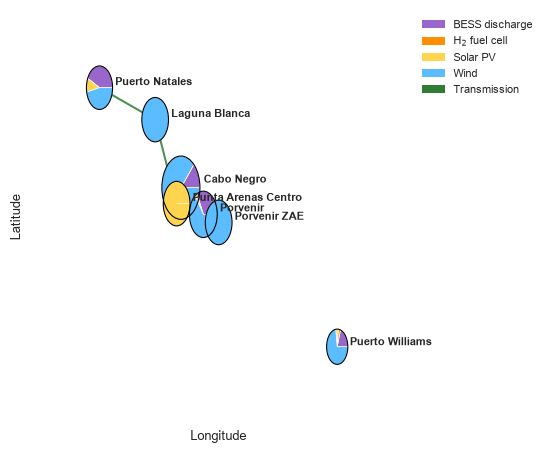


=== NODE COORDINATES USED ===


,zone,label,lat,lon
index,,,,
0,punta_arenas_centro,Punta Arenas Centro,-53.1630,-70.9170
1,cabo_negro,Cabo Negro,-52.9660,-70.8290
2,puerto_natales,Puerto Natales,-51.7290,-72.5060
3,porvenir,Porvenir,-53.2960,-70.3670
4,puerto_williams,Puerto Williams,-54.9340,-67.6090
5,laguna_blanca,Laguna Blanca,-52.1243,-71.3591
6,porvenir_zae,Porvenir ZAE,-53.3960,-70.0510



=== ANNUAL ELECTRIC DISPATCH BY ZONE AND TECHNOLOGY [GWh/yr] ===


plot_technology,bess,diesel,h2_fuel_cell,lpg,ocgt,solar_generic,wind
zone,,,,,,,
cabo_negro,57.97,0.0,0.00,0.0,0.0,0.00,385.25
laguna_blanca,0.00,0.0,0.00,0.0,0.0,0.00,97.33
porvenir,39.71,0.0,0.00,0.0,0.0,2.92,78.89
porvenir_zae,0.00,0.0,0.00,0.0,0.0,0.00,98.63
puerto_natales,37.54,0.0,0.00,0.0,0.0,9.05,40.87
puerto_williams,3.97,0.0,0.69,0.0,0.0,0.75,14.47
punta_arenas_centro,0.00,0.0,0.00,0.0,0.0,98.65,0.00



=== ALL DISPATCH INCLUDING DIAGNOSTIC SLACK [GWh/yr] ===


plot_technology,bess,diesel,h2_fuel_cell,lpg,ocgt,slack,solar_generic,wind
zone,,,,,,,,
cabo_negro,57.9702,0.0,0.0000,0.0,0.0,0.0,0.0000,385.2497
laguna_blanca,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0000,97.3317
porvenir,39.7077,0.0,0.0000,0.0,0.0,0.0,2.9177,78.8948
porvenir_zae,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0000,98.6294
puerto_natales,37.5373,0.0,0.0000,0.0,0.0,0.0,9.0511,40.8698
puerto_williams,3.9740,0.0,0.6945,0.0,0.0,0.0,0.7541,14.4686
punta_arenas_centro,0.0000,0.0,0.0000,0.0,0.0,0.0,98.6509,0.0000


... (2 outputs left out)


=== H2/UHS STORE ENERGY CAPACITY BY ZONE [MWh] ===


,zone,asset,carrier,energy_capacity_mwh
0,cabo_negro,h2_surface_tank_cabo_negro,hydrogen_storage,0.000
1,porvenir,h2_surface_tank_porvenir,hydrogen_storage,0.000
2,puerto_natales,h2_surface_tank_puerto_natales,hydrogen_storage,0.000
3,puerto_williams,h2_surface_tank_puerto_williams,hydrogen_storage,722.613



=== TRANSMISSION CORRIDORS ===


,corridor,link_type,zone0,zone1,capacity_mw,max_abs_net_flow_mw,avg_abs_net_flow_mw,annual_net_flow_gwh_zone0_to_zone1,annual_gross_flow_gwh,simultaneous_opposite_hours,zone0_label,zone1_label
0,tx_punta_arenas_centro_cabo_negro,bidirectional_pair,punta_arenas_centro,cabo_negro,70.803,70.803,43.377,-379.980,379.980,0,Punta Arenas Centro,Cabo Negro
1,tx_punta_arenas_centro_laguna_blanca,bidirectional_pair,punta_arenas_centro,laguna_blanca,33.000,33.000,2.298,15.244,20.129,0,Punta Arenas Centro,Laguna Blanca
2,tx_laguna_blanca_puerto_natales,bidirectional_pair,laguna_blanca,puerto_natales,33.000,33.000,13.048,111.930,114.304,0,Laguna Blanca,Puerto Natales
3,tx_punta_arenas_centro_porvenir,bidirectional_pair,punta_arenas_centro,porvenir,66.000,66.000,10.721,-93.914,93.914,0,Punta Arenas Centro,Porvenir
4,tx_porvenir_porvenir_zae,bidirectional_pair,porvenir,porvenir_zae,229.081,229.081,11.259,-98.629,98.629,0,Porvenir,Porvenir ZAE


In [10]:
# ─────────────────────────────────────────────────────────────────────────────
# Georeferenced node map with dispatch pies and transmission corridors
# ─────────────────────────────────────────────────────────────────────────────
import folium
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch, Circle
from IPython.display import display, FileLink

# ── User controls ────────────────────────────────────────────────────────────
MAP_WIDTH = "760px"
MAP_HEIGHT = "1200px"
MAP_ZOOM = 11

SAVE_INTERACTIVE_HTML = True
SAVE_STATIC_PNG = True

map_year = detailed_year if "detailed_year" in globals() else int(n.snapshots[0].year)

map_output_dir = (
    PAPER_FIGURE_DIR / "maps"
    if "PAPER_FIGURE_DIR" in globals()
    else Path("paper_figures") / "maps"
)
map_output_dir.mkdir(parents=True, exist_ok=True)

# ── Colours ─────────────────────────────────────────────────────────────────
if "TECH_COLORS" not in globals():
    TECH_COLORS = {
        "wind": "#5bbcff",
        "solar": "#ffd54f",
        "solar_utility": "#f4c430",
        "solar_residential": "#ffe082",
        "solar_generic": "#ffd54f",
        "ocgt": "#b85c5c",
        "bess": "#9966cc",
        "slack": "#d32f2f",
        "ptx_shortfall": "#d32f2f",
        "natural_gas": "#bdbdbd",
        "gas": "#bdbdbd",
        "electrolyzer": "#00897b",
        "h2_fuel_cell": "#ff8f00",
        "h2_turbine": "#6d4c41",
        "hydrogen_storage": "#26a69a",
        "uhs_storage": "#8e24aa",
        "transmission": "#2e7d32",
    }

TECH_LABELS = {
    "wind": "Wind",
    "solar": "Solar PV",
    "solar_utility": "Utility solar",
    "solar_residential": "Residential solar",
    "solar_generic": "Solar PV",
    "ocgt": "Thermal",
    "diesel": "Diesel",
    "lpg": "LPG",
    "bess": "BESS discharge",
    "h2_fuel_cell": "H$_2$ fuel cell",
    "h2_turbine": "H$_2$ turbine",
    "slack": "Electricity slack",
    "ptx_shortfall": "PtX shortfall",
}

EXCLUDE_FROM_NODE_SIZE = {"slack", "ptx_shortfall"}


# ── Helper functions ────────────────────────────────────────────────────────
def html_escape(x):
    return str(x).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")


def pretty_zone_label(zone):
    zone = str(zone).strip()

    manual = {
        "punta_arenas_centro": "Punta Arenas Centro",
        "cabo_negro": "Cabo Negro",
        "porvenir_zae": "Porvenir ZAE",
        "puerto_tranquilo_sur": "Puerto Tranquilo Sur",
        "southern_coastal_sensitivity": "Southern Coastal Sensitivity",
    }
    if zone in manual:
        return manual[zone]

    return zone.replace("_", " ").title()


def pretty_tech_label(tech):
    return TECH_LABELS.get(str(tech), str(tech).replace("_", " ").title())


def _clean_zone_from_bus(bus):
    return (
        str(bus)
        .replace("elec_", "")
        .replace("h2_", "")
        .replace("uhs_", "")
        .replace("ch3oh_", "")
        .replace("nh3_", "")
        .replace("co2_", "")
        .replace("n2_", "")
    )


def _capacity_from_row(row, opt_col="p_nom_opt", fixed_col="p_nom"):
    if opt_col in row.index and pd.notna(row.get(opt_col)):
        return float(row.get(opt_col))
    if fixed_col in row.index and pd.notna(row.get(fixed_col)):
        return float(row.get(fixed_col))
    return 0.0


def _energy_capacity_from_row(row, opt_col="e_nom_opt", fixed_col="e_nom"):
    if opt_col in row.index and pd.notna(row.get(opt_col)):
        return float(row.get(opt_col))
    if fixed_col in row.index and pd.notna(row.get(fixed_col)):
        return float(row.get(fixed_col))
    return 0.0


def classify_generation_asset(asset_name, carrier):
    name = str(asset_name).lower()
    carrier = str(carrier).lower()

    if carrier == "solar":
        return "solar_generic"  # every solar candidate of Magallanes is distributed

    if carrier in ["wind", "ocgt", "bess", "slack", "natural_gas", "gas"]:
        return carrier

    return carrier


def get_nodes_coordinates():
    nodes_table = None

    if "all_results" in globals() and map_year in all_results:
        nodes_table = all_results[map_year].get("nodes")

    if nodes_table is None and "nodes_df" in globals():
        nodes_table = nodes_df

    if nodes_table is None:
        candidate_paths = [
            Path(case_folder) / "nodes.csv" if "case_folder" in globals() else None,
            Path("nodes.csv"),
        ]
        for p in candidate_paths:
            if p is not None and p.exists():
                nodes_table = pd.read_csv(p, comment="#")
                break

    if nodes_table is None:
        raise ValueError("Could not find nodes table. Load all_results or provide nodes.csv.")

    nodes_table = nodes_table.copy()

    if "enabled" in nodes_table.columns:
        nodes_table = nodes_table[
            nodes_table["enabled"].astype(str).str.lower().isin(["true", "1", "yes"])
        ].copy()

    required = {"zone", "lat", "lon"}
    missing = required - set(nodes_table.columns)
    if missing:
        raise ValueError(f"nodes table is missing required columns: {missing}")

    coords = {}
    for _, row in nodes_table.iterrows():
        zone = str(row["zone"]).strip()
        lat = float(row["lat"])
        lon = float(row["lon"])
        if np.isfinite(lat) and np.isfinite(lon):
            coords[zone] = (lat, lon)

    if not coords:
        raise ValueError("No valid lat/lon coordinates found in nodes table.")

    return coords, nodes_table


def build_dispatch_by_zone(net):
    """
    Annual electricity dispatch by zone and technology [GWh/yr].

    Marker size and pies use real dispatched energy, excluding artificial
    slack-like components. Slack is still reported separately in the popup.
    """
    rows = []

    # Generator dispatch
    if not net.generators.empty and not net.generators_t.p.empty:
        for gen_id, row in net.generators.iterrows():
            if gen_id not in net.generators_t.p.columns:
                continue

            zone = _clean_zone_from_bus(row.get("bus", ""))
            carrier = str(row.get("carrier", ""))
            tech_plot = classify_generation_asset(gen_id, carrier)
            energy_gwh = float(net.generators_t.p[gen_id].clip(lower=0.0).sum() / 1e3)

            rows.append({
                "zone": zone,
                "asset": gen_id,
                "asset_type": "generator",
                "carrier": carrier,
                "plot_technology": tech_plot,
                "energy_gwh": energy_gwh,
            })

    # BESS discharge
    if not net.storage_units.empty and not net.storage_units_t.p.empty:
        for su_id, row in net.storage_units.iterrows():
            if su_id not in net.storage_units_t.p.columns:
                continue

            zone = _clean_zone_from_bus(row.get("bus", ""))
            carrier = str(row.get("carrier", "bess"))
            energy_gwh = float(net.storage_units_t.p[su_id].clip(lower=0.0).sum() / 1e3)

            rows.append({
                "zone": zone,
                "asset": su_id,
                "asset_type": "storage_unit",
                "carrier": carrier,
                "plot_technology": "bess",
                "energy_gwh": energy_gwh,
            })

    # Electricity output from H2-to-power links
    if not net.links.empty and not net.links_t.p0.empty:
        for link_id, row in net.links.iterrows():
            carrier = str(row.get("carrier", ""))

            if carrier not in ["h2_fuel_cell", "h2_turbine"]:
                continue
            if link_id not in net.links_t.p0.columns:
                continue

            zone = _clean_zone_from_bus(row.get("bus1", ""))
            efficiency = float(row.get("efficiency", 1.0))
            energy_gwh = float((net.links_t.p0[link_id].clip(lower=0.0) * efficiency).sum() / 1e3)

            rows.append({
                "zone": zone,
                "asset": link_id,
                "asset_type": "link",
                "carrier": carrier,
                "plot_technology": carrier,
                "energy_gwh": energy_gwh,
            })

    dispatch_assets = pd.DataFrame(rows)

    if dispatch_assets.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    dispatch_by_zone_all = (
        dispatch_assets
        .groupby(["zone", "plot_technology"], as_index=False)["energy_gwh"]
        .sum()
        .pivot(index="zone", columns="plot_technology", values="energy_gwh")
        .fillna(0.0)
    )

    dispatch_by_zone_plot = dispatch_by_zone_all.drop(
        columns=[c for c in EXCLUDE_FROM_NODE_SIZE if c in dispatch_by_zone_all.columns],
        errors="ignore",
    )

    slack_by_zone = dispatch_by_zone_all[
        [c for c in EXCLUDE_FROM_NODE_SIZE if c in dispatch_by_zone_all.columns]
    ].copy() if any(c in dispatch_by_zone_all.columns for c in EXCLUDE_FROM_NODE_SIZE) else pd.DataFrame(index=dispatch_by_zone_all.index)

    return dispatch_by_zone_plot, dispatch_by_zone_all, dispatch_assets


def build_h2_store_by_zone(net):
    rows = []

    for store_id, row in net.stores.iterrows():
        carrier = str(row.get("carrier", ""))
        if carrier not in ["hydrogen_storage", "uhs_storage"]:
            continue

        zone = _clean_zone_from_bus(row.get("bus", ""))
        e_cap = _energy_capacity_from_row(row, "e_nom_opt", "e_nom")

        rows.append({
            "zone": zone,
            "asset": store_id,
            "carrier": carrier,
            "energy_capacity_mwh": e_cap,
        })

    return pd.DataFrame(rows)


def get_transmission_corridors(net):
    if len(net.links) == 0:
        return pd.DataFrame(), {}

    tx_links = net.links[
        (net.links["carrier"].astype(str) == "electricity")
        & net.links["bus0"].astype(str).str.startswith("elec_")
        & net.links["bus1"].astype(str).str.startswith("elec_")
    ].copy()

    if tx_links.empty:
        return pd.DataFrame(), {}

    p0 = net.links_t.p0.reindex(columns=tx_links.index, fill_value=0.0)

    rows = []
    series_dict = {}
    used = set()

    for link_id in tx_links.index:
        link_id_str = str(link_id)

        if not link_id_str.endswith("_fwd"):
            continue

        base = link_id_str[:-4]
        rev = f"{base}_rev"

        if rev not in tx_links.index:
            continue

        fwd_flow = p0[link_id].clip(lower=0.0)
        rev_flow = p0[rev].clip(lower=0.0)
        net_flow = fwd_flow - rev_flow
        gross_flow = fwd_flow + rev_flow

        cap = _capacity_from_row(tx_links.loc[link_id], "p_nom_opt", "p_nom")

        zone0 = _clean_zone_from_bus(tx_links.loc[link_id, "bus0"])
        zone1 = _clean_zone_from_bus(tx_links.loc[link_id, "bus1"])

        simultaneous_hours = int(((fwd_flow > 1e-6) & (rev_flow > 1e-6)).sum())

        rows.append({
            "corridor": base,
            "link_type": "bidirectional_pair",
            "zone0": zone0,
            "zone1": zone1,
            "capacity_mw": cap,
            "max_abs_net_flow_mw": float(net_flow.abs().max()),
            "avg_abs_net_flow_mw": float(net_flow.abs().mean()),
            "annual_net_flow_gwh_zone0_to_zone1": float(net_flow.sum() / 1e3),
            "annual_gross_flow_gwh": float(gross_flow.sum() / 1e3),
            "simultaneous_opposite_hours": simultaneous_hours,
        })

        series_dict[base] = pd.DataFrame({
            "fwd_mw": fwd_flow,
            "rev_mw": rev_flow,
            "net_mw": net_flow,
            "gross_mw": gross_flow,
        })

        used.add(link_id)
        used.add(rev)

    for link_id, row in tx_links.iterrows():
        if link_id in used:
            continue

        flow = p0[link_id].clip(lower=0.0)
        cap = _capacity_from_row(row, "p_nom_opt", "p_nom")
        zone0 = _clean_zone_from_bus(row["bus0"])
        zone1 = _clean_zone_from_bus(row["bus1"])

        rows.append({
            "corridor": str(link_id),
            "link_type": "directed",
            "zone0": zone0,
            "zone1": zone1,
            "capacity_mw": cap,
            "max_abs_net_flow_mw": float(flow.max()),
            "avg_abs_net_flow_mw": float(flow.mean()),
            "annual_net_flow_gwh_zone0_to_zone1": float(flow.sum() / 1e3),
            "annual_gross_flow_gwh": float(flow.sum() / 1e3),
            "simultaneous_opposite_hours": np.nan,
        })

        series_dict[str(link_id)] = pd.DataFrame({
            "net_mw": flow,
            "gross_mw": flow,
        })

    return pd.DataFrame(rows), series_dict


def _svg_pie(values, colors, size_px=46):
    """Return inline SVG pie chart for folium DivIcon."""
    values = np.asarray(values, dtype=float)
    total = values.sum()

    size = int(size_px)
    cx = cy = size / 2
    r = size / 2 - 2

    if total <= 1e-9:
        return f"""
        <svg width="{size}" height="{size}" viewBox="0 0 {size} {size}">
            <circle cx="{cx}" cy="{cy}" r="{r}" fill="#f0f0f0" stroke="#222" stroke-width="1.6"/>
        </svg>
        """

    paths = []
    start = -90.0

    for value, color in zip(values, colors):
        if value <= 1e-9:
            continue

        angle = 360.0 * value / total
        end = start + angle
        large_arc = 1 if angle > 180 else 0

        x1 = cx + r * np.cos(np.deg2rad(start))
        y1 = cy + r * np.sin(np.deg2rad(start))
        x2 = cx + r * np.cos(np.deg2rad(end))
        y2 = cy + r * np.sin(np.deg2rad(end))

        d = f"M {cx:.3f} {cy:.3f} L {x1:.3f} {y1:.3f} A {r:.3f} {r:.3f} 0 {large_arc} 1 {x2:.3f} {y2:.3f} Z"
        paths.append(f'<path d="{d}" fill="{color}" stroke="white" stroke-width="0.8"/>')

        start = end

    return f"""
    <svg width="{size}" height="{size}" viewBox="0 0 {size} {size}">
        {''.join(paths)}
        <circle cx="{cx}" cy="{cy}" r="{r}" fill="none" stroke="#222" stroke-width="1.6"/>
    </svg>
    """


def _folium_pie_marker(lat, lon, values, colors, size_px, popup, tooltip):
    svg = _svg_pie(values, colors, size_px=size_px)
    html = f"""
    <div style="
        width:{size_px}px;
        height:{size_px}px;
        transform: translate(-{size_px/2}px, -{size_px/2}px);
    ">
        {svg}
    </div>
    """
    folium.Marker(
        location=[lat, lon],
        popup=folium.Popup(popup, max_width=360),
        tooltip=tooltip,
        icon=folium.DivIcon(
            html=html,
            icon_size=(size_px, size_px),
            icon_anchor=(size_px / 2, size_px / 2),
        ),
    ).add_to(m)


def _node_popup(zone, dispatch_row_plot, dispatch_row_all, h2_store_table):
    zone_label = pretty_zone_label(zone)
    total_plot = float(dispatch_row_plot.sum())
    total_all = float(dispatch_row_all.sum())

    popup = f"<b>{html_escape(zone_label)}</b><br>"
    popup += f"Annual electric dispatch shown: {total_plot:.1f} GWh/yr<br>"

    slack_cols = [c for c in EXCLUDE_FROM_NODE_SIZE if c in dispatch_row_all.index]
    slack_total = float(dispatch_row_all[slack_cols].sum()) if slack_cols else 0.0
    if slack_total > 1e-6:
        popup += f"<span style='color:#b00020;'>Diagnostic slack: {slack_total:.3f} GWh/yr</span><br>"

    popup += "<br><b>Dispatch by technology</b><br>"
    for tech, value in dispatch_row_plot.sort_values(ascending=False).items():
        if value > 1e-6:
            popup += f"{html_escape(pretty_tech_label(tech))}: {float(value):.1f} GWh/yr<br>"

    if not h2_store_table.empty:
        stores_z = h2_store_table[h2_store_table["zone"] == zone]
        if not stores_z.empty:
            popup += "<br><b>H₂/UHS stores</b><br>"
            for _, st in stores_z.iterrows():
                if st["energy_capacity_mwh"] > 1e-6:
                    popup += (
                        f"{html_escape(pretty_tech_label(st['carrier']))}: "
                        f"{float(st['energy_capacity_mwh']) / 1e3:.2f} GWh<br>"
                    )

    return popup


# ── Build map data ──────────────────────────────────────────────────────────
coords, nodes_table = get_nodes_coordinates()
dispatch_by_zone, dispatch_by_zone_all, dispatch_asset_table = build_dispatch_by_zone(n)
h2_store_table = build_h2_store_by_zone(n)
tx_table, tx_series = get_transmission_corridors(n)

all_zones = sorted(set(coords.keys()) | set(dispatch_by_zone.index.astype(str)))

missing_coords = [z for z in all_zones if z not in coords]
if missing_coords:
    raise ValueError(
        "These model zones do not have coordinates in nodes.csv: "
        f"{missing_coords}. Add lat/lon to nodes.csv rather than using fake locations."
    )

dispatch_by_zone = dispatch_by_zone.reindex(all_zones, fill_value=0.0)
dispatch_by_zone_all = dispatch_by_zone_all.reindex(all_zones, fill_value=0.0)

active_techs = [
    c for c in dispatch_by_zone.columns
    if float(dispatch_by_zone[c].sum()) > 1e-6
]

if not active_techs:
    active_techs = ["no_dispatch"]

center_lat = float(np.mean([coords[z][0] for z in all_zones]))
center_lon = float(np.mean([coords[z][1] for z in all_zones]))

max_dispatch = max(float(dispatch_by_zone.sum(axis=1).max()), 1e-9)

# ── Create interactive map ──────────────────────────────────────────────────
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=MAP_ZOOM,
    tiles=None,
    control_scale=True,
    width=MAP_WIDTH,
    height=MAP_HEIGHT,
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Satellite (Esri)",
    overlay=False,
    control=True,
).add_to(m)

folium.TileLayer(
    "OpenStreetMap",
    name="Streets (OSM)",
    overlay=False,
    control=True,
).add_to(m)

# Transmission corridors
if not tx_table.empty:
    for _, row in tx_table.iterrows():
        z0 = row["zone0"]
        z1 = row["zone1"]

        if z0 not in coords or z1 not in coords:
            continue

        lat0, lon0 = coords[z0]
        lat1, lon1 = coords[z1]

        cap = float(row["capacity_mw"])
        avg_abs_flow = float(row["avg_abs_net_flow_mw"])
        annual_net = float(row["annual_net_flow_gwh_zone0_to_zone1"])
        simultaneous = row.get("simultaneous_opposite_hours", np.nan)

        weight = max(2.0, min(8.0, 2.0 + cap / 100.0))

        popup = (
            f"<b>{html_escape(row['corridor'])}</b><br>"
            f"{html_escape(pretty_zone_label(z0))} → {html_escape(pretty_zone_label(z1))}<br>"
            f"Capacity: {cap:.1f} MW<br>"
            f"Avg |net flow|: {avg_abs_flow:.1f} MW<br>"
            f"Annual net flow: {annual_net:.1f} GWh<br>"
            f"Annual gross flow: {float(row['annual_gross_flow_gwh']):.1f} GWh<br>"
        )

        if pd.notna(simultaneous):
            popup += f"Simultaneous opposite-flow hours: {int(simultaneous)}<br>"

        folium.PolyLine(
            locations=[[lat0, lon0], [lat1, lon1]],
            color=TECH_COLORS.get("transmission", "#2e7d32"),
            weight=weight,
            opacity=0.85,
            popup=folium.Popup(popup, max_width=350),
            tooltip=f"{pretty_zone_label(z0)} – {pretty_zone_label(z1)} | {cap:.0f} MW",
        ).add_to(m)

# Dispatch pie markers
for zone in all_zones:
    lat, lon = coords[zone]

    row_plot = dispatch_by_zone.loc[zone]
    row_all = dispatch_by_zone_all.loc[zone]
    total_dispatch = float(row_plot.sum())

    values = row_plot.reindex(active_techs, fill_value=0.0).values
    colors = [TECH_COLORS.get(t, "#9e9e9e") for t in active_techs]

    size_px = int(28 + 34 * np.sqrt(total_dispatch / max_dispatch)) if total_dispatch > 1e-9 else 26

    popup = _node_popup(zone, row_plot, row_all, h2_store_table)
    tooltip = f"{pretty_zone_label(zone)} | {total_dispatch:.1f} GWh/yr"

    _folium_pie_marker(
        lat=lat,
        lon=lon,
        values=values,
        colors=colors,
        size_px=size_px,
        popup=popup,
        tooltip=tooltip,
    )

    # Permanent text label
    folium.map.Marker(
        [lat, lon],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 12px;
                font-weight: 600;
                color: white;
                text-shadow: 1px 1px 2px black;
                transform: translate(14px, -9px);
                white-space: nowrap;">
                {html_escape(pretty_zone_label(zone))}
            </div>
            """
        ),
    ).add_to(m)

# Legend
legend_items_html = ""
for tech in active_techs:
    legend_items_html += (
        f'<i style="background:{TECH_COLORS.get(tech, "#9e9e9e")}; '
        f'width: 12px; height: 12px; display: inline-block;"></i> '
        f'{html_escape(pretty_tech_label(tech))}<br>'
    )

legend_html = f"""
<div style="position: fixed; bottom: 28px; right: 28px; width: 250px; z-index:9999;
            background: white; border:1.6px solid #444; border-radius:8px;
            padding:9px; font-size:12px;">
<b>Annual electric dispatch</b><br>
{legend_items_html}
<i style="background:{TECH_COLORS.get("transmission", "#2e7d32")};
          width: 24px; height: 4px; display: inline-block;"></i> Transmission<br><br>
<b>Pie size:</b> total dispatch shown<br>
<b>Line width:</b> transmission capacity<br>
<span style="font-size:10px;">Slack and PtX shortfall are excluded from pie size.</span>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

folium.LayerControl(collapsed=True).add_to(m)

display(m)

# Save interactive map
if SAVE_INTERACTIVE_HTML:
    html_path = map_output_dir / f"system_map_dispatch_pies_{map_year}.html"
    m.save(str(html_path))
    display(FileLink(str(html_path), result_html_prefix="Download interactive map: "))


# ── Static PNG version for paper ────────────────────────────────────────────
def save_static_dispatch_map():
    fig, ax = plt.subplots(figsize=(6.5, 4.6))

    # Transmission corridors
    if not tx_table.empty:
        for _, row in tx_table.iterrows():
            z0 = row["zone0"]
            z1 = row["zone1"]

            if z0 not in coords or z1 not in coords:
                continue

            lat0, lon0 = coords[z0]
            lat1, lon1 = coords[z1]
            cap = float(row["capacity_mw"])
            width = max(1.2, min(4.5, 1.2 + cap / 120.0))

            ax.plot(
                [lon0, lon1],
                [lat0, lat1],
                color=TECH_COLORS.get("transmission", "#2e7d32"),
                linewidth=width,
                alpha=0.85,
                zorder=1,
            )

    # Dispatch pies
    max_dispatch_local = max(float(dispatch_by_zone.sum(axis=1).max()), 1e-9)
    lon_span = max([coords[z][1] for z in all_zones]) - min([coords[z][1] for z in all_zones])
    lat_span = max([coords[z][0] for z in all_zones]) - min([coords[z][0] for z in all_zones])
    span = max(lon_span, lat_span, 0.05)

    for zone in all_zones:
        lat, lon = coords[zone]
        row_plot = dispatch_by_zone.loc[zone]
        total_dispatch = float(row_plot.sum())

        values = row_plot.reindex(active_techs, fill_value=0.0).values
        colors = [TECH_COLORS.get(t, "#9e9e9e") for t in active_techs]

        radius = span * (0.035 + 0.045 * np.sqrt(total_dispatch / max_dispatch_local))

        if total_dispatch > 1e-9:
            ax.pie(
                values,
                colors=colors,
                radius=radius,
                center=(lon, lat),
                wedgeprops=dict(edgecolor="white", linewidth=0.5),
            )
            ax.add_patch(
                Circle(
                    (lon, lat),
                    radius,
                    edgecolor="black",
                    facecolor="none",
                    linewidth=0.8,
                    zorder=5,
                )
            )
        else:
            ax.add_patch(
                Circle(
                    (lon, lat),
                    radius * 0.65,
                    edgecolor="black",
                    facecolor="#f0f0f0",
                    linewidth=0.8,
                    zorder=5,
                )
            )

        ax.text(
            lon + radius * 1.2,
            lat + radius * 0.25,
            pretty_zone_label(zone),
            fontsize=8,
            fontweight="semibold",
            ha="left",
            va="center",
            zorder=6,
        )

    # Legend
    handles = [
        Patch(facecolor=TECH_COLORS.get(t, "#9e9e9e"), label=pretty_tech_label(t))
        for t in active_techs
    ]
    handles.append(
        Patch(facecolor=TECH_COLORS.get("transmission", "#2e7d32"), label="Transmission")
    )

    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        frameon=False,
        fontsize=8,
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(True, alpha=0.18, linewidth=0.5)
    ax.set_axisbelow(True)

    lat_mean = np.mean([coords[z][0] for z in all_zones])
    ax.set_aspect(1 / np.cos(np.deg2rad(lat_mean)))

    margin_lon = max(lon_span * 0.30, 0.015)
    margin_lat = max(lat_span * 0.30, 0.015)

    ax.set_xlim(
        min([coords[z][1] for z in all_zones]) - margin_lon,
        max([coords[z][1] for z in all_zones]) + margin_lon,
    )
    ax.set_ylim(
        min([coords[z][0] for z in all_zones]) - margin_lat,
        max([coords[z][0] for z in all_zones]) + margin_lat,
    )

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    plt.tight_layout()

    png_path = map_output_dir / f"system_map_dispatch_pies_{map_year}.png"
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    plt.show()

    display(FileLink(str(png_path), result_html_prefix="Download static PNG: "))
    return png_path


if SAVE_STATIC_PNG:
    save_static_dispatch_map()


# ── Tables ─────────────────────────────────────────────────────────────────
print("\n=== NODE COORDINATES USED ===")
nodes_display = nodes_table.copy()
nodes_display["label"] = nodes_display["zone"].map(pretty_zone_label)
display(nodes_display[["zone", "label", "lat", "lon"]].round(5))

print("\n=== ANNUAL ELECTRIC DISPATCH BY ZONE AND TECHNOLOGY [GWh/yr] ===")
display(dispatch_by_zone.round(2))

print("\n=== ALL DISPATCH INCLUDING DIAGNOSTIC SLACK [GWh/yr] ===")
display(dispatch_by_zone_all.round(4))

print("\n=== ASSET-TO-NODE DISPATCH ASSIGNMENT [GWh/yr] ===")
if not dispatch_asset_table.empty:
    display(
        dispatch_asset_table
        .sort_values(["zone", "asset_type", "plot_technology", "asset"])
        .reset_index(drop=True)
        .round(4)
    )
else:
    print("No generation/storage dispatch found.")

print("\n=== H2/UHS STORE ENERGY CAPACITY BY ZONE [MWh] ===")
if not h2_store_table.empty:
    display(
        h2_store_table
        .sort_values(["zone", "carrier", "asset"])
        .reset_index(drop=True)
        .round(3)
    )
else:
    print("No H2/UHS stores found.")

print("\n=== TRANSMISSION CORRIDORS ===")
if not tx_table.empty:
    tx_display = tx_table.copy()
    tx_display["zone0_label"] = tx_display["zone0"].map(pretty_zone_label)
    tx_display["zone1_label"] = tx_display["zone1"].map(pretty_zone_label)
    display(tx_display.round(3))
else:
    print("No electricity transmission links found.")

## 6. Cross-scenario figures and flexibility table


Saved figure: output\output_magallanes\figures\figure_cross_scenario_generation_cost_2030_2050.png


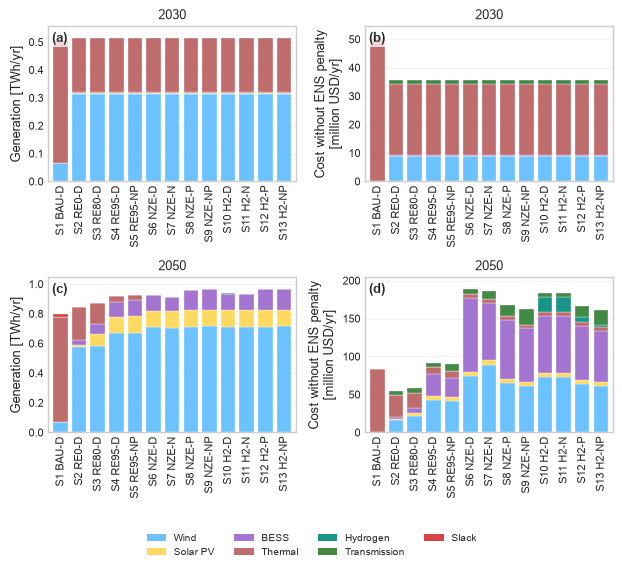

In [11]:
# Cross-scenario generation and cost figure
comparison_years = [year for year in [2030, 2050] if year in years]

def _norm_carrier(x):
    return str(x).strip().lower().replace(" ", "_").replace("-", "_")


def format_scenario_axis(ax, x, labels):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=6.5)
    ax.tick_params(axis="x", pad=3)


def build_generation_group_df(df_year):
    """
    Annual electricity generation / dispatch by broad technology group [TWh/yr].

    Reconstructed directly from each optimized PyPSA network.
    """
    out = pd.DataFrame(0.0, index=df_year.index, columns=TECH_GROUPS)

    for idx, row in df_year.iterrows():
        scenario_code = row["scenario"]
        year = int(row["year"])
        net = scenario_results[scenario_code]["results"][year]["network"]

        try:
            weights = pd.Series(net.snapshot_weightings.objective, index=net.snapshots).astype(float)
        except Exception:
            weights = pd.Series(1.0, index=net.snapshots)

        # Generators
        if hasattr(net, "generators") and len(net.generators) > 0:
            p_gen = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0).clip(lower=0.0)

            for asset in net.generators.index:
                carrier = _norm_carrier(net.generators.loc[asset, "carrier"]) if "carrier" in net.generators.columns else ""
                group = GENERATOR_CARRIER_GROUP.get(carrier)

                energy_mwh = float((p_gen[asset] * weights).sum())

                if energy_mwh <= 1e-6:
                    continue

                if group is None:
                    group = "Other"

                out.loc[idx, group] += energy_mwh / 1e6

        # Storage-unit discharge
        if hasattr(net, "storage_units") and len(net.storage_units) > 0:
            p_su = net.storage_units_t.p.reindex(columns=net.storage_units.index, fill_value=0.0).clip(lower=0.0)

            for asset in net.storage_units.index:
                carrier = _norm_carrier(net.storage_units.loc[asset, "carrier"]) if "carrier" in net.storage_units.columns else ""
                group = STORAGE_UNIT_CARRIER_GROUP.get(carrier)

                energy_mwh = float((p_su[asset] * weights).sum())

                if energy_mwh <= 1e-6:
                    continue

                if group is None:
                    group = "Other"

                out.loc[idx, group] += energy_mwh / 1e6

        # Electricity-producing links
        if hasattr(net, "links") and len(net.links) > 0:
            for asset in net.links.index:
                carrier = _norm_carrier(net.links.loc[asset, "carrier"]) if "carrier" in net.links.columns else ""
                group = ELECTRICITY_OUTPUT_LINK_GROUP.get(carrier)

                if group is None:
                    continue

                # Link outputs are negative at output ports in PyPSA.
                output_candidates = []

                for port in ["p1", "p2", "p3", "p4"]:
                    if hasattr(net.links_t, port):
                        p = getattr(net.links_t, port)
                        if asset in p.columns:
                            s = (-p[asset]).clip(lower=0.0)
                            output_candidates.append(s)

                if not output_candidates:
                    continue

                output = max(output_candidates, key=lambda s: float((s * weights).sum()))
                energy_mwh = float((output * weights).sum())

                if energy_mwh <= 1e-6:
                    continue

                out.loc[idx, group] += energy_mwh / 1e6

    return out[TECH_GROUPS]


def build_cost_group_df(df_year):
    """
    Build system cost by broad technology group [million USD/yr],
    reconstructed directly from scenario_results.
    """
    out = pd.DataFrame(0.0, index=df_year.index, columns=TECH_GROUPS)

    for idx, row in df_year.iterrows():
        scenario_code = row["scenario"]
        year = int(row["year"])

        net = scenario_results[scenario_code]["results"][year]["network"]
        costs = estimate_cost_breakdown_from_network(net)
        if costs.empty:
            continue

        grouped = costs.groupby("group")["total_cost"].sum()

        for group, value in grouped.items():
            if group == "Slack":  # penalty of unserved energy, not a cost
                continue
            if group not in out.columns:
                out.loc[idx, "Other"] += float(value)
            else:
                out.loc[idx, group] += float(value)

    return out[TECH_GROUPS] / 1e6


def plot_stacked_bars(ax, stack_df, groups, colors, labels, ylabel):
    """Plot a stacked bar chart and return the displayed groups."""
    x = np.arange(len(stack_df))
    bottom = np.zeros(len(stack_df))
    plotted_groups = []

    for group in groups:
        if group not in stack_df.columns:
            continue
        values = stack_df[group].fillna(0.0).values
        if np.allclose(values.sum(), 0.0):
            continue
        ax.bar(
            x,
            values,
            bottom=bottom,
            width=0.78,
            color=colors.get(group, "#999999"),
            alpha=0.90,
            label=group,
            edgecolor="white",
            linewidth=0.25,
        )
        bottom += values
        plotted_groups.append(group)

    format_scenario_axis(ax, x, labels)
    finish_axis(ax, ylabel=ylabel)
    ax.grid(False)
    ax.yaxis.grid(True, alpha=0.22)
    ax.set_axisbelow(True)
    ax.set_xlim(-0.65, len(stack_df) - 0.35)
    if len(bottom) and bottom.max() > 0.0:
        ax.set_ylim(0.0, 1.08 * bottom.max())
    return plotted_groups


if not comparison_years:
    raise ValueError("None of the requested comparison years are available.")

nrows = len(comparison_years)
fig, axes = plt.subplots(
    nrows,
    2,
    figsize=(WORD_DOUBLE_COL_IN, 2.9 * nrows),
    squeeze=False,
)

used_groups = set()

for row_i, year in enumerate(comparison_years):
    df_y = scenario_comparison[scenario_comparison["year"] == year].copy()

    df_y = df_y[df_y["scenario"].isin(SCENARIO_TECH_LABELS.keys())].copy()

    if df_y.empty:
        raise ValueError(f"No selected scenarios found for year {year}.")

    df_y["_order"] = df_y["scenario"].map(SCENARIO_ORDER_RANK)
    df_y = df_y.sort_values("_order").drop(columns="_order").reset_index(drop=True)

    df_y["label"] = df_y["scenario"].map(SCENARIO_TECH_LABELS).fillna(df_y["scenario"].astype(str))

    generation_group_df = build_generation_group_df(df_y)
    cost_group_df = build_cost_group_df(df_y)

    ax_gen = axes[row_i, 0]
    groups = plot_stacked_bars(
        ax_gen,
        generation_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Generation [TWh/yr]",
    )
    used_groups.update(groups)
    panel_label(ax_gen, f"({chr(97 + 2 * row_i)})")
    ax_gen.text(
        0.5,
        1.03,
        str(year),
        transform=ax_gen.transAxes,
        ha="center",
        va="bottom",
        fontsize=9,
        clip_on=False,
    )

    ax_cost = axes[row_i, 1]
    groups = plot_stacked_bars(
        ax_cost,
        cost_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel=COST_AXIS_LABEL,
    )
    used_groups.update(groups)
    panel_label(ax_cost, f"({chr(98 + 2 * row_i)})")
    ax_cost.text(
        0.5,
        1.03,
        str(year),
        transform=ax_cost.transAxes,
        ha="center",
        va="bottom",
        fontsize=9,
        clip_on=False,
    )


# Shared legend
legend_handles = []
legend_labels = []

for group in TECH_GROUPS:
    if group not in used_groups:
        continue

    handle = plt.Rectangle(
        (0, 0),
        1,
        1,
        facecolor=TECH_COLORS_GROUPED.get(group, "#999999"),
        edgecolor="none",
        alpha=0.90,
    )
    legend_handles.append(handle)
    legend_labels.append(group)

fig.legend(
    legend_handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    fontsize=7,
)

plt.tight_layout()
fig.subplots_adjust(top=0.94, bottom=0.36 if nrows == 1 else 0.24, hspace=0.62, wspace=0.28)

years_tag = "_".join(str(year) for year in comparison_years)
fig_path = save_paper_figure(
    fig,
    f"figure_cross_scenario_generation_cost_{years_tag}.png",
)
plt.show()


Saved figure: output\output_magallanes\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2025.png


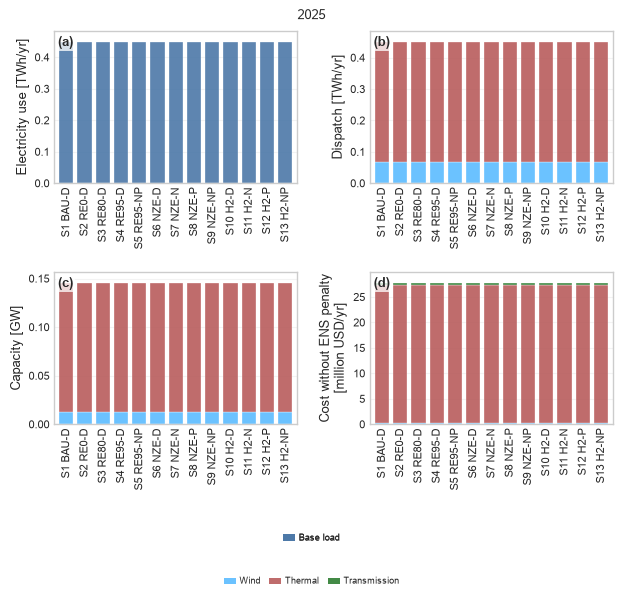

Saved figure: output\output_magallanes\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2030.png


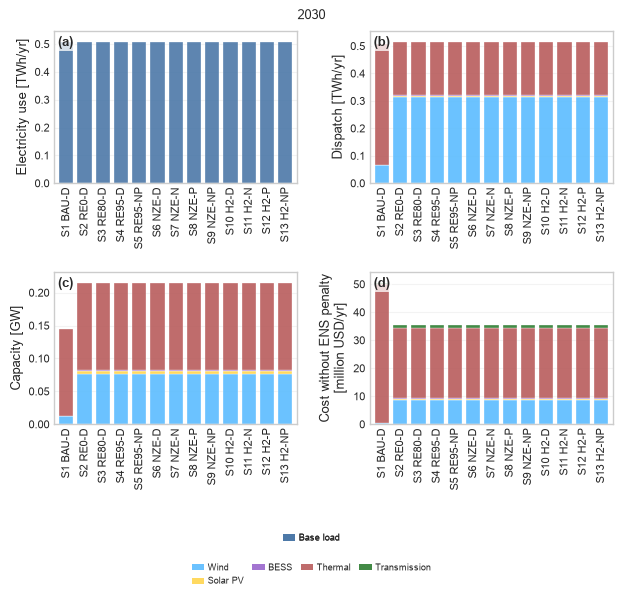

Saved figure: output\output_magallanes\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2040.png


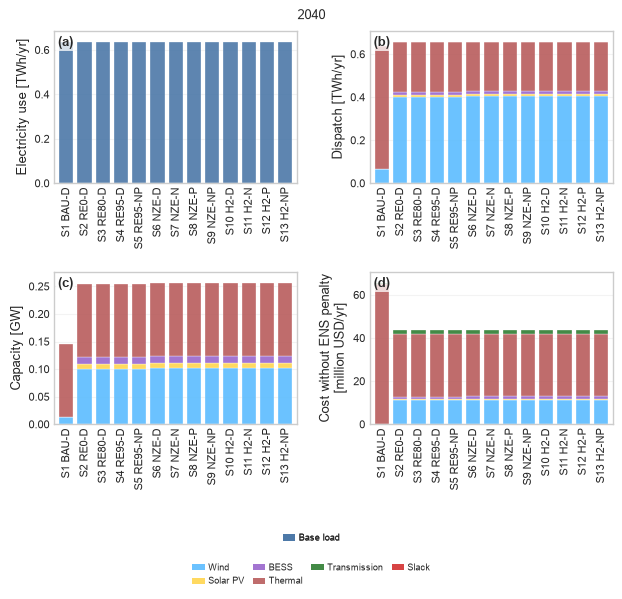

Saved figure: output\output_magallanes\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2045.png


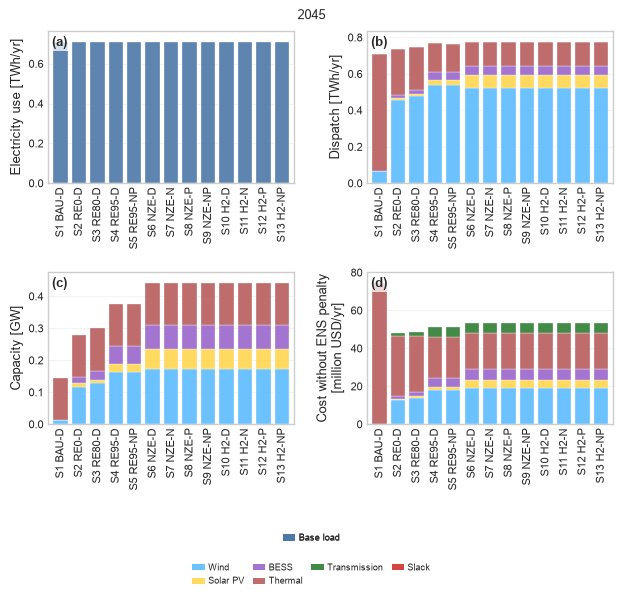

Saved figure: output\output_magallanes\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2050.png


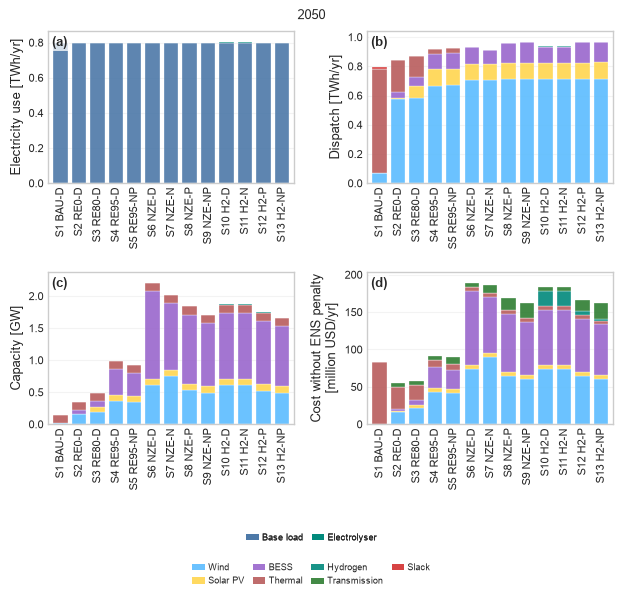

In [12]:
# Supplementary cross-scenario decomposition
cross_scenario_years_to_plot = years
cross_scenario_export_dir = PAPER_FIGURE_DIR / "cross_scenario_all_years"
cross_scenario_export_dir.mkdir(parents=True, exist_ok=True)


def build_demand_group_df(df_year):
    """Build electricity-use decomposition [TWh/yr]."""
    out = pd.DataFrame(index=df_year.index)

    if demand_breakdown_summary.empty:
        raise ValueError("Demand breakdown is empty. Run the previous section first.")

    demand_y = demand_breakdown_summary[
        demand_breakdown_summary["year"] == int(df_year["year"].iloc[0])
    ].copy()
    demand_y = apply_scenario_order(demand_y)
    demand_y = demand_y.set_index("scenario").reindex(df_year["scenario"])

    mapping = {
        "Base load": "demand_base_load_mwh",
        "Heating": "demand_heating_mwh",
        "EVs": "demand_ev_mwh",
        "Cooking": "demand_cooking_mwh",
        "Process electrification": "demand_process_electrification_mwh",
        "Electrolyser": "electrolyser_input_mwh",
        "PtX auxiliaries": "ptx_aux_electricity_mwh",
        "Other local demand": "demand_other_mwh",
    }

    for group, col in mapping.items():
        if col in demand_y.columns:
            out[group] = demand_y[col].fillna(0.0).values / 1e6
        else:
            out[group] = 0.0

    for group in DEMAND_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[DEMAND_GROUPS]


def build_dispatch_group_df(df_year):
    """Build annual electricity dispatch by technology [TWh/yr]."""
    out = pd.DataFrame(index=df_year.index)

    out["Wind"] = df_year.get("generation_wind_mwh", 0.0) / 1e6
    out["Solar PV"] = df_year.get("generation_solar_mwh", 0.0) / 1e6
    out["BESS"] = df_year.get("bess_discharge_mwh", 0.0) / 1e6

    thermal_cols = [
        "generation_ocgt_mwh",
        "generation_gas_mwh",
        "generation_natural_gas_mwh",
        "generation_diesel_mwh",
        "generation_lpg_mwh",
    ]
    valid_thermal_cols = [c for c in thermal_cols if c in df_year.columns]
    out["Thermal"] = (
        df_year[valid_thermal_cols].fillna(0.0).sum(axis=1) / 1e6
        if valid_thermal_cols else 0.0
    )

    if "h2_to_power_mwh" in df_year.columns:
        out["Hydrogen"] = df_year["h2_to_power_mwh"].fillna(0.0) / 1e6
    else:
        h2_cols = ["h2_fuel_cell_output_mwh", "h2_turbine_output_mwh"]
        valid_h2_cols = [c for c in h2_cols if c in df_year.columns]
        out["Hydrogen"] = (
            df_year[valid_h2_cols].fillna(0.0).sum(axis=1) / 1e6
            if valid_h2_cols else 0.0
        )

    out["PtX"] = 0.0
    out["Slack"] = df_year.get("generation_slack_mwh", 0.0) / 1e6
    out["Other"] = 0.0

    for group in TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[TECH_GROUPS]


def build_capacity_group_df(df_year):
    """Build installed capacity by technology [GW]."""
    out = pd.DataFrame(index=df_year.index)

    out["Wind"] = df_year.get("cap_wind_mw", 0.0) / 1e3
    out["Solar PV"] = df_year.get("cap_solar_mw", 0.0) / 1e3
    out["BESS"] = df_year.get("cap_bess_mw", 0.0) / 1e3

    thermal_cols = ["cap_ocgt_mw", "cap_gas_mw", "cap_natural_gas_mw", "cap_diesel_mw", "cap_lpg_mw"]
    valid_thermal_cols = [c for c in thermal_cols if c in df_year.columns]
    out["Thermal"] = (
        df_year[valid_thermal_cols].fillna(0.0).sum(axis=1) / 1e3
        if valid_thermal_cols else 0.0
    )

    hydrogen_cols = [
        "linkcap_electrolyzer_mw",
        "linkcap_h2_fuel_cell_mw",
        "linkcap_h2_turbine_mw",
    ]
    valid_hydrogen_cols = [c for c in hydrogen_cols if c in df_year.columns]
    out["Hydrogen"] = (
        df_year[valid_hydrogen_cols].fillna(0.0).sum(axis=1) / 1e3
        if valid_hydrogen_cols else 0.0
    )

    out["PtX"] = 0.0
    out["Slack"] = 0.0
    out["Other"] = 0.0

    for group in TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[TECH_GROUPS]


def plot_cross_scenario_supplementary(comparison_year, save_figure=True, show_figure=True):
    df_y = scenario_comparison[scenario_comparison["year"] == comparison_year].copy()

    if df_y.empty:
        raise ValueError(f"No scenario comparison data found for {comparison_year}.")

    df_y = apply_scenario_order(df_y).reset_index(drop=True)
    df_y["label"] = df_y["scenario"].map(SCENARIO_TECH_LABELS).fillna(df_y["scenario"].astype(str))

    demand_group_df = build_demand_group_df(df_y)
    dispatch_group_df = build_dispatch_group_df(df_y)
    capacity_group_df = build_capacity_group_df(df_y)
    cost_group_df = build_cost_group_df(df_y)

    fig, axes = plt.subplots(2, 2, figsize=(FIGSIZE_PAPER_2X2[0], FIGSIZE_PAPER_2X2[1] + 1.2))

    used_demand_groups = set()
    used_tech_groups = set()

    used = plot_stacked_bars(
        axes[0, 0],
        demand_group_df,
        DEMAND_GROUPS,
        DEMAND_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Electricity use [TWh/yr]",
    )
    used_demand_groups.update(used)
    panel_label(axes[0, 0], "(a)")

    used = plot_stacked_bars(
        axes[0, 1],
        dispatch_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Dispatch [TWh/yr]",
    )
    used_tech_groups.update(used)
    panel_label(axes[0, 1], "(b)")

    used = plot_stacked_bars(
        axes[1, 0],
        capacity_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Capacity [GW]",
    )
    used_tech_groups.update(used)
    panel_label(axes[1, 0], "(c)")

    used = plot_stacked_bars(
        axes[1, 1],
        cost_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel=COST_AXIS_LABEL,
    )
    used_tech_groups.update(used)
    panel_label(axes[1, 1], "(d)")

    fig.text(
        0.5,
        0.975,
        str(comparison_year),
        ha="center",
        va="top",
        fontsize=9,
    )

    # Figure-level legends
    demand_handles = []
    demand_labels = []
    for group in DEMAND_GROUPS:
        if group not in used_demand_groups:
            continue

        demand_handles.append(
            plt.Rectangle(
                (0, 0), 1, 1,
                facecolor=DEMAND_COLORS_GROUPED.get(group, "#999999"),
                edgecolor="none",
                alpha=0.90,
            )
        )
        demand_labels.append(DEMAND_LEGEND_LABELS.get(group, group))

    tech_handles = []
    tech_labels = []

    for group in TECH_GROUPS:
        if group not in used_tech_groups:
            continue

        tech_handles.append(
            plt.Rectangle(
                (0, 0), 1, 1,
                facecolor=TECH_COLORS_GROUPED.get(group, "#999999"),
                edgecolor="none",
                alpha=0.90,
            )
        )
        tech_labels.append(TECH_LEGEND_LABELS.get(group, group))

    leg1 = fig.legend(
        demand_handles,
        demand_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.095),
        ncol=4,
        frameon=False,
        fontsize=6.3,
        columnspacing=1.0,
        handlelength=1.4,
        handletextpad=0.4,
    )
    fig.add_artist(leg1)

    fig.legend(
        tech_handles,
        tech_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.025),
        ncol=4,
        frameon=False,
        fontsize=6.3,
        columnspacing=1.0,
        handlelength=1.4,
        handletextpad=0.4,
    )
    plt.tight_layout()
    fig.subplots_adjust(top=0.94, bottom=0.30, hspace=0.58, wspace=0.30)

    out_path = None
    if save_figure:
        out_path = save_paper_figure(
            fig,
            f"figure_supp_cross_scenario_decomposition_{comparison_year}.png",
            folder=cross_scenario_export_dir,
        )

    if show_figure:
        plt.show()
    else:
        plt.close(fig)

    return out_path


for comparison_year in cross_scenario_years_to_plot:
    plot_cross_scenario_supplementary(comparison_year)


In [13]:
# Former Figure 6 retired: retain only reliability indicators
#
# Storage/flexibility capacity and operation are now reported in the table
# exported by Figure 5 and in each scenario's *_bess_by_year.csv file.
comparison_year = detailed_year
df_y = scenario_comparison[scenario_comparison["year"] == comparison_year].copy()
if df_y.empty:
    raise ValueError(f"No scenario comparison data found for {comparison_year}.")
df_y = apply_scenario_order(df_y).reset_index(drop=True)

reliability_check = pd.DataFrame({
    "scenario": df_y["scenario"],
    "paper_id": df_y["paper_id"] if "paper_id" in df_y.columns else "",
    "year": df_y["year"],
    "slack_generation_gwh": df_y["slack_generation_mwh"].fillna(0.0) / 1e3,
    "curtailment_gwh": df_y["curtailment_total_mwh"].fillna(0.0) / 1e3,
})
display(reliability_check.round(3))


,scenario,paper_id,year,slack_generation_gwh,curtailment_gwh
0,BAU_disconnected,S1,2050,16.365,0.000
1,RE0_disconnected,S2,2050,0.000,166.577
2,RE80_disconnected,S3,2050,0.000,354.880
3,RE95_disconnected,S4,2050,0.000,1139.620
4,RE95_interconnected_NP,S5,2050,0.000,1078.011
5,NZE_disconnected,S6,2050,0.000,2383.931
6,NZE_interconnected_N,S7,2050,0.000,3055.418
7,NZE_interconnected_P,S8,2050,0.000,2013.325
8,NZE_interconnected_NP,S9,2050,0.000,1876.127
9,H2_disconnected,S10,2050,0.000,2346.373


Saved figure: output\output_magallanes\figures\cross_scenario_all_years\figure05_system_design_2050.png
Saved figure: output\output_magallanes\figures\cross_scenario_all_years\figure05_system_design_2050.svg
Saved figure: output\output_magallanes\figures\cross_scenario_all_years\figure05_system_design_2050.pdf


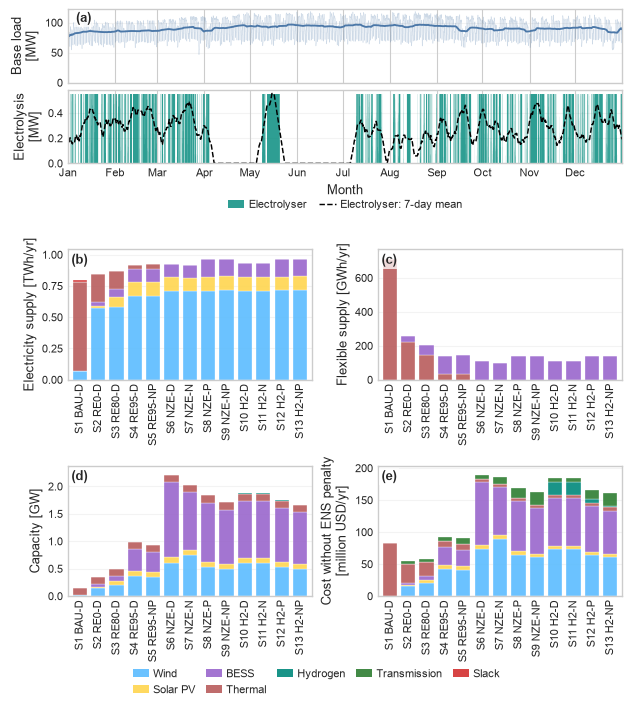

,Scenario,Thermal generation [GWh/yr],BESS discharge [GWh/yr],BESS power capacity [MW],BESS energy capacity [GWh],BESS duration [h],H2-to-power output [GWh/yr],H2 tank/other capacity [GWh],UHS capacity [GWh],BESS equivalent cycles [1/yr]
0,S1 BAU-D,712.080,0.000,0.000,0.000,0.0,0.000,0.000,0.0,0.000
1,S2 RE0-D,221.673,37.436,49.187,0.393,8.0,0.000,0.000,0.0,95.135
2,S3 RE80-D,144.491,62.283,89.789,0.718,8.0,0.000,0.000,0.0,86.708
3,S4 RE95-D,36.578,102.521,396.198,3.170,8.0,0.000,0.000,0.0,32.345
4,S5 RE95-NP,36.579,108.238,353.112,2.825,8.0,0.000,0.000,0.0,38.316
5,S6 NZE-D,0.000,110.466,1361.193,10.890,8.0,0.000,0.000,0.0,10.144
6,S7 NZE-N,0.000,97.073,1044.785,8.358,8.0,0.000,0.000,0.0,11.614
7,S8 NZE-P,0.000,139.089,1076.900,8.615,8.0,0.000,0.000,0.0,16.145
8,S9 NZE-NP,0.000,139.825,982.472,7.860,8.0,0.000,0.000,0.0,17.790
9,S10 H2-D,0.000,109.622,1031.097,8.249,8.0,3.019,5.261,0.0,13.289


Saved flexibility table to: output\output_magallanes\tables\table_flexibility_requirements_2050.csv


In [14]:
# ─────────────────────────────────────────────────────────────────────────────
# Figure 5 — Demand, electricity supply, flexibility, capacity, and cost
#
# (a) Hourly local-demand components and flexible electricity use
# (b) Annual electricity supply
# (c) Annual flexible electricity supply
# (d) Installed power capacity
# (e) Annual system cost
#
# The former Figure 6 is exported below as a numerical table.
# ─────────────────────────────────────────────────────────────────────────────

import matplotlib.dates as mdates


# ── Configuration ────────────────────────────────────────────────────────────
comparison_year = detailed_year

figure5_export_dir = (
    PAPER_FIGURE_DIR
    / "cross_scenario_all_years"
)

figure5_export_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Panel (a) can work both with and without PtX.
#
# Current Magallanes setup:
#   - PTX_interconnected is not simulated.
#   - H2_interconnected_NP is used to show electricity consumed by electrolysis.
#
# Future PtX setup:
#   - Add PTX_interconnected to the scenario matrix and RUN_SCENARIO_CODES.
#   - The cell will then select it automatically and include ASU/DAC use.
PTX_SCENARIO_CODE = "PTX_interconnected"
NON_PTX_PROFILE_SCENARIO = "H2_interconnected_NP"

ptx_profile_enabled = (
    PTX_SCENARIO_CODE in scenario_results
    and bool(
        scenario_results[PTX_SCENARIO_CODE]
        .get("metadata", {})
        .get("enable_ptx", False)
    )
)

if ptx_profile_enabled:
    profile_scenario = PTX_SCENARIO_CODE
else:
    profile_scenario = NON_PTX_PROFILE_SCENARIO

if profile_scenario not in scenario_results:
    # Partial run: panel (a) uses the last available scenario
    profile_scenario = list(scenario_results)[-1]
    print(f"Panel (a) uses {profile_scenario}.")


# ── Validation and scenario ordering ─────────────────────────────────────────
df_y = scenario_comparison[
    scenario_comparison["year"] == comparison_year
].copy()

if df_y.empty:
    raise ValueError(
        f"No scenario comparison data found for {comparison_year}."
    )

df_y = (
    apply_scenario_order(df_y)
    .reset_index(drop=True)
)

df_y["label"] = (
    df_y["scenario"]
    .map(SCENARIO_TECH_LABELS)
    .fillna(
        df_y["scenario"]
        .astype(str)
        .str.replace("_", " ", regex=False)
    )
)


# ── General helpers ──────────────────────────────────────────────────────────
def column_or_zero(df, column):
    """Return a numeric column or a zero-valued Series."""
    if column in df.columns:
        return (
            pd.to_numeric(
                df[column],
                errors="coerce",
            )
            .fillna(0.0)
        )

    return pd.Series(
        0.0,
        index=df.index,
        dtype=float,
    )


def link_input_series(net, carriers):
    """Aggregate positive p0 electricity input for selected links [MW]."""
    snapshots = pd.Index(net.snapshots)

    if (
        len(net.links) == 0
        or not hasattr(net.links_t, "p0")
    ):
        return pd.Series(
            0.0,
            index=snapshots,
        )

    carriers = set(carriers)

    selected_links = net.links.index[
        net.links["carrier"]
        .astype(str)
        .isin(carriers)
    ]

    if len(selected_links) == 0:
        return pd.Series(
            0.0,
            index=snapshots,
        )

    return (
        net.links_t.p0
        .reindex(
            index=snapshots,
            columns=selected_links,
            fill_value=0.0,
        )
        .clip(lower=0.0)
        .sum(axis=1)
    )


# ── Annual electricity supply ────────────────────────────────────────────────
def build_dispatch_group_df(df_year):
    """Build annual electricity supply by technology [TWh/yr]."""
    out = pd.DataFrame(index=df_year.index)

    out["Wind"] = (
        column_or_zero(
            df_year,
            "generation_wind_mwh",
        )
        / 1e6
    )

    out["Solar PV"] = (
        column_or_zero(
            df_year,
            "generation_solar_mwh",
        )
        / 1e6
    )

    out["BESS"] = (
        column_or_zero(
            df_year,
            "bess_discharge_mwh",
        )
        / 1e6
    )

    thermal_columns = [
        "generation_ocgt_mwh",
        "generation_gas_mwh",
        "generation_natural_gas_mwh",
        "generation_diesel_mwh",
        "generation_lpg_mwh",
    ]

    valid_thermal_columns = [
        column
        for column in thermal_columns
        if column in df_year.columns
    ]

    if valid_thermal_columns:
        out["Thermal"] = (
            df_year[valid_thermal_columns]
            .fillna(0.0)
            .sum(axis=1)
            / 1e6
        )
    else:
        out["Thermal"] = (
            column_or_zero(
                df_year,
                "thermal_generation_mwh",
            )
            / 1e6
        )

    if "h2_to_power_mwh" in df_year.columns:
        out["Hydrogen"] = (
            column_or_zero(
                df_year,
                "h2_to_power_mwh",
            )
            / 1e6
        )
    else:
        out["Hydrogen"] = (
            column_or_zero(
                df_year,
                "h2_fuel_cell_output_mwh",
            )
            + column_or_zero(
                df_year,
                "h2_turbine_output_mwh",
            )
        ) / 1e6

    # Retained for compatibility with a possible future PtX scenario.
    out["PtX"] = 0.0

    out["Slack"] = (
        column_or_zero(
            df_year,
            "generation_slack_mwh",
        )
        / 1e6
    )

    out["Other"] = 0.0

    for group in TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[TECH_GROUPS]


# ── Annual flexible electricity supply ──────────────────────────────────────
FLEXIBILITY_GROUPS = [
    "Thermal",
    "BESS",
    "Hydrogen",
]


def build_flexibility_group_df(df_year):
    """
    Build annual flexible electricity supplied by thermal generation,
    BESS discharge, and hydrogen-to-power [GWh/yr].
    """
    out = pd.DataFrame(index=df_year.index)

    out["Thermal"] = (
        column_or_zero(
            df_year,
            "thermal_generation_mwh",
        )
        / 1e3
    )

    out["BESS"] = (
        column_or_zero(
            df_year,
            "bess_discharge_mwh",
        )
        / 1e3
    )

    out["Hydrogen"] = (
        column_or_zero(
            df_year,
            "h2_to_power_mwh",
        )
        / 1e3
    )

    return out[FLEXIBILITY_GROUPS]


# ── Installed capacity ───────────────────────────────────────────────────────
def build_capacity_group_df(df_year):
    """Build installed power capacity by technology [GW]."""
    out = pd.DataFrame(index=df_year.index)

    out["Wind"] = (
        column_or_zero(
            df_year,
            "cap_wind_mw",
        )
        / 1e3
    )

    out["Solar PV"] = (
        column_or_zero(
            df_year,
            "cap_solar_mw",
        )
        / 1e3
    )

    out["BESS"] = (
        column_or_zero(
            df_year,
            "cap_bess_mw",
        )
        / 1e3
    )

    thermal_columns = [
        "cap_ocgt_mw",
        "cap_gas_mw",
        "cap_natural_gas_mw",
        "cap_diesel_mw",
        "cap_lpg_mw",
    ]

    valid_thermal_columns = [
        column
        for column in thermal_columns
        if column in df_year.columns
    ]

    out["Thermal"] = (
        df_year[valid_thermal_columns]
        .fillna(0.0)
        .sum(axis=1)
        / 1e3
        if valid_thermal_columns
        else 0.0
    )

    hydrogen_columns = [
        "linkcap_electrolyzer_mw",
        "linkcap_h2_fuel_cell_mw",
        "linkcap_h2_turbine_mw",
    ]

    valid_hydrogen_columns = [
        column
        for column in hydrogen_columns
        if column in df_year.columns
    ]

    out["Hydrogen"] = (
        df_year[valid_hydrogen_columns]
        .fillna(0.0)
        .sum(axis=1)
        / 1e3
        if valid_hydrogen_columns
        else 0.0
    )

    # Retained for compatibility with a possible future PtX scenario.
    out["PtX"] = 0.0

    out["Slack"] = 0.0
    out["Other"] = 0.0

    for group in TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[TECH_GROUPS]


# ── Prepare annual panel data ────────────────────────────────────────────────
dispatch_group_df = build_dispatch_group_df(df_y)
flexibility_group_df = build_flexibility_group_df(df_y)
capacity_group_df = build_capacity_group_df(df_y)
cost_group_df = build_cost_group_df(df_y)


# ── Prepare hourly demand-component and flexible-use profiles ────────────────
profile_package = scenario_results[profile_scenario]

if comparison_year not in profile_package["results"]:
    raise ValueError(
        f"{profile_scenario} has no result for {comparison_year}."
    )

profile_result = profile_package["results"][comparison_year]
profile_net = profile_result["network"]


def normalise_profile_index(values):
    """Return a timezone-naive DatetimeIndex for profile alignment."""
    index = pd.DatetimeIndex(
        pd.to_datetime(values)
    )

    if index.tz is not None:
        index = index.tz_localize(None)

    return index


profile_snapshots = normalise_profile_index(
    profile_net.snapshots
)

demand_components_df, demand_components_path, _ = (
    load_demand_components_for_scenario(
        profile_scenario,
        package=profile_package,
    )
)

if demand_components_df.empty:
    raise FileNotFoundError(
        "Panel (a) requires demand_components_<scenario>.csv. "
        f"No component file was found for {profile_scenario}."
    )

if "timestamp" not in demand_components_df.columns:
    raise ValueError(
        f"{demand_components_path} has no 'timestamp' column."
    )

component_year = demand_components_df[
    demand_components_df["year"]
    .astype(int)
    .eq(int(comparison_year))
].copy()

if component_year.empty:
    raise ValueError(
        f"{demand_components_path} has no demand components for "
        f"{comparison_year}."
    )

component_year["component_key"] = (
    component_year["component"]
    .map(_safe_component_name)
)

component_profiles = (
    component_year
    .pivot_table(
        index="timestamp",
        columns="component_key",
        values="demand_mw",
        aggfunc="sum",
        fill_value=0.0,
    )
    .sort_index()
)

component_profiles.index = normalise_profile_index(
    component_profiles.index
)

# Sum duplicated timestamps, if any, after aggregating zones.
component_profiles = (
    component_profiles
    .groupby(level=0)
    .sum()
    .sort_index()
)

# If the CSV uses another calendar year but preserves the hourly sequence,
# align it by position with the solved network.
if not component_profiles.index.equals(profile_snapshots):
    if len(component_profiles) != len(profile_snapshots):
        raise ValueError(
            "Demand-component profiles cannot be aligned with the solved "
            f"network: {len(component_profiles)} component timestamps versus "
            f"{len(profile_snapshots)} network snapshots."
        )

    component_profiles.index = profile_snapshots

component_profiles = (
    component_profiles
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
    .fillna(0.0)
    .clip(lower=0.0)
)

# Stable paper order, followed automatically by any future component.
active_components = [
    component
    for component in component_profiles.columns
    if component_profiles[component].abs().max() > 1e-9
]

preferred_component_order = [
    "base_load",
    "heating",
    "ev",
    "cooking",
    "process_electrification",
    "other",
]

profile_component_order = [
    component
    for component in preferred_component_order
    if component in active_components
]

profile_component_order += sorted(
    component
    for component in active_components
    if component not in profile_component_order
)

if not profile_component_order:
    raise ValueError(
        f"No active electricity-demand components were found for "
        f"{comparison_year} in {demand_components_path}."
    )

component_profiles = component_profiles[
    profile_component_order
]

component_rolling = (
    component_profiles
    .rolling(
        window=168,
        center=True,
        min_periods=24,
    )
    .mean()
)


# ── Optimised flexible electricity use ───────────────────────────────────────
# This is separate from exogenous demand_components_<scenario>.csv.
#
# Current Magallanes case:
#   - RH_base includes electricity consumed by the electrolyser.
#   - ASU and DAC remain zero because PtX is disabled.
#
# Future PtX case:
#   - When PTX_interconnected exists with enable_ptx=True, ASU/DAC are added
#     automatically to the profile.

electrolyser_use = link_input_series(
    profile_net,
    [
        "electrolyzer",
        "electrolyser",
    ],
)

if ptx_profile_enabled:
    ptx_aux_use = link_input_series(
        profile_net,
        [
            "asu",
            "dac",
        ],
    )
else:
    ptx_aux_use = pd.Series(
        0.0,
        index=profile_snapshots,
        dtype=float,
    )

ptx_profile = pd.DataFrame(
    {
        "Electrolyser": electrolyser_use.to_numpy(),
        "PtX auxiliaries": ptx_aux_use.to_numpy(),
    },
    index=profile_snapshots,
)

ptx_profile = (
    ptx_profile
    .sort_index()
    .clip(lower=0.0)
)

ptx_rolling = (
    ptx_profile
    .rolling(
        window=168,
        center=True,
        min_periods=24,
    )
    .mean()
)

ptx_total = (
    ptx_profile["Electrolyser"]
    + ptx_profile["PtX auxiliaries"]
)

ptx_total_rolling = (
    ptx_rolling["Electrolyser"]
    + ptx_rolling["PtX auxiliaries"]
)


# ── Figure layout ────────────────────────────────────────────────────────────
n_profile_axes = len(profile_component_order) + 1
additional_profile_axes = max(
    0,
    n_profile_axes - 2,
)

# Increase figure height as new demand components appear.
figure_height = (
    7.20
    + 0.72 * additional_profile_axes
)

profile_height_ratio = (
    1.18
    * n_profile_axes
    / 2.0
)

fig = plt.figure(
    figsize=(
        WORD_DOUBLE_COL_IN,
        figure_height,
    )
)

outer_gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    height_ratios=[
        profile_height_ratio,
        1.0,
        1.0,
    ],
    hspace=0.62,
    wspace=0.27,
)

# One strip per local-demand component, followed by a flexible-use strip.
profile_gs = outer_gs[0, :].subgridspec(
    nrows=n_profile_axes,
    ncols=1,
    height_ratios=[1.0] * n_profile_axes,
    hspace=0.10,
)

profile_axes = []

for row_index in range(
    len(profile_component_order)
):
    axis = fig.add_subplot(
        profile_gs[row_index, 0],
        sharex=(
            profile_axes[0]
            if profile_axes
            else None
        ),
    )

    profile_axes.append(axis)

ax_a_ptx = fig.add_subplot(
    profile_gs[-1, 0],
    sharex=profile_axes[0],
)

ax_b = fig.add_subplot(
    outer_gs[1, 0]
)

ax_c = fig.add_subplot(
    outer_gs[1, 1]
)

ax_d = fig.add_subplot(
    outer_gs[2, 0]
)

ax_e = fig.add_subplot(
    outer_gs[2, 1]
)


# ── (a) Hourly local-demand components and flexible electricity use ──────────
electrolyser_color = DEMAND_COLORS_GROUPED.get(
    "Electrolyser",
    TECH_COLORS.get(
        "electrolyzer",
        "#00897b",
    ),
)

ptx_aux_color = DEMAND_COLORS_GROUPED.get(
    "PtX auxiliaries",
    TECH_COLORS.get(
        "asu",
        "#80cbc4",
    ),
)

fallback_component_colors = plt.get_cmap(
    "tab10"
)

for component_index, (axis, component) in enumerate(
    zip(
        profile_axes,
        profile_component_order,
    )
):
    component_label = DEMAND_COMPONENT_LABELS.get(
        component,
        component.replace(
            "_",
            " ",
        ).title(),
    )

    component_color = DEMAND_COMPONENT_COLORS.get(
        component,
        fallback_component_colors(
            component_index % 10
        ),
    )

    # Thin line: hourly profile.
    axis.plot(
        component_profiles.index,
        component_profiles[component],
        color=component_color,
        linewidth=0.35,
        alpha=0.28,
    )

    # Thick line: seven-day rolling average.
    axis.plot(
        component_rolling.index,
        component_rolling[component],
        color=component_color,
        linewidth=1.35,
    )

    axis.set_ylabel(
        f"{component_label}\n[MW]"
    )

    axis.set_ylim(
        bottom=0.0
    )

    axis.grid(
        axis="y",
        alpha=0.22,
    )

    axis.set_axisbelow(
        True
    )

    axis.tick_params(
        axis="x",
        labelbottom=False,
    )

panel_label(
    profile_axes[0],
    "(a)",
)


# Flexible electricity use:
# hourly area and seven-day rolling average.
ax_a_ptx.fill_between(
    ptx_profile.index,
    0.0,
    ptx_profile["Electrolyser"],
    color=electrolyser_color,
    alpha=0.82,
    linewidth=0.0,
    step="mid",
    label="Electrolyser",
)

# Keep PtX auxiliaries prepared, but only draw them when PtX is enabled.
if ptx_profile_enabled:
    ax_a_ptx.fill_between(
        ptx_profile.index,
        ptx_profile["Electrolyser"],
        ptx_total,
        color=ptx_aux_color,
        alpha=0.82,
        linewidth=0.0,
        step="mid",
        label="PtX auxiliaries",
    )

mean_label = (
    "Total PtX: 7-day mean"
    if ptx_profile_enabled
    else "Electrolyser: 7-day mean"
)

ax_a_ptx.plot(
    ptx_total_rolling.index,
    ptx_total_rolling,
    color="black",
    linewidth=1.05,
    linestyle="--",
    label=mean_label,
)

ax_a_ptx.set_ylabel(
    "PtX use\n[MW]"
    if ptx_profile_enabled
    else "Electrolysis\n[MW]"
)

ax_a_ptx.set_ylim(
    bottom=0.0
)

ax_a_ptx.set_xlabel(
    "Month"
)

ax_a_ptx.grid(
    axis="y",
    alpha=0.22,
)

ax_a_ptx.set_axisbelow(
    True
)

ax_a_ptx.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax_a_ptx.xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

ax_a_ptx.set_xlim(
    profile_snapshots.min(),
    profile_snapshots.max(),
)

ax_a_ptx.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.36),
    ncol=(
        3
        if ptx_profile_enabled
        else 2
    ),
    frameon=False,
    fontsize=FONT_SIZE_SMALL,
    columnspacing=1.1,
    handlelength=1.5,
    handletextpad=0.4,
)


# ── (b) Annual electricity supply ────────────────────────────────────────────
used_tech_groups = set()

used = plot_stacked_bars(
    ax_b,
    dispatch_group_df,
    TECH_GROUPS,
    TECH_COLORS_GROUPED,
    df_y["label"].tolist(),
    ylabel="Electricity supply [TWh/yr]",
)

used_tech_groups.update(
    used
)

panel_label(
    ax_b,
    "(b)",
)


# ── (c) Annual flexible electricity supply ──────────────────────────────────
used = plot_stacked_bars(
    ax_c,
    flexibility_group_df,
    FLEXIBILITY_GROUPS,
    TECH_COLORS_GROUPED,
    df_y["label"].tolist(),
    ylabel="Flexible supply [GWh/yr]",
)

used_tech_groups.update(
    used
)

panel_label(
    ax_c,
    "(c)",
)


# ── (d) Installed power capacity ─────────────────────────────────────────────
used = plot_stacked_bars(
    ax_d,
    capacity_group_df,
    TECH_GROUPS,
    TECH_COLORS_GROUPED,
    df_y["label"].tolist(),
    ylabel="Capacity [GW]",
)

used_tech_groups.update(
    used
)

panel_label(
    ax_d,
    "(d)",
)


# ── (e) Annual system cost ───────────────────────────────────────────────────
used = plot_stacked_bars(
    ax_e,
    cost_group_df,
    TECH_GROUPS,
    TECH_COLORS_GROUPED,
    df_y["label"].tolist(),
    ylabel=COST_AXIS_LABEL,
)

used_tech_groups.update(
    used
)

panel_label(
    ax_e,
    "(e)",
)


# ── Shared technology legend ─────────────────────────────────────────────────
tech_handles = []
tech_labels = []

for group in TECH_GROUPS:
    if group not in used_tech_groups:
        continue

    tech_handles.append(
        plt.Rectangle(
            (0, 0),
            1,
            1,
            facecolor=TECH_COLORS_GROUPED.get(
                group,
                "#999999",
            ),
            edgecolor="none",
            alpha=0.90,
        )
    )

    tech_labels.append(
        TECH_LEGEND_LABELS.get(
            group,
            group,
        )
    )

fig.legend(
    tech_handles,
    tech_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.018),
    ncol=5,
    frameon=False,
    fontsize=FONT_SIZE_SMALL,
    columnspacing=1.0,
    handlelength=1.4,
    handletextpad=0.4,
)


# ── Final figure spacing ─────────────────────────────────────────────────────
fig.subplots_adjust(
    top=0.985,
    bottom=0.17,
    left=0.105,
    right=0.985,
)


# ── Export Figure 5 ──────────────────────────────────────────────────────────
figure5_paths = []

for extension in [
    "png",
    "svg",
    "pdf",
]:
    figure5_paths.append(
        save_paper_figure(
            fig,
            (
                f"figure05_system_design_"
                f"{comparison_year}.{extension}"
            ),
            folder=figure5_export_dir,
        )
    )

plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# Table replacing the former Figure 6
# ─────────────────────────────────────────────────────────────────────────────
bess_power_mw = column_or_zero(
    df_y,
    "cap_bess_mw",
)

bess_energy_mwh = column_or_zero(
    df_y,
    "energy_bess_mwh",
)

bess_duration_h = (
    bess_energy_mwh
    .div(
        bess_power_mw.replace(
            0.0,
            np.nan,
        )
    )
    .fillna(0.0)
)

flexibility_table = pd.DataFrame(
    {
        "Scenario": df_y["label"],

        "Thermal generation [GWh/yr]": (
            column_or_zero(
                df_y,
                "thermal_generation_mwh",
            )
            / 1e3
        ),

        "BESS discharge [GWh/yr]": (
            column_or_zero(
                df_y,
                "bess_discharge_mwh",
            )
            / 1e3
        ),

        "BESS power capacity [MW]": (
            bess_power_mw
        ),

        "BESS energy capacity [GWh]": (
            bess_energy_mwh
            / 1e3
        ),

        "BESS duration [h]": (
            bess_duration_h
        ),

        "H2-to-power output [GWh/yr]": (
            column_or_zero(
                df_y,
                "h2_to_power_mwh",
            )
            / 1e3
        ),

        "H2 tank/other capacity [GWh]": (
            column_or_zero(
                df_y,
                "h2_storage_total_mwh",
            )
            / 1e3
        ),

        "UHS capacity [GWh]": (
            column_or_zero(
                df_y,
                "uhs_storage_total_mwh",
            )
            / 1e3
        ),
    }
)

flexibility_table[
    "BESS equivalent cycles [1/yr]"
] = (
    flexibility_table[
        "BESS discharge [GWh/yr]"
    ]
    .div(
        flexibility_table[
            "BESS energy capacity [GWh]"
        ]
        .replace(
            0.0,
            np.nan,
        )
    )
    .fillna(0.0)
)

flexibility_table_path = (
    TABLE_EXPORT_DIR
    / f"table_flexibility_requirements_{comparison_year}.csv"
)

flexibility_table.to_csv(
    flexibility_table_path,
    index=False,
)

display(
    flexibility_table.round(3)
)

print(
    f"Saved flexibility table to: "
    f"{flexibility_table_path}"
)

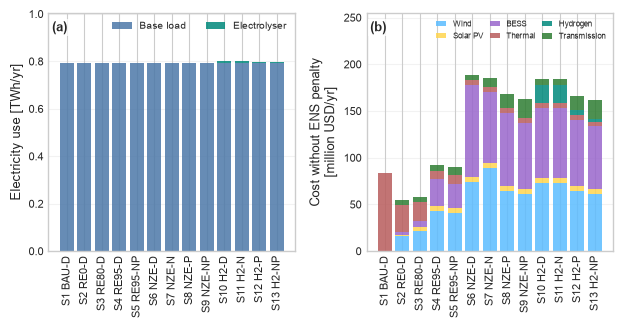

In [15]:
# Demand and cost decomposition figure
if demand_breakdown_summary.empty:
    raise ValueError("Run the demand/cost breakdown cell first.")

demand_y = apply_scenario_order(demand_breakdown_summary[demand_breakdown_summary["year"] == breakdown_year])
demand_y["label"] = [SCENARIO_TECH_LABELS.get(s, scenario_label(s)) for s in demand_y["scenario"]]

x = np.arange(len(demand_y))
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_2COL)

# (a) Electricity-use decomposition from demand_profiles_scenarios + PtX link use
ax = axes[0]
component_stack = [
    ("demand_base_load_mwh", "Base load", DEMAND_COMPONENT_COLORS.get("base_load", "#4c78a8")),
    ("demand_heating_mwh", "Heating", DEMAND_COMPONENT_COLORS.get("heating", "#f58518")),
    ("demand_ev_mwh", "EVs", DEMAND_COMPONENT_COLORS.get("ev", "#54a24b")),
    ("demand_cooking_mwh", "Cooking", DEMAND_COMPONENT_COLORS.get("cooking", "#b279a2")),
    ("demand_process_electrification_mwh", "Process electrification", DEMAND_COMPONENT_COLORS.get("process_electrification", "#e45756")),
    ("demand_other_mwh", "Other local demand", DEMAND_COMPONENT_COLORS.get("other", "#9e9e9e")),
    ("electrolyser_input_mwh", "Electrolyser", DEMAND_COMPONENT_COLORS.get("electrolyser", TECH_COLORS.get("electrolyzer", "#00897b"))),
    ("ptx_aux_electricity_mwh", "PtX auxiliaries", DEMAND_COMPONENT_COLORS.get("ptx_aux", TECH_COLORS.get("asu", "#80cbc4"))),
]
component_stack = [
    item for item in component_stack
    if item[0] in demand_y.columns and demand_y[item[0]].fillna(0).sum() > 1e-6
]

bottom = np.zeros(len(demand_y))
for col, label, color in component_stack:
    vals = demand_y[col].fillna(0).values / 1e6
    ax.bar(x, vals, bottom=bottom, label=label, color=color, alpha=0.85)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(demand_y["label"], rotation=90, ha="center", fontsize=6.5)
finish_axis(ax, ylabel="Electricity use [TWh/yr]")
ax.set_ylim(0.0, 1.25 * max(bottom.max(), 1e-6))
ax.legend(loc="upper right", frameon=False, ncol=2, fontsize=7)
panel_label(ax, "(a)")

# (b) Approximate cost decomposition
ax = axes[1]
if cost_breakdown_summary.empty:
    ax.text(0.5, 0.5, "No cost breakdown available", ha="center", va="center", transform=ax.transAxes)
else:
    cost_y = cost_breakdown_summary[cost_breakdown_summary["year"] == breakdown_year].copy()
    group_order = TECH_GROUPS
    pivot = (
        cost_y.pivot_table(index="scenario", columns="group", values="total_cost", aggfunc="sum")
        .reindex(demand_y["scenario"])
        .fillna(0.0)
    )
    bottom = np.zeros(len(pivot))
    for group in [g for g in group_order if g != "Slack" and g in pivot.columns and pivot[g].sum() > 0]:
        vals = pivot[group].values / 1e6
        ax.bar(x, vals, bottom=bottom, label=group, color=TECH_COLORS_GROUPED.get(group, "#999999"), alpha=0.85)
        bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(demand_y["label"], rotation=90, ha="center", fontsize=6.5)
finish_axis(ax, ylabel=COST_AXIS_LABEL)
if not cost_breakdown_summary.empty:
    ax.set_ylim(0.0, 1.35 * max(bottom.max(), 1e-6))
ax.legend(loc="upper right", frameon=False, ncol=3, fontsize=6, columnspacing=0.8, handlelength=1.2)
panel_label(ax, "(b)")

plt.tight_layout()
plt.show()


## 7. Renewable scarcity and critical-event dispatch

Daily wind and solar capacity factors identify low-renewable periods and the longest simultaneous scarcity event. Dispatch is then reconstructed from the exported CSV files for the same event window across scenarios.

In [ ]:
# Renewable-scarcity helper functions

def _prepare_cf_series(cf_df: pd.DataFrame) -> pd.Series:
    """Average capacity-factor profiles across zones."""
    if cf_df is None or cf_df.empty:
        raise ValueError("No capacity-factor data are available.")

    cf = cf_df.copy()
    if not isinstance(cf.index, pd.DatetimeIndex):
        cf.index = pd.to_datetime(cf.index)

    return cf.mean(axis=1)


def _daily_mean_series(cf_series: pd.Series) -> pd.Series:
    return cf_series.resample("D").mean()


def _monthly_max_consecutive_low_days(
    daily_cf: pd.Series,
    threshold: float,
) -> pd.Series:
    month_labels = [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
    ]
    result = pd.Series(0.0, index=month_labels)

    for month_num, month_data in daily_cf.groupby(daily_cf.index.month):
        maximum = 0
        current = 0
        for is_low in month_data.lt(threshold):
            current = current + 1 if is_low else 0
            maximum = max(maximum, current)
        result.iloc[month_num - 1] = maximum

    return result


def _longest_true_run(mask: pd.Series) -> tuple[pd.Timestamp | None, pd.Timestamp | None, int]:
    """Return the start, end, and duration of the longest True run."""
    mask = mask.astype(bool)
    best_start = best_end = current_start = None
    best_length = current_length = 0

    for timestamp, value in mask.items():
        if value:
            if current_start is None:
                current_start = timestamp
            current_length += 1
            if current_length > best_length:
                best_start = current_start
                best_end = timestamp
                best_length = current_length
        else:
            current_start = None
            current_length = 0

    return best_start, best_end, best_length



Plotting combined Figure 4 for H2_interconnected_NP – 2050...
Saved figure: output\output_magallanes\figures\figure04_capacity_factor_combined\figure04_combined_H2_interconnected_NP_2050.png
Saved figure: output\output_magallanes\figures\figure04_capacity_factor_combined\figure04_combined_H2_interconnected_NP_2050.svg
Saved figure: output\output_magallanes\figures\figure04_capacity_factor_combined\figure04_combined_H2_interconnected_NP_2050.pdf


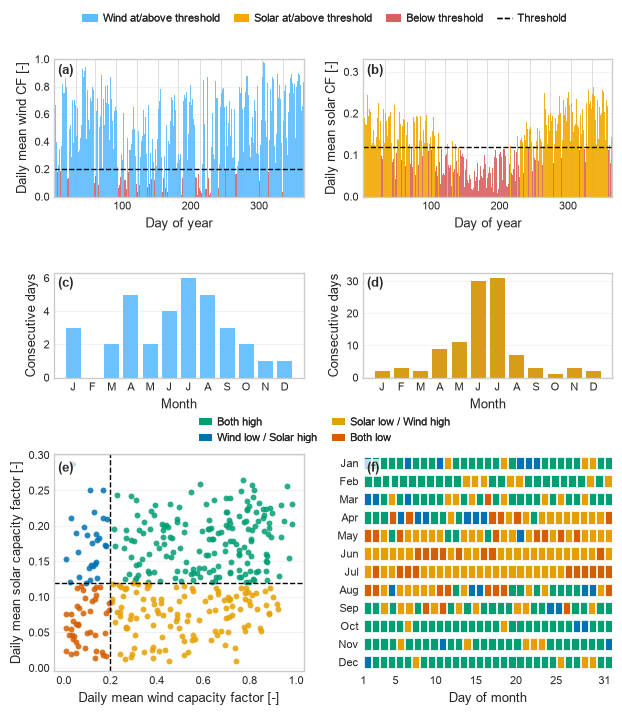

In [17]:
# Combined renewable-scarcity figure
cf_combined_scenario = active_scenario
cf_combined_years = [detailed_year]   # one representative planning year
cf_combined_export_dir = PAPER_FIGURE_DIR / "figure04_capacity_factor_combined"
cf_combined_export_dir.mkdir(parents=True, exist_ok=True)

RESOURCE_LABELS = [
    "Both high",
    "Wind low / Solar high",
    "Solar low / Wind high",
    "Both low",
]
RESOURCE_COLORS = ["#009e73", "#0072b2", "#e69f00", "#d55e00"]


def _resource_calendar_dataframe(wind_daily, solar_daily, wind_threshold, solar_threshold):
    df = pd.DataFrame({"wind": wind_daily, "solar": solar_daily}).dropna().copy()
    df["month"] = df.index.month
    df["day"] = df.index.day
    df["category"] = np.select(
        [
            (df["wind"] >= wind_threshold) & (df["solar"] >= solar_threshold),
            (df["wind"] < wind_threshold) & (df["solar"] >= solar_threshold),
            (df["wind"] >= wind_threshold) & (df["solar"] < solar_threshold),
            (df["wind"] < wind_threshold) & (df["solar"] < solar_threshold),
        ],
        [0, 1, 2, 3],
        default=np.nan,
    )
    return df


def _add_month_separators_embedded(ax, daily_index):
    month_starts = pd.Series(index=daily_index, data=1).resample("MS").first().index
    month_start_days = month_starts.dayofyear.values
    for day in month_start_days:
        ax.axvline(day, color="#bcbcbc", linewidth=0.7, alpha=0.5, zorder=0)
    return ax


def _month_bar_axis(ax, series, color, ylabel, panel):
    month_labels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
    month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    x = np.arange(len(month_labels))
    vals = series.reindex(month_order).fillna(0.0).values

    ax.bar(x, vals, color=color, alpha=0.90, width=0.78)
    ax.set_xticks(x)
    ax.set_xticklabels(month_labels, fontsize=7)
    finish_axis(ax, xlabel="Month", ylabel=ylabel)
    ax.grid(False)
    ax.yaxis.grid(True, alpha=0.22)
    ax.xaxis.grid(False)
    ax.set_axisbelow(True)
    panel_label(ax, panel)


def _draw_resource_calendar_blocks(ax, calendar_df, panel):
    """
    Draw daily resource-category blocks month by month.

    Each month row spans the same total width, but daily blocks are wider
    in shorter months, so February/April/June/etc. align with 31-day months.
    """
    month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

    # Use the actual year to handle leap years correctly.
    plot_year = int(calendar_df.index[0].year)

    max_days_axis = 31.0

    ax.set_xlim(0, max_days_axis)
    ax.set_ylim(-0.5, 11.5)
    ax.invert_yaxis()

    for month_idx in range(12):
        month_num = month_idx + 1
        n_days = monthrange(plot_year, month_num)[1]

        # Daily blocks are stretched so each month row spans 31 axis units.
        cell_width = max_days_axis / n_days
        block_width = cell_width * 0.88
        x_pad = (cell_width - block_width) / 2

        month_df = calendar_df[calendar_df["month"] == month_num]

        for _, row in month_df.iterrows():
            day = int(row["day"])
            cat = int(row["category"])

            x0 = (day - 1) * cell_width + x_pad

            rect = Rectangle(
                (x0, month_idx - 0.34),
                block_width,
                0.68,
                facecolor=RESOURCE_COLORS[cat],
                edgecolor="white",
                linewidth=0.55,
            )
            ax.add_patch(rect)

    ax.set_yticks(np.arange(12))
    ax.set_yticklabels(month_labels, fontsize=8)

    # These are approximate day-of-month reference labels on a 31-day axis.
    ax.set_xticks([0, 4, 9, 14, 19, 24, 30])
    ax.set_xticklabels([1, 5, 10, 15, 20, 25, 31], fontsize=7)

    finish_axis(ax, xlabel="Day of month", ylabel=None)
    ax.grid(False)
    ax.tick_params(axis="both", length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

    panel_label(ax, panel)


def plot_combined_cf_figure(scenario_code, year, save_figure=True, show_figure=True):
    result = scenario_results[scenario_code]["results"][year]
    wind_cf_local = result["wind_cf"]
    solar_cf_local = result["solar_cf"]

    wind_series_local = _prepare_cf_series(wind_cf_local)
    solar_series_local = _prepare_cf_series(solar_cf_local)
    wind_daily_local = _daily_mean_series(wind_series_local)
    solar_daily_local = _daily_mean_series(solar_series_local)

    wind_streak_local = _monthly_max_consecutive_low_days(wind_daily_local, LOW_WIND_THRESHOLD)
    solar_streak_local = _monthly_max_consecutive_low_days(solar_daily_local, LOW_SOLAR_THRESHOLD)

    scatter_df = pd.DataFrame({"wind": wind_daily_local, "solar": solar_daily_local}).dropna()
    calendar_df = _resource_calendar_dataframe(
        wind_daily_local,
        solar_daily_local,
        LOW_WIND_THRESHOLD,
        LOW_SOLAR_THRESHOLD,
    )

    # Slightly tighter figure, but still enough room for shared legends
    fig = plt.figure(figsize=(7.2, 8.5))
    gs = fig.add_gridspec(
        3, 2,
        height_ratios=[1.00, 0.76, 1.58],
        hspace=0.50,
        wspace=0.24,
    )

    ax_a = fig.add_subplot(gs[0, 0])
    ax_b = fig.add_subplot(gs[0, 1])
    ax_c = fig.add_subplot(gs[1, 0])
    ax_d = fig.add_subplot(gs[1, 1])
    ax_e = fig.add_subplot(gs[2, 0])
    ax_f = fig.add_subplot(gs[2, 1])

    # Colors for threshold panels
    wind_high_color = TECH_COLORS.get("wind", "#5bbcff")
    solar_high_color = "#f2a900"
    low_color = "#d95f5f"

    # (a) Daily wind CF
    day_w = wind_daily_local.index.dayofyear
    colors_w = np.where(
        wind_daily_local.values < LOW_WIND_THRESHOLD,
        low_color,
        wind_high_color,
    )
    ax_a.bar(day_w, wind_daily_local.values, color=colors_w, width=1.0, alpha=0.90)
    ax_a.axhline(LOW_WIND_THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax_a.set_xlim(1, int(day_w.max()))
    ax_a.set_ylim(0, 1.0)
    finish_axis(ax_a, xlabel="Day of year", ylabel="Daily mean wind CF [-]")
    ax_a.grid(False)
    ax_a.yaxis.grid(True, alpha=0.22)
    ax_a.xaxis.grid(False)
    _add_month_separators_embedded(ax_a, wind_daily_local.index)
    panel_label(ax_a, "(a)")

    # (b) Daily solar CF
    day_s = solar_daily_local.index.dayofyear
    colors_s = np.where(
        solar_daily_local.values < LOW_SOLAR_THRESHOLD,
        low_color,
        solar_high_color,
    )
    ax_b.bar(day_s, solar_daily_local.values, color=colors_s, width=1.0, alpha=0.90)
    ax_b.axhline(LOW_SOLAR_THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax_b.set_xlim(1, int(day_s.max()))
    ax_b.set_ylim(0, max(0.32, float(solar_daily_local.max()) * 1.15))
    finish_axis(ax_b, xlabel="Day of year", ylabel="Daily mean solar CF [-]")
    ax_b.grid(False)
    ax_b.yaxis.grid(True, alpha=0.22)
    ax_b.xaxis.grid(False)
    _add_month_separators_embedded(ax_b, solar_daily_local.index)
    panel_label(ax_b, "(b)")

    # (c) Longest low-wind streak per month
    _month_bar_axis(
        ax_c,
        wind_streak_local,
        wind_high_color,
        "Consecutive days",
        "(c)",
    )

    # (d) Longest low-solar streak per month
    _month_bar_axis(
        ax_d,
        solar_streak_local,
        "#d39200",
        "Consecutive days",
        "(d)",
    )

    # (e) Scatter of daily wind vs solar CF
    conditions = [
        (scatter_df["wind"] >= LOW_WIND_THRESHOLD) & (scatter_df["solar"] >= LOW_SOLAR_THRESHOLD),
        (scatter_df["wind"] < LOW_WIND_THRESHOLD) & (scatter_df["solar"] >= LOW_SOLAR_THRESHOLD),
        (scatter_df["wind"] >= LOW_WIND_THRESHOLD) & (scatter_df["solar"] < LOW_SOLAR_THRESHOLD),
        (scatter_df["wind"] < LOW_WIND_THRESHOLD) & (scatter_df["solar"] < LOW_SOLAR_THRESHOLD),
    ]

    for mask, lab, col in zip(conditions, RESOURCE_LABELS, RESOURCE_COLORS):
        ax_e.scatter(
            scatter_df.loc[mask, "wind"],
            scatter_df.loc[mask, "solar"],
            s=18,
            alpha=0.85,
            color=col,
            label=lab,
            linewidths=0,
        )

    ax_e.axvline(LOW_WIND_THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax_e.axhline(LOW_SOLAR_THRESHOLD, color="black", linestyle="--", linewidth=1)
    finish_axis(
        ax_e,
        xlabel="Daily mean wind capacity factor [-]",
        ylabel="Daily mean solar capacity factor [-]",
    )
    ax_e.grid(False)
    ax_e.yaxis.grid(True, alpha=0.22)
    ax_e.xaxis.grid(False)
    panel_label(ax_e, "(e)")

    # (f) Resource category calendar
    _draw_resource_calendar_blocks(ax_f, calendar_df, "(f)")

    # Shared legend for panels (a) and (b), above first row
    threshold_legend_items = [
        Patch(facecolor=wind_high_color, label="Wind at/above threshold"),
        Patch(facecolor=solar_high_color, label="Solar at/above threshold"),
        Patch(facecolor=low_color, label="Below threshold"),
        Line2D([0], [0], color="black", linestyle="--", linewidth=1, label="Threshold"),
    ]
    leg_top = fig.legend(
        handles=threshold_legend_items,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.985),
        ncol=4,
        fontsize=7.8,
        frameon=False,
        columnspacing=1.25,
        handlelength=1.4,
        handletextpad=0.5,
    )
    fig.add_artist(leg_top)

    # Shared legend for panels (e) and (f), just above third row
    resource_legend_items = [
        Patch(facecolor=RESOURCE_COLORS[0], label="Both high"),
        Patch(facecolor=RESOURCE_COLORS[1], label="Wind low / Solar high"),
        Patch(facecolor=RESOURCE_COLORS[2], label="Solar low / Wind high"),
        Patch(facecolor=RESOURCE_COLORS[3], label="Both low"),
    ]
    leg_mid = fig.legend(
        handles=resource_legend_items,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.51),
        ncol=2,
        fontsize=7.8,
        frameon=False,
        columnspacing=1.35,
        handlelength=1.2,
        handletextpad=0.5,
    )
    fig.add_artist(leg_mid)

    if not PAPER_MODE:
        fig.suptitle(
            f"{scenario_label(scenario_code)} – renewable scarcity ({year})",
            fontsize=FONT_SIZE_LABEL + 1,
            y=0.997,
        )
        fig.subplots_adjust(top=0.92, bottom=0.07)
    else:
        fig.subplots_adjust(top=0.92, bottom=0.20)

    out_path = None
    if save_figure:
        out_path = save_paper_figure(
            fig,
            f"figure04_combined_{scenario_code}_{year}.png",
            folder=cf_combined_export_dir,
        )
        out_path = save_paper_figure(
            fig,
            f"figure04_combined_{scenario_code}_{year}.svg",
            folder=cf_combined_export_dir,
        )
        out_path = save_paper_figure(
            fig,
            f"figure04_combined_{scenario_code}_{year}.pdf",
            folder=cf_combined_export_dir,
        )

    if show_figure:
        plt.show()
    else:
        plt.close(fig)

    return out_path


for year in cf_combined_years:
    print(f"\nPlotting combined Figure 4 for {cf_combined_scenario} – {year}...")
    plot_combined_cf_figure(cf_combined_scenario, year)


In [18]:
# Longest simultaneous low-wind and low-solar event
def identify_simultaneous_low_event(
    wind_cf,
    solar_cf,
    wind_threshold=LOW_WIND_THRESHOLD,
    solar_threshold=LOW_SOLAR_THRESHOLD,
):
    wind_series = wind_cf.mean(axis=1).copy()
    solar_series = solar_cf.mean(axis=1).copy()

    wind_series.index = pd.to_datetime(wind_series.index)
    solar_series.index = pd.to_datetime(solar_series.index)

    wind_daily = wind_series.resample("D").mean()
    solar_daily = solar_series.resample("D").mean()

    low_event_mask = (wind_daily < wind_threshold) & (solar_daily < solar_threshold)
    start, end, duration_days = _longest_true_run(low_event_mask)

    event_table = pd.DataFrame({
        "wind_daily_cf": wind_daily,
        "solar_daily_cf": solar_daily,
        "simultaneous_low": low_event_mask,
    })

    if start is None:
        raise ValueError("No simultaneous low-wind and low-solar event found with the selected thresholds.")

    return {
        "start_day": start,
        "end_day": end,
        "duration_days": duration_days,
        "start_hour": pd.Timestamp(start),
        "end_hour": pd.Timestamp(end) + pd.Timedelta(hours=23),
        "event_table": event_table,
    }


critical_event = identify_simultaneous_low_event(
    wind_cf,
    solar_cf,
    wind_threshold=LOW_WIND_THRESHOLD,
    solar_threshold=LOW_SOLAR_THRESHOLD,
)

critical_event_start = critical_event["start_hour"]
critical_event_end = critical_event["end_hour"]

print("Critical simultaneous low-renewable event:")
print(f"  Start: {critical_event_start}")
print(f"  End:   {critical_event_end}")
print(f"  Duration: {critical_event['duration_days']} days")

display(
    critical_event["event_table"]
    .loc[critical_event["start_day"]:critical_event["end_day"]]
    .round(3)
)

# Export event table for traceability
critical_event_table_path = TABLE_EXPORT_DIR / f"critical_event_daily_table_{base_case_name}_{active_scenario}_{detailed_year}.csv"
critical_event["event_table"].to_csv(critical_event_table_path)
print(f"Saved daily event table to: {critical_event_table_path}")


Critical simultaneous low-renewable event:
  Start: 2050-07-26 00:00:00
  End:   2050-08-02 23:00:00
  Duration: 8 days


,wind_daily_cf,solar_daily_cf,simultaneous_low
index,,,
2050-07-26,0.140,0.114,True
2050-07-27,0.073,0.115,True
2050-07-28,0.133,0.097,True
2050-07-29,0.011,0.024,True
2050-07-30,0.051,0.022,True
2050-07-31,0.164,0.022,True
2050-08-01,0.061,0.031,True
2050-08-02,0.043,0.045,True


Saved daily event table to: output\output_magallanes\tables\critical_event_daily_table_magallanes_H2_interconnected_NP_2050.csv


Saved figure: output\output_magallanes\figures\figure_critical_event_dispatch_negative_loads_2050.png


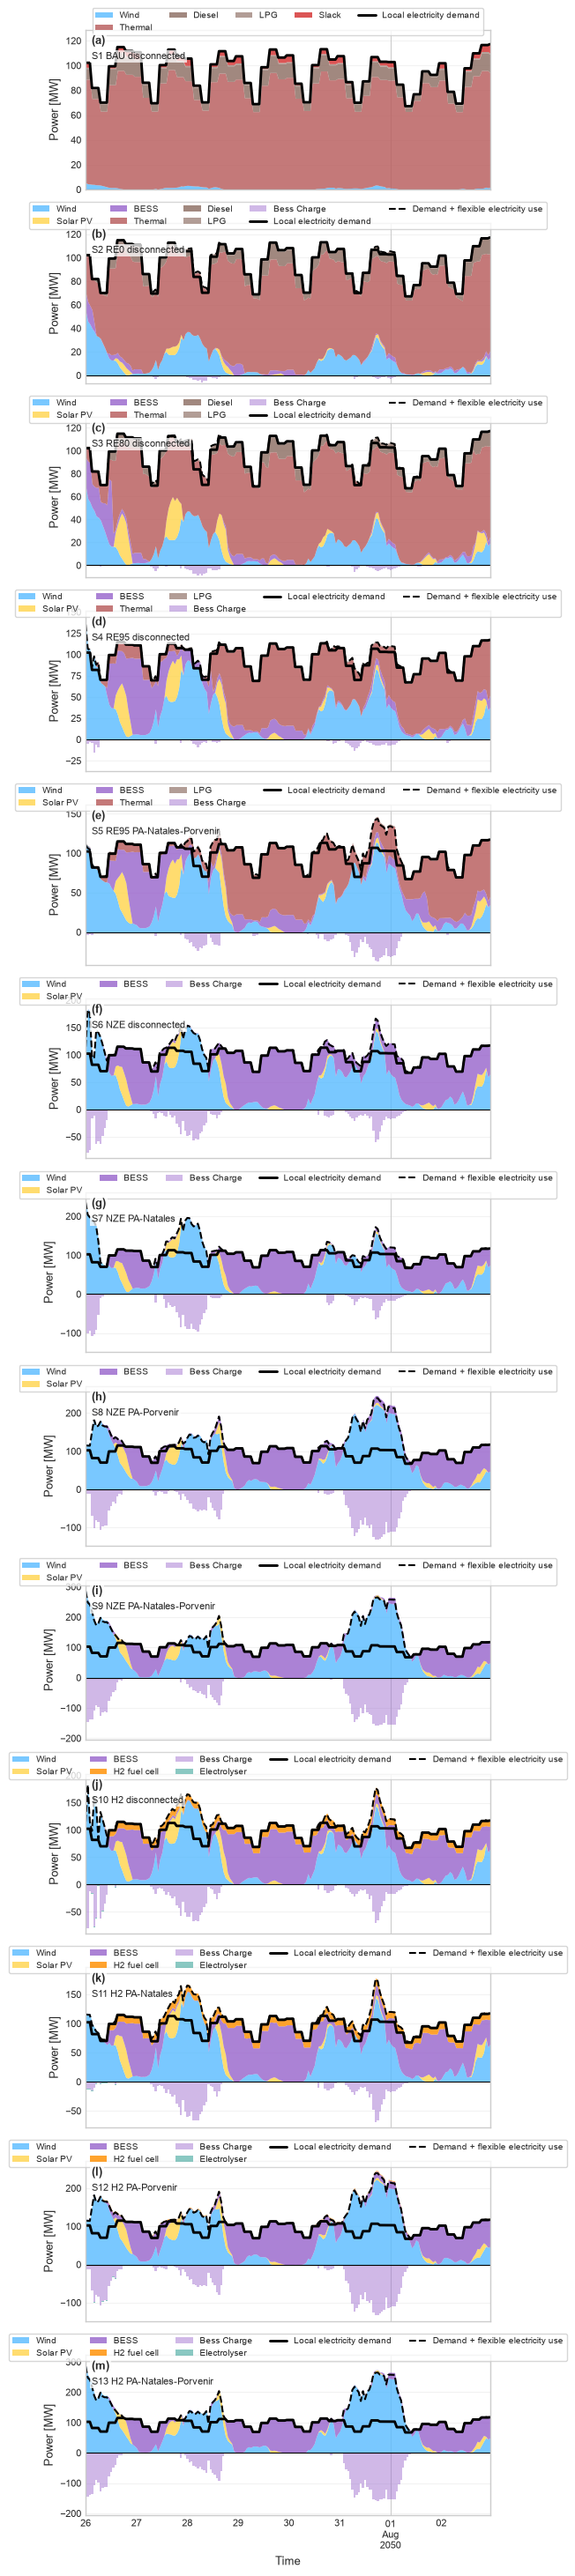

,scenario,paper_label,event_start,event_end,event_demand_mwh,event_supply_mwh,event_flexible_electricity_use_mwh,supply_wind_mwh,supply_ocgt_mwh,supply_diesel_mwh,supply_lpg_mwh,supply_slack_mwh,supply_solar_mwh,supply_bess_mwh,negative_bess_charge_mwh,supply_h2_fuel_cell_mwh,negative_electrolyzer_mwh
0,BAU_disconnected,S1 BAU disconnected,2050-07-26,2050-08-02 23:00:00,18251.932,18255.718,0.000,189.294,15517.872,1950.332,185.280,412.94,NaN,NaN,NaN,NaN,NaN
1,RE0_disconnected,S2 RE0 disconnected,2050-07-26,2050-08-02 23:00:00,18251.932,18383.867,91.739,2157.192,14285.305,1235.348,185.280,0.00,173.751,346.991,91.739,NaN,NaN
2,RE80_disconnected,S3 RE80 disconnected,2050-07-26,2050-08-02 23:00:00,18251.932,18485.258,176.672,2737.973,12978.991,1039.518,185.280,0.00,796.999,746.497,176.672,NaN,NaN
3,RE95_disconnected,S4 RE95 disconnected,2050-07-26,2050-08-02 23:00:00,18251.932,18715.779,318.956,5559.921,9130.613,0.000,174.450,0.00,1017.961,2832.834,318.956,NaN,NaN
4,RE95_interconnected_NP,S5 RE95 PA-Natales-Porvenir,2050-07-26,2050-08-02 23:00:00,18251.932,19497.413,963.717,7225.502,7836.442,0.000,176.839,0.00,1017.961,3240.669,963.717,NaN,NaN
5,NZE_disconnected,S6 NZE disconnected,2050-07-26,2050-08-02 23:00:00,18251.932,20433.010,1866.011,9253.286,0.000,0.000,0.000,0.00,1017.566,10162.158,1866.011,NaN,NaN
6,NZE_interconnected_N,S7 NZE PA-Natales,2050-07-26,2050-08-02 23:00:00,18251.932,21274.950,2689.054,11244.386,0.000,0.000,0.000,0.00,1017.566,9012.999,2689.054,NaN,NaN
7,NZE_interconnected_P,S8 NZE PA-Porvenir,2050-07-26,2050-08-02 23:00:00,18251.932,23745.976,4826.644,13968.254,0.000,0.000,0.000,0.00,1017.566,8760.156,4826.644,NaN,NaN
8,NZE_interconnected_NP,S9 NZE PA-Natales-Porvenir,2050-07-26,2050-08-02 23:00:00,18251.932,25185.229,6100.641,15516.620,0.000,0.000,0.000,0.00,1017.566,8651.043,6100.641,NaN,NaN
9,H2_disconnected,S10 H2 disconnected,2050-07-26,2050-08-02 23:00:00,18251.932,20728.985,2164.101,9132.017,0.000,0.000,0.000,0.00,1017.772,8410.348,2149.002,2168.848,15.099


Saved event summary to: output\output_magallanes\tables\critical_event_dispatch_summary_negative_loads_2050.csv


In [19]:
# Dispatch during the critical low-renewable event
selected_scenarios_for_event = [
    scenario_code
    for scenario_code in SCENARIO_PLOT_ORDER
    if scenario_code in scenario_results
]

if not selected_scenarios_for_event:
    selected_scenarios_for_event = list(scenario_results.keys())[:2]

event_year = detailed_year


def _series_like_snapshots(net, value=0.0):
    return pd.Series(float(value), index=pd.to_datetime(net.snapshots))


def _link_input_power_by_carrier(net, carrier: str) -> pd.Series:
    """Positive input power at p0 for links of a given carrier [MW]."""
    if len(net.links) == 0 or not hasattr(net.links_t, "p0"):
        return _series_like_snapshots(net)

    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return _series_like_snapshots(net)

    data = net.links_t.p0.reindex(columns=links, fill_value=0.0)
    return data.clip(lower=0.0).sum(axis=1)


def _link_output_power_by_carrier(net, carrier: str) -> pd.Series:
    """Positive useful output power at p1 for links of a given carrier [MW]."""
    if len(net.links) == 0 or not hasattr(net.links_t, "p1"):
        return _series_like_snapshots(net)

    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return _series_like_snapshots(net)

    data = -net.links_t.p1.reindex(columns=links, fill_value=0.0)
    return data.clip(lower=0.0).sum(axis=1)


def _electricity_balance_for_network(net):
    """
    Return positive electricity supply and negative flexible electricity
    consumption. This avoids hiding BESS charging/electrolyser operation inside
    the positive dispatch stack.
    """
    # Positive generator dispatch
    if len(net.generators) > 0:
        gen_dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0).clip(lower=0.0)
        gen_carrier = net.generators["carrier"].astype(str)
        supply = gen_dispatch.T.groupby(gen_carrier).sum().T
    else:
        supply = pd.DataFrame(index=pd.to_datetime(net.snapshots))

    # BESS: PyPSA storage_units_t.p is positive when discharging and negative when charging.
    if len(net.storage_units) > 0:
        bess_power = net.storage_units_t.p.reindex(columns=net.storage_units.index, fill_value=0.0)
        supply["bess"] = bess_power.clip(lower=0.0).sum(axis=1)
        bess_charge = (-bess_power.clip(upper=0.0)).sum(axis=1)
    else:
        bess_charge = _series_like_snapshots(net)

    # Hydrogen-to-power output is positive supply on the electricity side.
    for carrier in ["h2_fuel_cell", "h2_turbine"]:
        output = _link_output_power_by_carrier(net, carrier)
        if output.sum() > 1e-6:
            supply[carrier] = output

    # Flexible electricity uses shown below zero.
    consumption = pd.DataFrame(index=supply.index)
    if bess_charge.sum() > 1e-6:
        consumption["bess_charge"] = bess_charge

    for carrier in ["electrolyzer", "asu", "dac"]:
        input_power = _link_input_power_by_carrier(net, carrier)
        if input_power.sum() > 1e-6:
            consumption[carrier] = input_power

    preferred_supply_order = [
        "wind", "solar", "bess", "h2_fuel_cell", "h2_turbine",
        "ocgt", "gas", "natural_gas", "diesel", "lpg", "slack"
    ]
    supply_cols = [c for c in preferred_supply_order if c in supply.columns]
    supply_cols += [c for c in supply.columns if c not in supply_cols]
    supply = supply[supply_cols].clip(lower=0.0)

    preferred_consumption_order = ["bess_charge", "electrolyzer", "asu", "dac"]
    cons_cols = [c for c in preferred_consumption_order if c in consumption.columns]
    cons_cols += [c for c in consumption.columns if c not in cons_cols]
    consumption = consumption[cons_cols].clip(lower=0.0)

    return supply, consumption


def _plot_event_balance(ax, supply_event, consumption_event, load_event, scenario_code, panel=None):
    # Positive electricity supply stack
    supply_cols = [c for c in supply_event.columns if supply_event[c].sum() > 1e-6]
    supply_colors = [TECH_COLORS.get(c, "#999999") for c in supply_cols]

    if supply_cols:
        supply_event[supply_cols].plot.area(
            ax=ax,
            stacked=True,
            color=supply_colors,
            alpha=0.82,
            linewidth=0,
        )

    # Negative flexible electricity use, stacked below zero.
    # Matplotlib's area plot often keeps autoscaling from zero upward, so the
    # y-limits are set explicitly after this block.
    negative_stack = pd.Series(0.0, index=consumption_event.index)
    for col in consumption_event.columns:
        s = consumption_event[col].fillna(0.0)
        if s.sum() <= 1e-6:
            continue

        color_key = "bess" if col == "bess_charge" else col
        lower = -negative_stack.values
        upper = -(negative_stack + s).values

        ax.fill_between(
            s.index,
            lower,
            upper,
            step="mid",
            color=TECH_COLORS.get(color_key, "#999999"),
            alpha=0.46,
            linewidth=0,
            label=clean_technology_label(col),
        )
        negative_stack = negative_stack + s

    # Demand lines
    local_load = load_event
    flexible_use = consumption_event.sum(axis=1) if len(consumption_event.columns) > 0 else pd.Series(0.0, index=load_event.index)
    effective_load = local_load + flexible_use

    local_load.plot(ax=ax, color="black", linewidth=2.1, label="Local electricity demand")
    if hasattr(effective_load, "sum") and flexible_use.sum() > 1e-6:
        effective_load.plot(
            ax=ax, color="black", linewidth=1.5, linestyle="--",
            label="Demand + flexible electricity use"
        )

    # Force the negative part to be visible.
    positive_max = max(
        float(supply_event.sum(axis=1).max()) if not supply_event.empty else 0.0,
        float(effective_load.max()) if hasattr(effective_load, "max") else 0.0,
        1.0,
    )
    negative_max = float(negative_stack.max()) if hasattr(negative_stack, "max") else 0.0
    ymin = -1.12 * negative_max if negative_max > 1e-6 else 0.0
    ymax = 1.10 * positive_max
    ax.set_ylim(ymin, ymax)

    ax.axhline(0, color="black", linewidth=0.8)
    finish_axis(ax, ylabel="Power [MW]")
    ax.text(
        0.015, 0.86,
        scenario_label(scenario_code),
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=FONT_SIZE_SMALL,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.5),
    )

    if panel:
        panel_label(ax, panel)

    # Clean legend labels
    handles, labels = ax.get_legend_handles_labels()
    clean_labels = [clean_technology_label(l) for l in labels]
    by_label = dict(zip(clean_labels, handles))
    ax.legend(
        by_label.values(), by_label.keys(),
        loc="upper center", bbox_to_anchor=(0.5, 1.16),
        ncol=5, fontsize=7, frameon=True
    )


missing_scenarios = [s for s in selected_scenarios_for_event if s not in scenario_results]
if missing_scenarios:
    raise ValueError(f"These scenarios are not available in scenario_results: {missing_scenarios}")


nrows = len(selected_scenarios_for_event)
fig, axes = plt.subplots(nrows, 1, figsize=(WORD_DOUBLE_COL_IN, max(2.25 * nrows, 3.5)), sharex=True)

if nrows == 1:
    axes = [axes]

event_rows = []
panel_letters = [f"({chr(97+i)})" for i in range(nrows)]

for ax, scenario_code, letter in zip(axes, selected_scenarios_for_event, panel_letters):
    package = scenario_results[scenario_code]
    result = package["results"][event_year]
    net = result["network"]

    supply, consumption = _electricity_balance_for_network(net)

    supply_event = supply.loc[critical_event_start:critical_event_end]
    consumption_event = consumption.loc[critical_event_start:critical_event_end]
    load_event = result["load"].sum(axis=1).loc[critical_event_start:critical_event_end]

    _plot_event_balance(
        ax, supply_event, consumption_event, load_event,
        scenario_code=scenario_code,
        panel=letter,
    )

    row = {
        "scenario": scenario_code,
        "paper_label": scenario_label(scenario_code),
        "event_start": critical_event_start,
        "event_end": critical_event_end,
        "event_demand_mwh": float(load_event.sum()),
        "event_supply_mwh": float(supply_event.sum().sum()),
        "event_flexible_electricity_use_mwh": float(consumption_event.sum().sum()) if not consumption_event.empty else 0.0,
    }
    for col in supply_event.columns:
        row[f"supply_{col}_mwh"] = float(supply_event[col].sum())
    for col in consumption_event.columns:
        row[f"negative_{col}_mwh"] = float(consumption_event[col].sum())
    event_rows.append(row)

axes[-1].set_xlabel("Time")

plt.tight_layout()

fig_path = save_paper_figure(fig, f"figure_critical_event_dispatch_negative_loads_{event_year}.png")
plt.show()

event_summary = pd.DataFrame(event_rows)
display(event_summary.round(3))

event_summary_path = TABLE_EXPORT_DIR / f"critical_event_dispatch_summary_negative_loads_{event_year}.csv"
event_summary.to_csv(event_summary_path, index=False)
print(f"Saved event summary to: {event_summary_path}")


Favourable summer week selected from S6 NZE-D: 21–28 Dec 2050
Saved figure: output\output_magallanes\figures\figure_dispatch_critical_event_2050.png


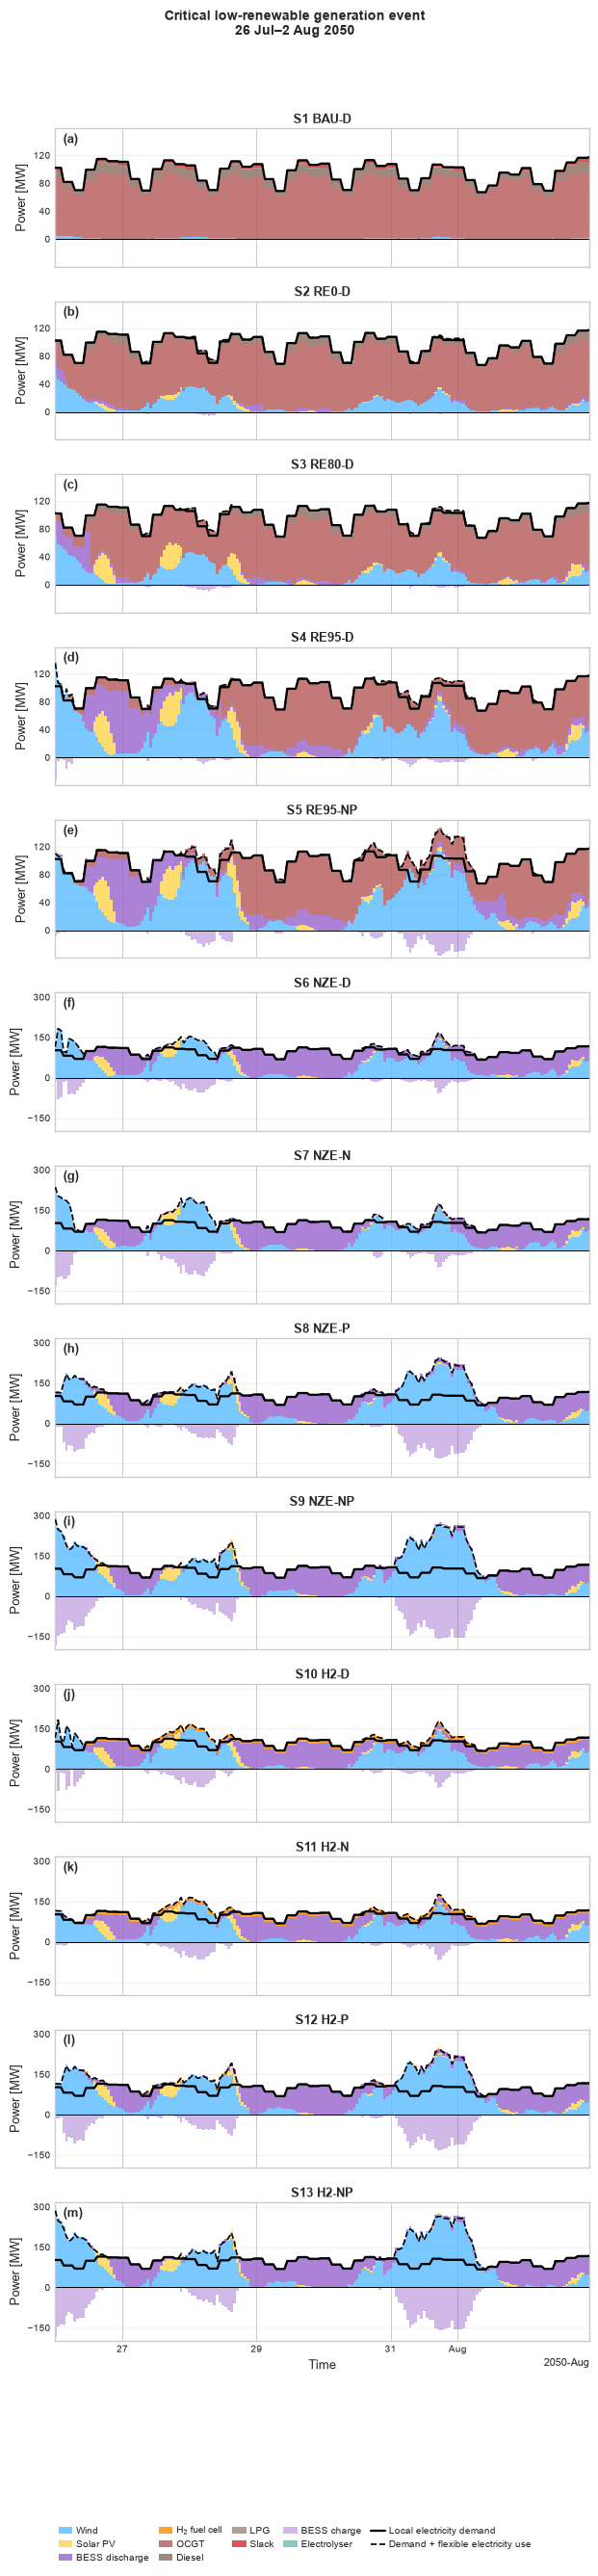

Saved figure to: output\output_magallanes\figures\figure_dispatch_critical_event_2050.png
  BAU–RE: -39.7 to 158.5 MW
  NZE–H2: -197.7 to 316.9 MW
Saved figure: output\output_magallanes\figures\figure_dispatch_favourable_summer_week_2050.png


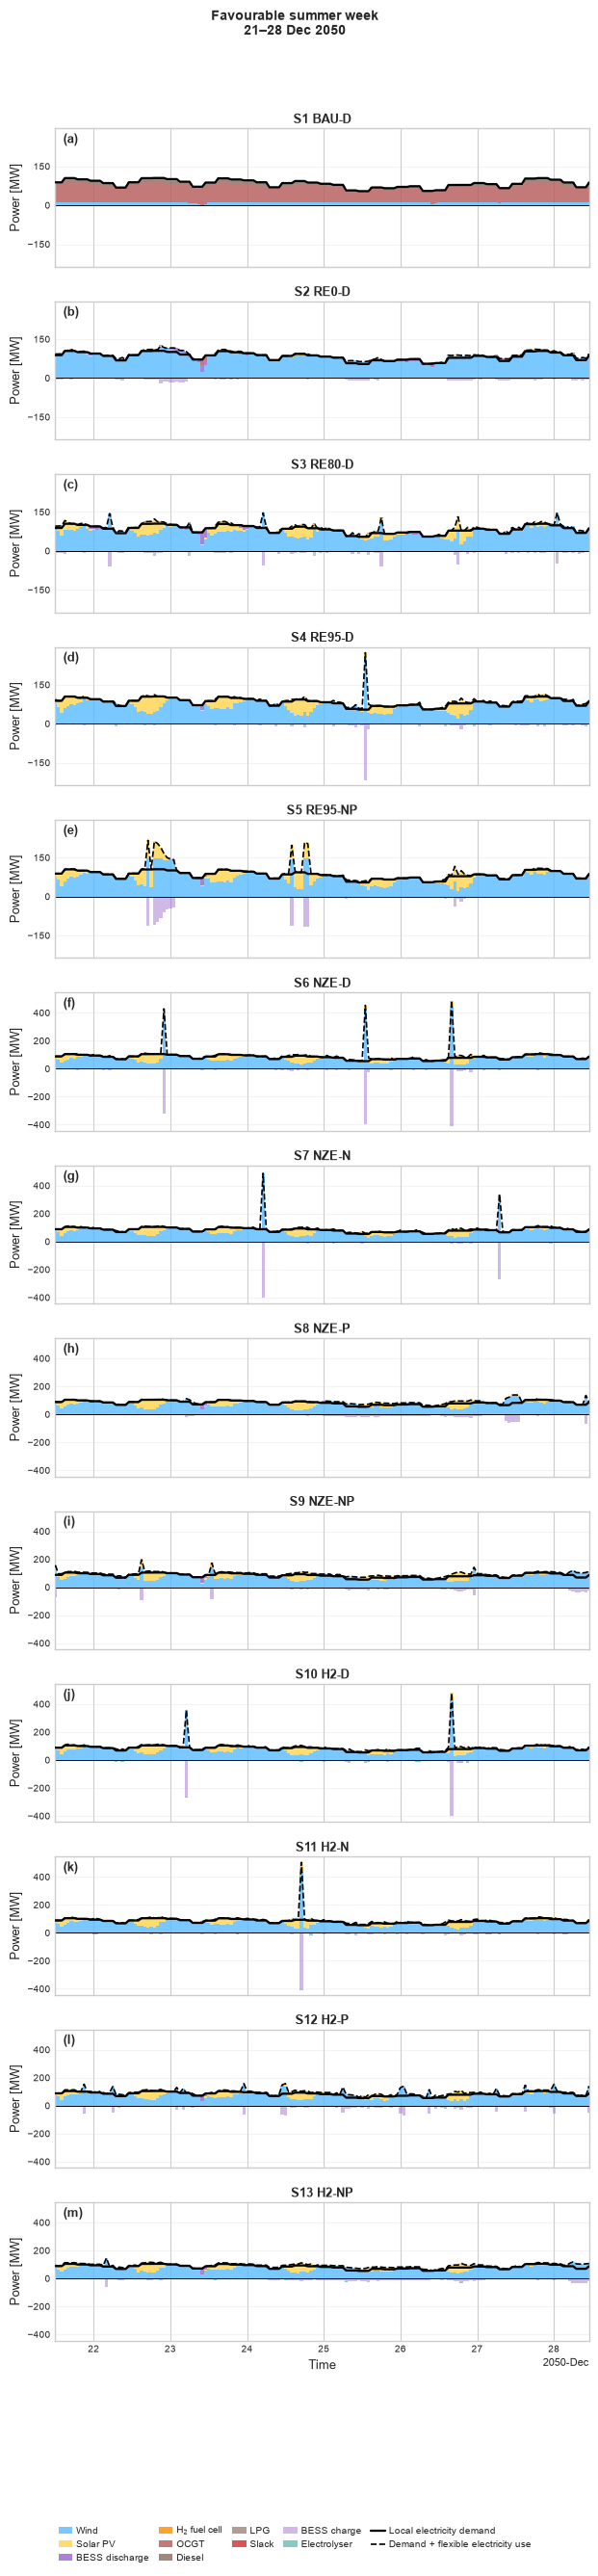

Saved figure to: output\output_magallanes\figures\figure_dispatch_favourable_summer_week_2050.png
  BAU–RE: -236.7 to 295.9 MW
  NZE–H2: -443.8 to 544.7 MW


,scenario,paper_label,period,period_start,period_end,local_demand_mwh,electricity_supply_mwh,flexible_electricity_use_mwh,supply_wind_mwh,supply_ocgt_mwh,supply_diesel_mwh,supply_lpg_mwh,supply_slack_mwh,supply_solar_mwh,supply_bess_mwh,negative_bess_charge_mwh,supply_h2_fuel_cell_mwh,negative_electrolyzer_mwh
0,BAU_disconnected,S1 BAU-D,critical_event,2050-07-26 00:00:00,2050-08-02 23:00:00,18251.932,18255.718,0.000,189.294,15517.872,1950.332,185.280,412.940,NaN,NaN,NaN,NaN,NaN
1,BAU_disconnected,S1 BAU-D,summer_week,2050-12-21 12:00:00,2050-12-28 11:00:00,14060.745,14101.870,0.000,2056.273,10347.312,1271.670,162.120,264.496,NaN,NaN,NaN,NaN,NaN
2,RE0_disconnected,S2 RE0-D,critical_event,2050-07-26 00:00:00,2050-08-02 23:00:00,18251.932,18383.867,91.739,2157.192,14285.305,1235.348,185.280,0.000,173.751,346.991,91.739,NaN,NaN
3,RE0_disconnected,S2 RE0-D,summer_week,2050-12-21 12:00:00,2050-12-28 11:00:00,14060.745,14896.669,633.749,14072.276,37.156,25.927,152.994,0.000,317.040,291.275,633.749,NaN,NaN
4,RE80_disconnected,S3 RE80-D,critical_event,2050-07-26 00:00:00,2050-08-02 23:00:00,18251.932,18485.258,176.672,2737.973,12978.991,1039.518,185.280,0.000,796.999,746.497,176.672,NaN,NaN
5,RE80_disconnected,S3 RE80-D,summer_week,2050-12-21 12:00:00,2050-12-28 11:00:00,14060.745,15032.082,809.511,12426.987,0.000,14.668,138.281,0.000,2129.774,322.372,809.511,NaN,NaN
6,RE95_disconnected,S4 RE95-D,critical_event,2050-07-26 00:00:00,2050-08-02 23:00:00,18251.932,18715.779,318.956,5559.921,9130.613,0.000,174.450,0.000,1017.961,2832.834,318.956,NaN,NaN
7,RE95_disconnected,S4 RE95-D,summer_week,2050-12-21 12:00:00,2050-12-28 11:00:00,14060.745,14847.442,621.221,12008.764,0.000,0.000,0.000,0.000,2758.548,80.130,621.221,NaN,NaN
8,RE95_interconnected_NP,S5 RE95-NP,critical_event,2050-07-26 00:00:00,2050-08-02 23:00:00,18251.932,19497.413,963.717,7225.502,7836.442,0.000,176.839,0.000,1017.961,3240.669,963.717,NaN,NaN
9,RE95_interconnected_NP,S5 RE95-NP,summer_week,2050-12-21 12:00:00,2050-12-28 11:00:00,14060.745,15404.835,1178.517,12524.365,0.000,0.000,0.000,0.000,2801.970,78.501,1178.517,NaN,NaN


Saved dispatch comparison summary to: output\output_magallanes\tables\dispatch_critical_vs_summer_summary_2050.csv


In [20]:
# Two separate dispatch figures:
#   1. Critical low-renewable generation event
#   2. Favourable summer week
#
# Each figure contains one panel per scenario.
# Y-axis scales are shared within the scenarios that keep thermal generation (BAU and RE)
# and within the zero-emission scenarios (NZE and H2). PtX is scaled separately.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator


# ── Configuration ─────────────────────────────────────────────────────────────
dispatch_comparison_year = globals().get(
    "detailed_year",
    2050,
)

SUMMER_MONTHS = (12, 1, 2)
SUMMER_WINDOW_DAYS = 7

# Leave as None for automatic selection.
# Example:
# SUMMER_WEEK_START = f"{dispatch_comparison_year}-01-15 00:00"
SUMMER_WEEK_START = None

figure_width = globals().get(
    "WORD_DOUBLE_COL_IN",
    7.1,
)

small_font = globals().get(
    "FONT_SIZE_SMALL",
    8,
)


# ── Scenario selection and labels ─────────────────────────────────────────────
def _scenario_technology_label(scenario_code):
    """Return the scenario family: BAU, RE0, RE80, RE95, NZE, H2 or PtX."""
    text = (
        str(scenario_code)
        .upper()
        .replace("-", "_")
    )

    parts = [
        part
        for part in text.split("_")
        if part
    ]

    if "PTX" in parts or "PTX" in text:
        return "PtX"

    for label in [
        "BAU",
        "RE0",
        "RE80",
        "RE95",
        "NZE",
        "H2",
    ]:
        if label in parts:
            return label

    return str(scenario_code)


def _short_scenario_label(scenario_code):
    """Return a concise label that retains the topology distinction."""
    if scenario_code in SCENARIO_TECH_LABELS:
        return SCENARIO_TECH_LABELS[scenario_code]

    technology = _scenario_technology_label(
        scenario_code
    )
    text = str(scenario_code).lower()

    if "interconnected" in text:
        return f"{technology}-I"

    if "disconnected" in text:
        return f"{technology}-D"

    return technology


dispatch_comparison_scenarios = [
    scenario_code
    for scenario_code in SCENARIO_PLOT_ORDER
    if scenario_code in scenario_results
]

# Include any additional future scenario without dropping the ordered S1–S13.
dispatch_comparison_scenarios += [
    scenario_code
    for scenario_code in scenario_results
    if scenario_code not in dispatch_comparison_scenarios
]


if not dispatch_comparison_scenarios:
    raise ValueError(
        "No scenarios were found in scenario_results."
    )


def _scale_group_label(scenario_code):
    technology = _scenario_technology_label(
        scenario_code
    )

    if technology in {
        "BAU",
        "RE0",
        "RE80",
        "RE95",
    }:
        return "BAU–RE"

    if technology in {
        "NZE",
        "H2",
    }:
        return "NZE–H2"

    if technology == "PtX":
        return "PtX"

    return technology


# ── General helpers ───────────────────────────────────────────────────────────
def _naive_datetime_index(values):
    index = pd.DatetimeIndex(
        pd.to_datetime(values)
    )

    if index.tz is not None:
        index = index.tz_localize(None)

    return index


def _naive_timestamp(value):
    timestamp = pd.Timestamp(value)

    if timestamp.tz is not None:
        timestamp = timestamp.tz_localize(None)

    return timestamp


def _normalise_timeseries_index(values):
    out = values.copy()

    out.index = _naive_datetime_index(
        out.index
    )

    return out.sort_index()


def _total_local_load(result):
    load = result["load"]

    if isinstance(
        load,
        pd.Series,
    ):
        return load.copy()

    return load.sum(axis=1)


def _format_period(start, end):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    if (
        start.year == end.year
        and start.month == end.month
    ):
        return (
            f"{start.day}–{end.day} "
            f"{start:%b %Y}"
        )

    if start.year == end.year:
        return (
            f"{start.day} {start:%b}–"
            f"{end.day} {end:%b %Y}"
        )

    return (
        f"{start.day} {start:%b %Y}–"
        f"{end.day} {end:%b %Y}"
    )


def _snapshot_hours(index):
    index = pd.DatetimeIndex(
        index
    )

    if len(index) == 0:
        return pd.Series(
            dtype=float,
            index=index,
        )

    timestamp_series = pd.Series(
        index,
        index=index,
    )

    durations = (
        timestamp_series.shift(-1)
        - timestamp_series
    )

    typical_duration = (
        durations
        .dropna()
        .median()
    )

    if pd.isna(
        typical_duration
    ):
        typical_duration = pd.Timedelta(
            hours=1
        )

    durations.iloc[-1] = (
        typical_duration
    )

    return (
        durations
        .dt.total_seconds()
        .div(3600.0)
    )


# ── Renewable potential for summer-week selection ────────────────────────────
def _renewable_potential_and_load(
    scenario_code,
    model_year,
):
    """
    Return available wind + solar generation and local load [MW].

    Renewable potential is based on installed capacity multiplied
    by p_max_pu, rather than realised dispatch.
    """
    result = (
        scenario_results[scenario_code]
        ["results"][model_year]
    )

    net = result["network"]

    generator_carriers = (
        net.generators["carrier"]
        .astype(str)
    )

    renewable_generators = (
        net.generators.index[
            generator_carriers.str.contains(
                r"wind|solar|pv",
                case=False,
                regex=True,
            )
        ]
    )

    if len(
        renewable_generators
    ) == 0:
        return None, None

    p_nom_fallback = pd.to_numeric(
        net.generators.get(
            "p_nom",
            pd.Series(
                0.0,
                index=net.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(0.0)

    p_nom = pd.to_numeric(
        net.generators.get(
            "p_nom_opt",
            pd.Series(
                np.nan,
                index=net.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(
        p_nom_fallback
    )

    p_nom = (
        p_nom
        .reindex(
            renewable_generators
        )
        .fillna(0.0)
    )

    static_p_max_pu = pd.to_numeric(
        net.generators.get(
            "p_max_pu",
            pd.Series(
                1.0,
                index=net.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(1.0)

    dynamic_p_max_pu = getattr(
        net.generators_t,
        "p_max_pu",
        pd.DataFrame(
            index=net.snapshots
        ),
    )

    p_max_pu = (
        dynamic_p_max_pu
        .reindex(
            index=net.snapshots,
            columns=renewable_generators,
        )
        .copy()
    )

    for generator in renewable_generators:
        p_max_pu[generator] = (
            pd.to_numeric(
                p_max_pu[generator],
                errors="coerce",
            )
            .fillna(
                float(
                    static_p_max_pu.get(
                        generator,
                        1.0,
                    )
                )
            )
        )

    renewable_potential = (
        p_max_pu
        .multiply(
            p_nom,
            axis=1,
        )
        .sum(axis=1)
    )

    renewable_potential.index = (
        _naive_datetime_index(
            renewable_potential.index
        )
    )

    local_load = _total_local_load(
        result
    )

    local_load.index = (
        _naive_datetime_index(
            local_load.index
        )
    )

    local_load = (
        local_load
        .reindex(
            renewable_potential.index
        )
        .fillna(0.0)
    )

    return (
        renewable_potential.sort_index(),
        local_load.sort_index(),
    )


# Prefer the fully renewable scenarios for selecting the weather period.
summer_reference_rank = {
    "NZE": 0,
    "H2": 1,
    "PtX": 2,
    "RE95": 3,
    "RE80": 4,
    "RE0": 5,
    "BAU": 6,
}

summer_reference_preferences = sorted(
    dispatch_comparison_scenarios,
    key=lambda scenario_code: (
        summer_reference_rank.get(
            _scenario_technology_label(
                scenario_code
            ),
            99,
        )
    ),
)

summer_reference_scenario = None
reference_renewable_potential = None
reference_local_load = None

for candidate in summer_reference_preferences:
    if (
        dispatch_comparison_year
        not in scenario_results[
            candidate
        ]["results"]
    ):
        continue

    candidate_potential, candidate_load = (
        _renewable_potential_and_load(
            candidate,
            dispatch_comparison_year,
        )
    )

    if (
        candidate_potential is not None
        and candidate_potential.max() > 1e-6
    ):
        summer_reference_scenario = (
            candidate
        )

        reference_renewable_potential = (
            candidate_potential
        )

        reference_local_load = (
            candidate_load
        )

        break


if summer_reference_scenario is None:
    raise ValueError(
        "No scenario with wind or solar capacity was found "
        "to identify the favourable summer week."
    )


# ── Select the favourable summer week ────────────────────────────────────────
reference_index = (
    reference_renewable_potential.index
)

if len(reference_index) < 2:
    raise ValueError(
        "Not enough snapshots to select a summer week."
    )

snapshot_interval = (
    reference_index
    .to_series()
    .diff()
    .dropna()
    .median()
)

if (
    pd.isna(snapshot_interval)
    or snapshot_interval
    <= pd.Timedelta(0)
):
    raise ValueError(
        "Could not determine the snapshot interval."
    )

summer_window_steps = int(
    round(
        pd.Timedelta(
            days=SUMMER_WINDOW_DAYS
        )
        / snapshot_interval
    )
)

summer_window_steps = max(
    summer_window_steps,
    1,
)


if SUMMER_WEEK_START is not None:
    summer_week_start = _naive_timestamp(
        SUMMER_WEEK_START
    )

    matching_positions = np.flatnonzero(
        reference_index
        == summer_week_start
    )

    if len(
        matching_positions
    ) == 0:
        raise ValueError(
            f"SUMMER_WEEK_START={SUMMER_WEEK_START} "
            "is not a model snapshot."
        )

    start_position = int(
        matching_positions[0]
    )

    end_position = (
        start_position
        + summer_window_steps
        - 1
    )

    if end_position >= len(
        reference_index
    ):
        raise ValueError(
            "The manually selected summer week extends "
            "beyond the available snapshots."
        )

    summer_week_end = (
        reference_index[
            end_position
        ]
    )

else:
    summer_snapshot_mask = pd.Series(
        reference_index.month.isin(
            SUMMER_MONTHS
        ).astype(float),
        index=reference_index,
    )

    complete_summer_window = (
        summer_snapshot_mask
        .rolling(
            window=summer_window_steps,
            min_periods=summer_window_steps,
        )
        .sum()
        .eq(
            float(
                summer_window_steps
            )
        )
    )

    rolling_renewable_potential = (
        reference_renewable_potential
        .rolling(
            window=summer_window_steps,
            min_periods=summer_window_steps,
        )
        .sum()
    )

    rolling_local_load = (
        reference_local_load
        .rolling(
            window=summer_window_steps,
            min_periods=summer_window_steps,
        )
        .sum()
    )

    favourable_week_score = (
        rolling_renewable_potential
        .div(
            rolling_local_load.replace(
                0.0,
                np.nan,
            )
        )
        .where(
            complete_summer_window
        )
    )

    valid_scores = (
        favourable_week_score
        .dropna()
    )

    if valid_scores.empty:
        raise ValueError(
            "No complete seven-day summer window was found."
        )

    summer_week_end = (
        valid_scores.idxmax()
    )

    end_position = int(
        reference_index.get_loc(
            summer_week_end
        )
    )

    start_position = (
        end_position
        - summer_window_steps
        + 1
    )

    summer_week_start = (
        reference_index[
            start_position
        ]
    )


print(
    "Favourable summer week selected from "
    f"{_short_scenario_label(summer_reference_scenario)}: "
    f"{_format_period(summer_week_start, summer_week_end)}"
)


# ── Period definitions ────────────────────────────────────────────────────────
period_definitions = [
    {
        "key": "critical_event",
        "title": (
            "Critical low-renewable generation event"
        ),
        "file_stub": "critical_event",
        "start": _naive_timestamp(
            critical_event_start
        ),
        "end": _naive_timestamp(
            critical_event_end
        ),
    },
    {
        "key": "summer_week",
        "title": (
            "Favourable summer week"
        ),
        "file_stub": "favourable_summer_week",
        "start": summer_week_start,
        "end": summer_week_end,
    },
]


# ── Prepare dispatch data ─────────────────────────────────────────────────────
dispatch_period_data = {}
dispatch_comparison_rows = []

for scenario_code in dispatch_comparison_scenarios:
    package = scenario_results[
        scenario_code
    ]

    if (
        dispatch_comparison_year
        not in package["results"]
    ):
        raise ValueError(
            f"{scenario_code} has no result for "
            f"{dispatch_comparison_year}."
        )

    result = package["results"][
        dispatch_comparison_year
    ]

    net = result["network"]

    supply, consumption = (
        _electricity_balance_for_network(
            net
        )
    )

    supply = (
        _normalise_timeseries_index(
            supply
        )
        .fillna(0.0)
    )

    consumption = (
        _normalise_timeseries_index(
            consumption
        )
        .fillna(0.0)
    )

    local_load = (
        _normalise_timeseries_index(
            _total_local_load(
                result
            )
        )
        .fillna(0.0)
    )

    consumption = (
        consumption
        .reindex(
            supply.index,
            fill_value=0.0,
        )
        .fillna(0.0)
    )

    local_load = (
        local_load
        .reindex(
            supply.index
        )
        .fillna(0.0)
    )

    for period in period_definitions:
        period_mask = (
            (supply.index >= period["start"])
            & (supply.index <= period["end"])
        )

        supply_period = (
            supply
            .loc[period_mask]
            .copy()
        )

        consumption_period = (
            consumption
            .loc[period_mask]
            .copy()
        )

        load_period = (
            local_load
            .loc[period_mask]
            .copy()
        )

        if supply_period.empty:
            raise ValueError(
                f"No snapshots found for {scenario_code}, "
                f"{period['title']}: "
                f"{period['start']} to {period['end']}."
            )

        dispatch_period_data[
            (
                scenario_code,
                period["key"],
            )
        ] = {
            "supply": supply_period,
            "consumption": consumption_period,
            "load": load_period,
        }

        snapshot_hours = _snapshot_hours(
            supply_period.index
        )

        supply_energy = (
            supply_period
            .mul(
                snapshot_hours,
                axis=0,
            )
        )

        consumption_energy = (
            consumption_period
            .mul(
                snapshot_hours,
                axis=0,
            )
        )

        load_energy = (
            load_period
            * snapshot_hours
        )

        summary_row = {
            "scenario": scenario_code,
            "paper_label": (
                _short_scenario_label(
                    scenario_code
                )
            ),
            "period": period["key"],
            "period_start": (
                supply_period.index.min()
            ),
            "period_end": (
                supply_period.index.max()
            ),
            "local_demand_mwh": float(
                load_energy.sum()
            ),
            "electricity_supply_mwh": float(
                supply_energy.sum().sum()
            ),
            "flexible_electricity_use_mwh": float(
                consumption_energy.sum().sum()
            ),
        }

        for column in supply_energy.columns:
            summary_row[
                f"supply_{column}_mwh"
            ] = float(
                supply_energy[
                    column
                ].sum()
            )

        for column in consumption_energy.columns:
            summary_row[
                f"negative_{column}_mwh"
            ] = float(
                consumption_energy[
                    column
                ].sum()
            )

        dispatch_comparison_rows.append(
            summary_row
        )


# ── Period-specific grouped y-axis limits ─────────────────────────────────────
scale_group_members = {}

for scenario_code in dispatch_comparison_scenarios:
    group_label = _scale_group_label(
        scenario_code
    )

    scale_group_members.setdefault(
        group_label,
        [],
    ).append(
        scenario_code
    )


def _calculate_group_ylim(
    period_key,
    scenario_codes,
):
    positive_max = 1.0
    negative_max = 0.0

    for scenario_code in scenario_codes:
        data = dispatch_period_data[
            (
                scenario_code,
                period_key,
            )
        ]

        supply_period = (
            data["supply"]
            .clip(lower=0.0)
        )

        consumption_period = (
            data["consumption"]
            .clip(lower=0.0)
        )

        load_period = (
            data["load"]
            .clip(lower=0.0)
        )

        flexible_use = (
            consumption_period
            .sum(axis=1)
        )

        total_supply = (
            supply_period
            .sum(axis=1)
        )

        total_electricity_use = (
            load_period
            + flexible_use
        )

        positive_max = max(
            positive_max,
            float(
                total_supply.max()
            ),
            float(
                load_period.max()
            ),
            float(
                total_electricity_use.max()
            ),
        )

        negative_max = max(
            negative_max,
            float(
                flexible_use.max()
            ),
        )

    upper_limit = (
        1.08
        * positive_max
    )

    if negative_max > 1e-6:
        lower_limit = (
            -1.08
            * negative_max
        )
    else:
        # Retain a small margin below zero without
        # forcing zero to the centre of the panel.
        lower_limit = (
            -0.035
            * upper_limit
        )

    return (
        lower_limit,
        upper_limit,
    )


period_group_y_limits = {}

for period in period_definitions:
    for (
        group_label,
        scenario_codes,
    ) in scale_group_members.items():
        period_group_y_limits[
            (
                period["key"],
                group_label,
            )
        ] = _calculate_group_ylim(
            period["key"],
            scenario_codes,
        )


# ── Plotting colours and labels ───────────────────────────────────────────────
fallback_colors = {
    "wind": "#5bbcff",
    "solar": "#ffd54f",
    "hydro": "#4fc3f7",
    "bess": "#8e6bbf",
    "h2_fuel_cell": "#2ca58d",
    "h2_turbine": "#158f75",
    "ocgt": "#7f7f7f",
    "gas": "#9e9e9e",
    "natural_gas": "#9e9e9e",
    "diesel": "#4d4d4d",
    "lpg": "#a1887f",
    "slack": "#d62728",
    "electrolyzer": "#00a6a6",
    "electrolyser": "#00a6a6",
    "asu": "#e67e22",
    "dac": "#c44e52",
}

plot_colors = fallback_colors.copy()

plot_colors.update(
    globals().get(
        "TECH_COLORS",
        {},
    )
)


def _dispatch_color(carrier):
    color_key = (
        "bess"
        if carrier == "bess_charge"
        else carrier
    )

    return plot_colors.get(
        color_key,
        "#999999",
    )


def _dispatch_legend_label(carrier):
    label_overrides = {
        "bess": "BESS discharge",
        "bess_charge": "BESS charge",
        "electrolyzer": "Electrolyser",
        "electrolyser": "Electrolyser",
        "asu": "ASU",
        "dac": "DAC",
        "h2_fuel_cell": (
            r"H$_2$ fuel cell"
        ),
        "h2_turbine": (
            r"H$_2$ turbine"
        ),
        "ocgt": "OCGT",
        "slack": "Slack",
    }

    if carrier in label_overrides:
        return label_overrides[
            carrier
        ]

    if callable(
        globals().get(
            "clean_technology_label"
        )
    ):
        return clean_technology_label(
            carrier
        )

    return (
        str(carrier)
        .replace("_", " ")
        .title()
    )


def _finish_dispatch_axis(
    ax,
    ylabel,
):
    if callable(
        globals().get(
            "finish_axis"
        )
    ):
        finish_axis(
            ax,
            ylabel=ylabel,
        )

    else:
        ax.set_ylabel(
            ylabel
        )

        ax.spines[
            "top"
        ].set_visible(False)

        ax.spines[
            "right"
        ].set_visible(False)

    ax.grid(
        axis="y",
        alpha=0.22,
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        labelsize=small_font - 1,
    )


def _add_panel_label(
    ax,
    text,
):
    if callable(
        globals().get(
            "panel_label"
        )
    ):
        panel_label(
            ax,
            text,
        )

    else:
        ax.text(
            0.01,
            0.97,
            text,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=small_font,
            fontweight="bold",
        )


# ── Individual panel ──────────────────────────────────────────────────────────
def _plot_dispatch_panel(
    ax,
    supply_period,
    consumption_period,
    load_period,
    y_limits,
    scenario_title,
    panel_text,
):
    active_supply_columns = [
        column
        for column in supply_period.columns
        if (
            supply_period[column]
            .clip(lower=0.0)
            .sum()
            > 1e-6
        )
    ]

    if active_supply_columns:
        ax.stackplot(
            supply_period.index,
            *[
                (
                    supply_period[column]
                    .fillna(0.0)
                    .clip(lower=0.0)
                    .to_numpy()
                )
                for column
                in active_supply_columns
            ],
            colors=[
                _dispatch_color(
                    column
                )
                for column
                in active_supply_columns
            ],
            alpha=0.82,
            linewidth=0.0,
            step="mid",
        )

    negative_stack = np.zeros(
        len(consumption_period),
        dtype=float,
    )

    for column in consumption_period.columns:
        values = (
            consumption_period[
                column
            ]
            .fillna(0.0)
            .clip(lower=0.0)
            .to_numpy()
        )

        if values.sum() <= 1e-6:
            continue

        previous_stack = (
            negative_stack.copy()
        )

        negative_stack += values

        ax.fill_between(
            consumption_period.index,
            -previous_stack,
            -negative_stack,
            step="mid",
            color=_dispatch_color(
                column
            ),
            alpha=0.46,
            linewidth=0.0,
        )

    flexible_use = (
        consumption_period
        .clip(lower=0.0)
        .sum(axis=1)
    )

    total_electricity_use = (
        load_period
        + flexible_use
    )

    ax.plot(
        load_period.index,
        load_period,
        color="black",
        linewidth=1.65,
        zorder=5,
    )

    if flexible_use.sum() > 1e-6:
        ax.plot(
            total_electricity_use.index,
            total_electricity_use,
            color="black",
            linewidth=1.20,
            linestyle="--",
            zorder=5,
        )

    ax.axhline(
        0.0,
        color="black",
        linewidth=0.70,
    )

    ax.set_xlim(
        supply_period.index.min(),
        supply_period.index.max(),
    )

    ax.set_ylim(
        y_limits
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(
            nbins=5,
        )
    )

    ax.margins(
        x=0.0
    )

    _finish_dispatch_axis(
        ax,
        ylabel="Power [MW]",
    )

    ax.set_title(
        scenario_title,
        fontsize=small_font + 1,
        fontweight="semibold",
        pad=4,
    )

    _add_panel_label(
        ax,
        panel_text,
    )

    if ax.get_legend() is not None:
        ax.get_legend().remove()


# ── Legend for each period ────────────────────────────────────────────────────
def _period_legend(
    period_key,
):
    used_supply_carriers = set()
    used_consumption_carriers = set()
    has_flexible_use = False

    for scenario_code in dispatch_comparison_scenarios:
        data = dispatch_period_data[
            (
                scenario_code,
                period_key,
            )
        ]

        for column in data[
            "supply"
        ].columns:
            if (
                data["supply"][column]
                .clip(lower=0.0)
                .sum()
                > 1e-6
            ):
                used_supply_carriers.add(
                    column
                )

        for column in data[
            "consumption"
        ].columns:
            if (
                data["consumption"][column]
                .clip(lower=0.0)
                .sum()
                > 1e-6
            ):
                used_consumption_carriers.add(
                    column
                )

                has_flexible_use = True

    preferred_supply_order = [
        "wind",
        "solar",
        "hydro",
        "bess",
        "h2_fuel_cell",
        "h2_turbine",
        "ocgt",
        "gas",
        "natural_gas",
        "diesel",
        "lpg",
        "slack",
    ]

    ordered_supply_carriers = [
        carrier
        for carrier in preferred_supply_order
        if carrier in used_supply_carriers
    ]

    ordered_supply_carriers += sorted(
        carrier
        for carrier in used_supply_carriers
        if carrier
        not in ordered_supply_carriers
    )

    preferred_consumption_order = [
        "bess_charge",
        "electrolyzer",
        "electrolyser",
        "asu",
        "dac",
    ]

    ordered_consumption_carriers = [
        carrier
        for carrier
        in preferred_consumption_order
        if carrier
        in used_consumption_carriers
    ]

    ordered_consumption_carriers += sorted(
        carrier
        for carrier
        in used_consumption_carriers
        if carrier
        not in ordered_consumption_carriers
    )

    handles = []
    labels = []
    seen_labels = set()

    for carrier in ordered_supply_carriers:
        label = _dispatch_legend_label(
            carrier
        )

        if label in seen_labels:
            continue

        handles.append(
            Patch(
                facecolor=_dispatch_color(
                    carrier
                ),
                edgecolor="none",
                alpha=0.82,
            )
        )

        labels.append(
            label
        )

        seen_labels.add(
            label
        )

    for carrier in ordered_consumption_carriers:
        label = _dispatch_legend_label(
            carrier
        )

        if label in seen_labels:
            continue

        handles.append(
            Patch(
                facecolor=_dispatch_color(
                    carrier
                ),
                edgecolor="none",
                alpha=0.46,
            )
        )

        labels.append(
            label
        )

        seen_labels.add(
            label
        )

    handles.append(
        Line2D(
            [0],
            [0],
            color="black",
            linewidth=1.65,
        )
    )

    labels.append(
        "Local electricity demand"
    )

    if has_flexible_use:
        handles.append(
            Line2D(
                [0],
                [0],
                color="black",
                linewidth=1.20,
                linestyle="--",
            )
        )

        labels.append(
            "Demand + flexible electricity use"
        )

    return (
        handles,
        labels,
    )


# ── Create one figure per period ──────────────────────────────────────────────
def _make_dispatch_period_figure(
    period,
):
    nrows = len(
        dispatch_comparison_scenarios
    )

    figure_height = max(
        2 * nrows + 1.5,
        8,
    )

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=1,
        figsize=(
            figure_width,
            figure_height,
        ),
        sharex=True,
        squeeze=False,
    )

    axes = axes[:, 0]

    for row_index, scenario_code in enumerate(
        dispatch_comparison_scenarios
    ):
        data = dispatch_period_data[
            (
                scenario_code,
                period["key"],
            )
        ]

        group_label = _scale_group_label(
            scenario_code
        )

        y_limits = period_group_y_limits[
            (
                period["key"],
                group_label,
            )
        ]

        _plot_dispatch_panel(
            ax=axes[row_index],
            supply_period=data["supply"],
            consumption_period=data[
                "consumption"
            ],
            load_period=data["load"],
            y_limits=y_limits,
            scenario_title=(
                _short_scenario_label(
                    scenario_code
                )
            ),
            panel_text=(
                f"({chr(97 + row_index)})"
            ),
        )

    for ax in axes[:-1]:
        ax.tick_params(
            axis="x",
            labelbottom=False,
        )

    date_locator = mdates.AutoDateLocator(
        minticks=4,
        maxticks=7,
    )

    axes[-1].xaxis.set_major_locator(
        date_locator
    )

    axes[-1].xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(
            date_locator
        )
    )

    axes[-1].set_xlabel(
        "Time"
    )

    legend_handles, legend_labels = (
        _period_legend(
            period["key"]
        )
    )

    legend_ncol = min(
        5,
        max(
            1,
            len(legend_labels),
        ),
    )

    legend_rows = int(
        np.ceil(
            len(legend_labels)
            / legend_ncol
        )
    )


    fig.legend(
        legend_handles,
        legend_labels,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.018,  # sube ligeramente la leyenda
        ),
        ncol=legend_ncol,
        frameon=False,
        fontsize=small_font - 1,
        columnspacing=1.0,
        handlelength=1.5,
        handletextpad=0.4,
    )

    fig.suptitle(
        (
            f"{period['title']}\n"
            f"{_format_period(period['start'], period['end'])}"
        ),
        x=0.5,
        y=0.985,
        ha="center",
        va="top",
        fontsize=small_font + 2,
        fontweight="semibold",
    )

    fig.subplots_adjust(
        top=0.94,      # acerca el primer panel al título
        bottom=0.105,  # acerca el último panel a la leyenda
        left=0.105,
        right=0.985,
        hspace=0.25,
    )

    figure_filename = (
        "figure_dispatch_"
        f"{period['file_stub']}_"
        f"{dispatch_comparison_year}.png"
    )

    if callable(
        globals().get(
            "save_paper_figure"
        )
    ):
        figure_path = save_paper_figure(
            fig,
            figure_filename,
        )

    else:
        figure_path = Path(
            figure_filename
        )

        fig.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

    print(
        f"Saved figure to: {figure_path}"
    )

    for group_label in scale_group_members:
        limits = period_group_y_limits[
            (
                period["key"],
                group_label,
            )
        ]

        print(
            f"  {group_label}: "
            f"{limits[0]:.1f} to "
            f"{limits[1]:.1f} MW"
        )

    return figure_path


dispatch_figure_paths = {}

for period in period_definitions:
    dispatch_figure_paths[
        period["key"]
    ] = _make_dispatch_period_figure(
        period
    )


# ── Export comparison summary ─────────────────────────────────────────────────
dispatch_comparison_summary = pd.DataFrame(
    dispatch_comparison_rows
)

display(
    dispatch_comparison_summary.round(3)
)

table_export_dir = Path(
    globals().get(
        "TABLE_EXPORT_DIR",
        ".",
    )
)

table_export_dir.mkdir(
    parents=True,
    exist_ok=True,
)

dispatch_comparison_summary_path = (
    table_export_dir
    / (
        "dispatch_critical_vs_summer_summary_"
        f"{dispatch_comparison_year}.csv"
    )
)

dispatch_comparison_summary.to_csv(
    dispatch_comparison_summary_path,
    index=False,
)

print(
    "Saved dispatch comparison summary to: "
    f"{dispatch_comparison_summary_path}"
)

## 8. Curtailment

Curtailment is calculated as available wind and solar generation minus dispatched generation, using optimized capacities and exported time-dependent availability.

In [ ]:
# Curtailment calculation

def _get_nominal_capacity_for_curtailment(net, gen_ids):
    """
    Return optimized capacity when available, otherwise nominal capacity.
    Works for both expansion runs and fixed-capacity re-operation.
    """
    gens = net.generators.loc[gen_ids].copy()

    if "p_nom_opt" in gens.columns:
        p_nom = gens["p_nom_opt"].copy()
        p_nom = p_nom.fillna(gens["p_nom"])
    else:
        p_nom = gens["p_nom"].copy()

    return p_nom.astype(float).fillna(0.0)


def build_vre_curtailment_table(net, freq="YS"):
    """
    Build a wind and solar curtailment table.

    Curtailment is calculated as:
        available VRE = p_nom * p_max_pu
        curtailed VRE = max(available VRE - dispatched VRE, 0)

    Parameters
    ----------
    net : pypsa.Network
    freq : str
        "YS" for annual, "MS" for monthly, "D" for daily, "h" for hourly.
    """
    if len(net.generators) == 0:
        return pd.DataFrame()

    rows = []

    vre_carriers = ["wind", "solar"]

    for carrier in vre_carriers:
        gen_ids = net.generators.index[
            net.generators["carrier"].astype(str).str.lower() == carrier
        ].tolist()

        if not gen_ids:
            continue

        # Safer check: do not silently assume p_max_pu = 1 if missing.
        missing_profiles = [g for g in gen_ids if g not in net.generators_t.p_max_pu.columns]
        if missing_profiles:
            raise ValueError(
                f"Missing p_max_pu profiles for {carrier}: {missing_profiles}. "
                "Do not calculate curtailment with assumed p_max_pu = 1.0."
            )

        p_nom = _get_nominal_capacity_for_curtailment(net, gen_ids)

        available = net.generators_t.p_max_pu[gen_ids].clip(lower=0.0).multiply(p_nom, axis=1)
        dispatch = net.generators_t.p[gen_ids].fillna(0.0).clip(lower=0.0)

        curtailed = (available - dispatch).clip(lower=0.0)

        for gen_id in gen_ids:
            bus = net.generators.loc[gen_id, "bus"]

            tmp = pd.DataFrame({
                "available_mwh": available[gen_id],
                "dispatch_mwh": dispatch[gen_id],
                "curtailment_mwh": curtailed[gen_id],
            })

            if freq is not None:
                tmp = tmp.resample(freq).sum()

            for ts, r in tmp.iterrows():
                rows.append({
                    "period": ts,
                    "carrier": carrier,
                    "generator": gen_id,
                    "bus": bus,
                    "available_mwh": float(r["available_mwh"]),
                    "dispatch_mwh": float(r["dispatch_mwh"]),
                    "curtailment_mwh": float(r["curtailment_mwh"]),
                })

    out = pd.DataFrame(rows)

    if out.empty:
        return out

    out["curtailment_share_available_pct"] = np.where(
        out["available_mwh"] > 0,
        100 * out["curtailment_mwh"] / out["available_mwh"],
        np.nan,
    )

    return out


In [22]:
# Curtailment summary tables
curtailment_selection = "all"   # "all", one scenario code, or a list


def _resolve_selection(selection):
    if selection == "all":
        return list(scenario_results.keys())
    if isinstance(selection, str):
        return [selection]
    return list(selection)


curtailment_annual_tables = []
curtailment_monthly_tables = []

for scenario_code in _resolve_selection(curtailment_selection):
    package = scenario_results[scenario_code]
    paper_id = package["metadata"].get("paper_id", "")
    label = scenario_label(scenario_code, paper_id=paper_id)

    for year in years:
        net = package["results"][year]["network"]

        annual_df = build_vre_curtailment_table(net, freq="YS")
        if not annual_df.empty:
            annual_df = annual_df.copy()
            annual_df["scenario"] = scenario_code
            annual_df["paper_id"] = paper_id
            annual_df["scenario_label"] = label
            annual_df["year"] = year
            curtailment_annual_tables.append(annual_df)

        monthly_df = build_vre_curtailment_table(net, freq="MS")
        if not monthly_df.empty:
            monthly_df = monthly_df.copy()
            monthly_df["scenario"] = scenario_code
            monthly_df["paper_id"] = paper_id
            monthly_df["scenario_label"] = label
            monthly_df["year"] = year
            monthly_df["month_num"] = monthly_df["period"].dt.month
            monthly_df["month"] = monthly_df["period"].dt.strftime("%b")
            curtailment_monthly_tables.append(monthly_df)

curtailment_annual_all = pd.concat(curtailment_annual_tables, ignore_index=True) if curtailment_annual_tables else pd.DataFrame()
curtailment_monthly_all = pd.concat(curtailment_monthly_tables, ignore_index=True) if curtailment_monthly_tables else pd.DataFrame()

if not curtailment_annual_all.empty:
    curtailment_annual_summary = (
        curtailment_annual_all
        .groupby(["scenario", "paper_id", "scenario_label", "year", "carrier"], as_index=False)
        [["available_mwh", "dispatch_mwh", "curtailment_mwh"]]
        .sum()
    )
    curtailment_annual_summary["curtailment_share_available_pct"] = np.where(
        curtailment_annual_summary["available_mwh"] > 0,
        100 * curtailment_annual_summary["curtailment_mwh"] / curtailment_annual_summary["available_mwh"],
        np.nan,
    )

    curtailment_annual_total = (
        curtailment_annual_summary
        .groupby(["scenario", "paper_id", "scenario_label", "year"], as_index=False)
        [["available_mwh", "dispatch_mwh", "curtailment_mwh"]]
        .sum()
    )
    curtailment_annual_total["curtailment_share_available_pct"] = np.where(
        curtailment_annual_total["available_mwh"] > 0,
        100 * curtailment_annual_total["curtailment_mwh"] / curtailment_annual_total["available_mwh"],
        np.nan,
    )
else:
    curtailment_annual_summary = pd.DataFrame()
    curtailment_annual_total = pd.DataFrame()

if not curtailment_monthly_all.empty:
    curtailment_monthly_summary = (
        curtailment_monthly_all
        .groupby(["scenario", "paper_id", "scenario_label", "year", "month_num", "month", "carrier"], as_index=False)
        [["available_mwh", "dispatch_mwh", "curtailment_mwh"]]
        .sum()
    )
    curtailment_monthly_summary["curtailment_share_available_pct"] = np.where(
        curtailment_monthly_summary["available_mwh"] > 0,
        100 * curtailment_monthly_summary["curtailment_mwh"] / curtailment_monthly_summary["available_mwh"],
        np.nan,
    )
else:
    curtailment_monthly_summary = pd.DataFrame()

print("Curtailment annual summary rows:", len(curtailment_annual_summary))
print("Curtailment monthly summary rows:", len(curtailment_monthly_summary))
if not curtailment_annual_total.empty:
    display(curtailment_annual_total.head())


Curtailment annual summary rows: 113
Curtailment monthly summary rows: 1356


,scenario,paper_id,scenario_label,year,available_mwh,dispatch_mwh,curtailment_mwh,curtailment_share_available_pct
0,BAU_disconnected,S1,S1 BAU disconnected,2025,67777.021208,67777.021208,1.656750e-12,2.444412e-15
1,BAU_disconnected,S1,S1 BAU disconnected,2030,67777.021208,67777.021208,1.667422e-12,2.460158e-15
2,BAU_disconnected,S1,S1 BAU disconnected,2040,67861.755554,67861.755554,1.649651e-12,2.430900e-15
3,BAU_disconnected,S1,S1 BAU disconnected,2045,67777.021208,67777.021208,1.648249e-12,2.431871e-15
4,BAU_disconnected,S1,S1 BAU disconnected,2050,67777.021208,67777.021208,1.653162e-12,2.439119e-15


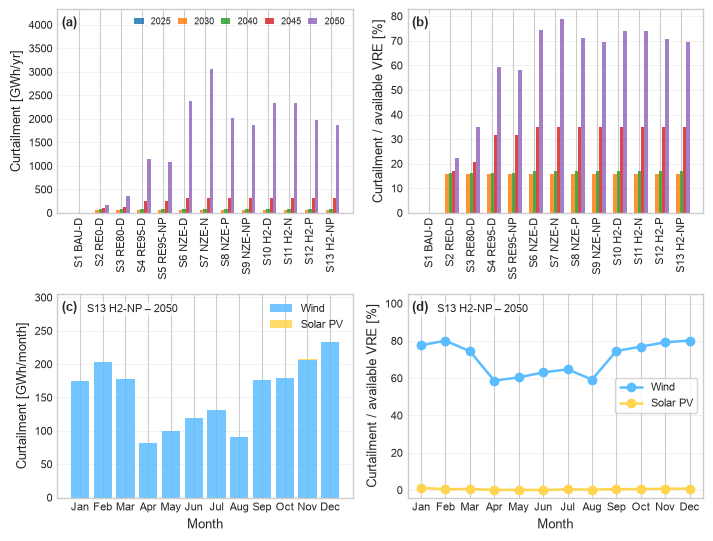

In [23]:
# Curtailment figures
curtailment_focus_scenario = active_scenario
curtailment_focus_year = detailed_year

if curtailment_annual_total.empty:
    raise ValueError("No curtailment summary available. Run the previous cell first.")

# Ordered labels for the annual plots
scenario_order = [s for s in SCENARIO_PLOT_ORDER if s in curtailment_annual_total["scenario"].unique()]
plot_df = curtailment_annual_total.copy()
plot_df["scenario"] = pd.Categorical(plot_df["scenario"], categories=scenario_order, ordered=True)
plot_df = plot_df.sort_values(["scenario", "year"]).copy()
plot_df["x_label"] = [scenario_axis_label(s) for s in plot_df["scenario"]]

unique_scenarios = plot_df[["scenario", "paper_id", "x_label"]].drop_duplicates().sort_values("scenario")
scenario_codes = unique_scenarios["scenario"].tolist()
xlabels = [SCENARIO_TECH_LABELS.get(s, scenario_label(s)) for s in unique_scenarios["scenario"].tolist()]
unique_years = sorted(plot_df["year"].unique())
x = np.arange(len(scenario_codes))
bar_width = 0.8 / max(len(unique_years), 1)

fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_2COL_LARGE)

# (a) Total annual curtailment [GWh/yr]
ax = axes[0, 0]
for i, year in enumerate(unique_years):
    tmp = plot_df[plot_df["year"] == year].set_index("scenario").reindex(scenario_codes)
    values = tmp["curtailment_mwh"].fillna(0).values / 1e3
    ax.bar(x + (i - (len(unique_years)-1)/2) * bar_width, values, width=bar_width, label=str(year), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(xlabels, rotation=90, ha="center", fontsize=6.5)
finish_axis(ax, ylabel="Curtailment [GWh/yr]")
ax.set_ylim(top=1.35 * ax.get_ylim()[1])
ax.legend(ncol=5, loc="upper right", frameon=False, fontsize=6.5, columnspacing=0.8, handlelength=1.0)
panel_label(ax, "(a)")

# (b) Curtailment share of available VRE [%]
ax = axes[0, 1]
for i, year in enumerate(unique_years):
    tmp = plot_df[plot_df["year"] == year].set_index("scenario").reindex(scenario_codes)
    values = tmp["curtailment_share_available_pct"].fillna(0).values
    ax.bar(x + (i - (len(unique_years)-1)/2) * bar_width, values, width=bar_width, label=str(year), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(xlabels, rotation=90, ha="center", fontsize=6.5)
finish_axis(ax, ylabel="Curtailment / available VRE [%]")
panel_label(ax, "(b)")

# Monthly deep-dive for a selected scenario/year
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_focus = curtailment_monthly_summary[
    (curtailment_monthly_summary["scenario"] == curtailment_focus_scenario) &
    (curtailment_monthly_summary["year"] == curtailment_focus_year)
].copy()
monthly_focus["month"] = pd.Categorical(monthly_focus["month"], categories=month_order, ordered=True)
monthly_focus = monthly_focus.sort_values(["month", "carrier"])

# (c) Monthly curtailment [GWh/month]
ax = axes[1, 0]
if not monthly_focus.empty:
    pivot_gwh = monthly_focus.pivot_table(index="month", columns="carrier", values="curtailment_mwh", aggfunc="sum").fillna(0) / 1e3
    bottom = np.zeros(len(pivot_gwh))
    for carrier in [c for c in ["wind", "solar"] if c in pivot_gwh.columns]:
        vals = pivot_gwh[carrier].values
        ax.bar(pivot_gwh.index.astype(str), vals, bottom=bottom, color=TECH_COLORS.get(carrier, "#999999"), alpha=0.85, label=clean_technology_label(carrier))
        bottom += vals
    ax.set_ylim(top=1.25 * ax.get_ylim()[1])
    ax.legend(loc="upper right", frameon=False)
finish_axis(ax, xlabel="Month", ylabel="Curtailment [GWh/month]")
ax.tick_params(axis="x", rotation=0)
ax.text(0.10, 0.95, f"{SCENARIO_TECH_LABELS.get(curtailment_focus_scenario) or scenario_label(curtailment_focus_scenario)} – {curtailment_focus_year}", transform=ax.transAxes, ha="left", va="top", fontsize=FONT_SIZE_SMALL, bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.2))
panel_label(ax, "(c)")

# (d) Monthly curtailment share [%]
ax = axes[1, 1]
if not monthly_focus.empty:
    pivot_pct = monthly_focus.pivot_table(index="month", columns="carrier", values="curtailment_share_available_pct", aggfunc="sum").fillna(0)
    for carrier in [c for c in ["wind", "solar"] if c in pivot_pct.columns]:
        ax.plot(pivot_pct.index.astype(str), pivot_pct[carrier].values, marker="o", linewidth=1.8, label=clean_technology_label(carrier), color=TECH_COLORS.get(carrier, "#999999"))
    ax.set_ylim(top=1.25 * ax.get_ylim()[1])
    ax.legend(loc="center right", frameon=True)
finish_axis(ax, xlabel="Month", ylabel="Curtailment / available VRE [%]")
ax.tick_params(axis="x", rotation=0)
ax.text(0.10, 0.95, f"{SCENARIO_TECH_LABELS.get(curtailment_focus_scenario) or scenario_label(curtailment_focus_scenario)} – {curtailment_focus_year}", transform=ax.transAxes, ha="left", va="top", fontsize=FONT_SIZE_SMALL, bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.2))
panel_label(ax, "(d)")

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


## 9. Hydrogen and UHS operation

This section reports hydrogen conversion, storage inventories, installed capacities, and annual operation for the active scenario and detailed year.

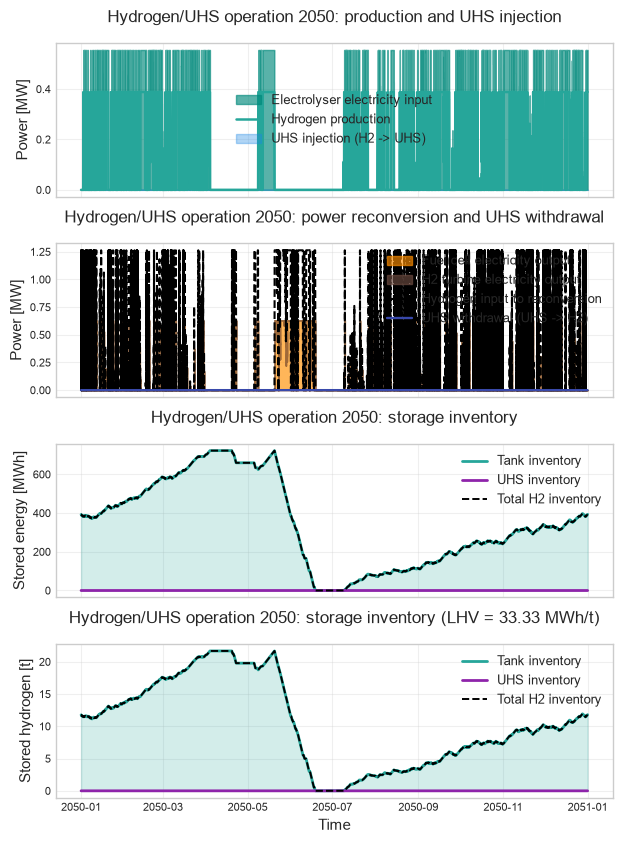

,carrier,bus0,bus1,efficiency,capacity_mw
name,,,,,
h2_electrolyzer_puerto_williams,electrolyzer,elec_puerto_williams,h2_puerto_williams,0.6994,0.555143
h2_electrolyzer_cabo_negro,electrolyzer,elec_cabo_negro,h2_cabo_negro,0.6994,0.000000
h2_electrolyzer_puerto_natales,electrolyzer,elec_puerto_natales,h2_puerto_natales,0.6994,0.000000
h2_electrolyzer_porvenir,electrolyzer,elec_porvenir,h2_porvenir,0.6994,0.000000
h2_fuel_cell_puerto_williams,h2_fuel_cell,h2_puerto_williams,elec_puerto_williams,0.5000,1.263280
h2_fuel_cell_cabo_negro,h2_fuel_cell,h2_cabo_negro,elec_cabo_negro,0.5000,0.000000
h2_fuel_cell_puerto_natales,h2_fuel_cell,h2_puerto_natales,elec_puerto_natales,0.5000,0.000000
h2_fuel_cell_porvenir,h2_fuel_cell,h2_porvenir,elec_porvenir,0.5000,0.000000


,carrier,bus,standing_loss,energy_capacity_mwh
name,,,,
h2_surface_tank_puerto_williams,hydrogen_storage,h2_puerto_williams,0.0,722.613432
h2_surface_tank_cabo_negro,hydrogen_storage,h2_cabo_negro,0.0,0.000000
h2_surface_tank_puerto_natales,hydrogen_storage,h2_puerto_natales,0.0,0.000000
h2_surface_tank_porvenir,hydrogen_storage,h2_porvenir,0.0,0.000000


,value
electrolyser_input_mwh,1986.068
hydrogen_production_mwh,1389.056
uhs_injection_mwh,0.000
uhs_withdrawal_mwh,0.000
hydrogen_reconversion_input_mwh,1389.056
fuel_cell_output_mwh,694.528
h2_turbine_output_mwh,0.000
peak_tank_inventory_mwh,722.613
peak_uhs_inventory_mwh,0.000
peak_total_h2_inventory_mwh,722.613


In [24]:
# Hydrogen and UHS operation
analysis_year = detailed_year
hydrogen_link_carriers = ["electrolyzer", "h2_fuel_cell", "h2_turbine", "uhs_injection", "uhs_withdrawal"]
hydrogen_store_carriers = ["hydrogen_storage", "uhs_storage"]

hydrogen_links = n.links[n.links["carrier"].isin(hydrogen_link_carriers)].copy()
hydrogen_stores = (
    n.stores[n.stores["carrier"].isin(hydrogen_store_carriers)].copy()
    if "carrier" in n.stores.columns
    else n.stores.copy()
)

if hydrogen_links.empty and hydrogen_stores.empty:
    print(
        f"No hydrogen/UHS assets in the network for {analysis_year}. "
        f"enable_hydrogen={scenario_results[active_scenario]['metadata']['enable_hydrogen']}."
    )
else:

    def _zero_series() -> pd.Series:
        """Return a zero-valued series aligned with the network snapshots."""
        return pd.Series(0.0, index=n.snapshots)

    def _link_input_series(link_index: pd.Index) -> pd.Series:
        """Aggregate electricity input (p0) for the given link indices."""
        if len(link_index) == 0:
            return _zero_series()
        return n.links_t.p0[link_index].clip(lower=0).sum(axis=1)

    def _link_output_series(link_index: pd.Index) -> pd.Series:
        """Aggregate useful output (p0 * efficiency) for the given link indices."""
        if len(link_index) == 0:
            return _zero_series()
        efficiency = n.links.loc[link_index, 'efficiency'].fillna(1.0)
        dispatch = n.links_t.p0[link_index].clip(lower=0)
        return dispatch.multiply(efficiency, axis=1).sum(axis=1)

    electrolyzer_links = hydrogen_links.index[hydrogen_links["carrier"] == "electrolyzer"]
    fuel_cell_links = hydrogen_links.index[hydrogen_links["carrier"] == "h2_fuel_cell"]
    turbine_links = hydrogen_links.index[hydrogen_links["carrier"] == "h2_turbine"]
    uhs_injection_links = hydrogen_links.index[hydrogen_links["carrier"] == "uhs_injection"]
    uhs_withdrawal_links = hydrogen_links.index[hydrogen_links["carrier"] == "uhs_withdrawal"]

    electrolyzer_power = _link_input_series(electrolyzer_links)
    hydrogen_production = _link_output_series(electrolyzer_links)
    fuel_cell_power = _link_output_series(fuel_cell_links)
    turbine_power = _link_output_series(turbine_links)
    hydrogen_to_power = fuel_cell_power + turbine_power
    hydrogen_reconversion_input = _link_input_series(fuel_cell_links) + _link_input_series(turbine_links)

    uhs_injection_power = _link_input_series(uhs_injection_links)
    uhs_withdrawal_power = _link_output_series(uhs_withdrawal_links)

    tank_stores = hydrogen_stores.index[hydrogen_stores["carrier"] == "hydrogen_storage"]
    uhs_stores = hydrogen_stores.index[hydrogen_stores["carrier"] == "uhs_storage"]

    tank_inventory = _zero_series() if len(tank_stores) == 0 else n.stores_t.e[tank_stores].sum(axis=1)
    uhs_inventory = _zero_series() if len(uhs_stores) == 0 else n.stores_t.e[uhs_stores].sum(axis=1)
    hydrogen_inventory = tank_inventory + uhs_inventory

    tank_inventory_ton = tank_inventory / H2_LHV_MWH_PER_TON
    uhs_inventory_ton = uhs_inventory / H2_LHV_MWH_PER_TON
    hydrogen_inventory_ton = hydrogen_inventory / H2_LHV_MWH_PER_TON

    fig, axes = plt.subplots(4, 1, figsize=(WORD_DOUBLE_COL_IN, 8.5), sharex=True)

    axes[0].fill_between(
        electrolyzer_power.index, 0, electrolyzer_power,
        color=TECH_COLORS.get("electrolyzer", '#00897b'), alpha=0.65,
        label="Electrolyser electricity input", step="mid"
    )
    axes[0].plot(
        hydrogen_production.index, hydrogen_production,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), linewidth=1.8,
        label='Hydrogen production',
    )
    axes[0].fill_between(
        uhs_injection_power.index, 0, uhs_injection_power,
        color=TECH_COLORS.get("uhs_injection", '#1e88e5'), alpha=0.35,
        label='UHS injection (H2 -> UHS)', step="mid"
    )
    axes[0].set_title(f'Hydrogen/UHS operation {analysis_year}: production and UHS injection', fontsize=12, pad=15)
    axes[0].set_ylabel("Power [MW]", fontsize=11)
    axes[0].legend(loc="best", fontsize=9)
    axes[0].grid(True, alpha=0.3)

    axes[1].fill_between(
        fuel_cell_power.index, 0, fuel_cell_power,
        color=TECH_COLORS.get("h2_fuel_cell", '#ff8f00'), alpha=0.65,
        label='Fuel cell electricity output', step="mid"
    )
    axes[1].fill_between(
        turbine_power.index, fuel_cell_power, hydrogen_to_power,
        color=TECH_COLORS.get("h2_turbine", '#6d4c41'), alpha=0.65,
        label='H2 turbine electricity output', step="mid"
    )
    axes[1].plot(
        hydrogen_reconversion_input.index, hydrogen_reconversion_input,
        color="black", linewidth=1.5, linestyle="--",
        label='Hydrogen input to reconversion'
    )
    axes[1].plot(
        uhs_withdrawal_power.index, uhs_withdrawal_power,
        color=TECH_COLORS.get("uhs_withdrawal", '#3949ab'), linewidth=1.7,
        label='UHS withdrawal (UHS -> H2)'
    )
    axes[1].set_title(f'Hydrogen/UHS operation {analysis_year}: power reconversion and UHS withdrawal', fontsize=12, pad=15)
    axes[1].set_ylabel("Power [MW]", fontsize=11)
    axes[1].legend(loc="best", fontsize=9)
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(
        tank_inventory.index, tank_inventory,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), linewidth=2,
        label='Tank inventory'
    )
    axes[2].plot(
        uhs_inventory.index, uhs_inventory,
        color=TECH_COLORS.get("uhs_storage", '#8e24aa'), linewidth=2,
        label='UHS inventory'
    )
    axes[2].plot(
        hydrogen_inventory.index, hydrogen_inventory,
        color="black", linewidth=1.4, linestyle="--",
        label='Total H2 inventory'
    )
    axes[2].fill_between(
        tank_inventory.index, 0, tank_inventory,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), alpha=0.2
    )
    axes[2].fill_between(
        uhs_inventory.index, 0, uhs_inventory,
        color=TECH_COLORS.get("uhs_storage", '#8e24aa'), alpha=0.15
    )
    axes[2].set_title(f'Hydrogen/UHS operation {analysis_year}: storage inventory', fontsize=12, pad=15)
    axes[2].set_ylabel("Stored energy [MWh]", fontsize=11)
    axes[2].legend(loc="best", fontsize=9)
    axes[2].grid(True, alpha=0.3)

    axes[3].plot(
        tank_inventory_ton.index, tank_inventory_ton,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), linewidth=2,
        label='Tank inventory'
    )
    axes[3].plot(
        uhs_inventory_ton.index, uhs_inventory_ton,
        color=TECH_COLORS.get("uhs_storage", '#8e24aa'), linewidth=2,
        label='UHS inventory'
    )
    axes[3].plot(
        hydrogen_inventory_ton.index, hydrogen_inventory_ton,
        color="black", linewidth=1.4, linestyle="--",
        label='Total H2 inventory'
    )
    axes[3].fill_between(
        tank_inventory_ton.index, 0, tank_inventory_ton,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), alpha=0.2
    )
    axes[3].fill_between(
        uhs_inventory_ton.index, 0, uhs_inventory_ton,
        color=TECH_COLORS.get("uhs_storage", '#8e24aa'), alpha=0.15
    )
    axes[3].set_title(f'Hydrogen/UHS operation {analysis_year}: storage inventory (LHV = {H2_LHV_MWH_PER_TON} MWh/t)', fontsize=12, pad=15)
    axes[3].set_ylabel("Stored hydrogen [t]", fontsize=11)
    axes[3].set_xlabel("Time", fontsize=11)
    axes[3].legend(loc="best", fontsize=9)
    axes[3].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    link_capacity_column = "p_nom_opt" if "p_nom_opt" in hydrogen_links.columns else "p_nom"
    link_caps = hydrogen_links[["carrier", "bus0", "bus1", "efficiency"]].copy()
    link_caps["capacity_mw"] = hydrogen_links[link_capacity_column]

    store_caps = pd.DataFrame()
    if not hydrogen_stores.empty:
        store_capacity_column = "e_nom_opt" if "e_nom_opt" in hydrogen_stores.columns else "e_nom"
        store_caps = hydrogen_stores[["carrier", "bus", "standing_loss"]].copy()
        store_caps["energy_capacity_mwh"] = hydrogen_stores[store_capacity_column]

    operation_summary = pd.Series({
        "electrolyser_input_mwh": electrolyzer_power.sum(),
        "hydrogen_production_mwh": hydrogen_production.sum(),
        "uhs_injection_mwh": uhs_injection_power.sum(),
        "uhs_withdrawal_mwh": uhs_withdrawal_power.sum(),
        "hydrogen_reconversion_input_mwh": hydrogen_reconversion_input.sum(),
        "fuel_cell_output_mwh": fuel_cell_power.sum(),
        "h2_turbine_output_mwh": turbine_power.sum(),
        "peak_tank_inventory_mwh": tank_inventory.max(),
        "peak_uhs_inventory_mwh": uhs_inventory.max(),
        "peak_total_h2_inventory_mwh": hydrogen_inventory.max(),
        "peak_tank_inventory_ton": tank_inventory_ton.max(),
        "peak_uhs_inventory_ton": uhs_inventory_ton.max(),
        "peak_total_h2_inventory_ton": hydrogen_inventory_ton.max(),
    }, name="value").to_frame()

    display(link_caps.sort_values(["carrier", "capacity_mw"], ascending=[True, False]))
    if not store_caps.empty:
        display(store_caps.sort_values(["carrier", "energy_capacity_mwh"], ascending=[True, False]))
    display(operation_summary.round(3))


Saved figure: output\output_magallanes\figures\figure_storage_operation_multiscale_2050.png
Saved figure to: output\output_magallanes\figures\figure_storage_operation_multiscale_2050.png


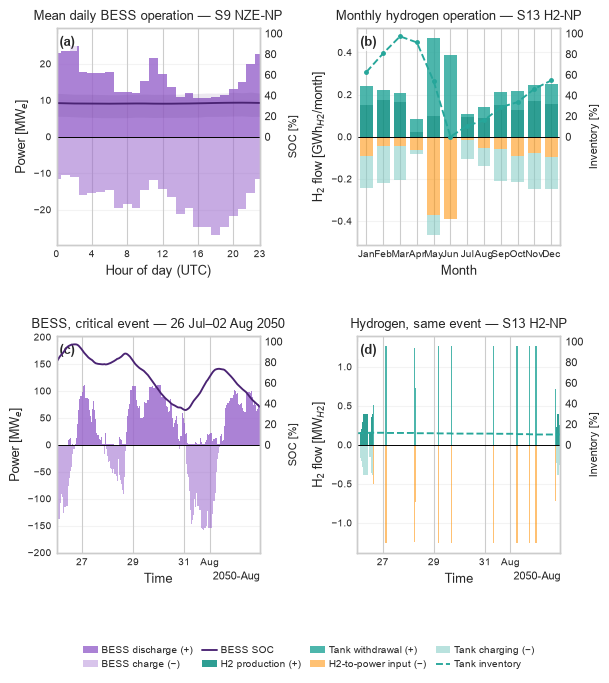

BESS: 982.47 MW / 7859.78 MWh
H2 storage: tank=0.723 GWh_H2; UHS=0.000 GWh_H2


In [25]:
%%run_if all(code in scenario_results for code in ("NZE_interconnected_NP", "H2_interconnected_NP"))
# Multiscale BESS and hydrogen/UHS operation panel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ── Configuration ─────────────────────────────────────────────────────────────
operation_year = detailed_year

BESS_SCENARIO = "NZE_interconnected_NP"
H2_SCENARIO = "H2_interconnected_NP"

# Use both as "H2_interconnected_NP" to analyse BESS and H2 within the same system.
n_bess = scenario_results[BESS_SCENARIO]["results"][operation_year]["network"]
n_h2 = scenario_results[H2_SCENARIO]["results"][operation_year]["network"]

event_start = pd.Timestamp(critical_event_start)
event_end = pd.Timestamp(critical_event_end)

if event_start.tz is not None:
    event_start = event_start.tz_localize(None)

if event_end.tz is not None:
    event_end = event_end.tz_localize(None)

tech_colors = globals().get("TECH_COLORS", {})
small_font = globals().get("FONT_SIZE_SMALL", 8)
figure_width = globals().get("WORD_DOUBLE_COL_IN", 7.2)

colors = {
    "BESS discharge": tech_colors.get("bess", "#8e5cc7"),
    "BESS charge": tech_colors.get("bess", "#8e5cc7"),
    "BESS SOC": "#4a2373",
    "H2 production": tech_colors.get("electrolyzer", "#00897b"),
    "Tank withdrawal": tech_colors.get("hydrogen_storage", "#26a69a"),
    "UHS withdrawal": tech_colors.get("uhs_withdrawal", "#3949ab"),
    "H2-to-power input": tech_colors.get("h2_fuel_cell", "#ff8f00"),
    "Tank charging": "#80cbc4",
    "UHS injection": tech_colors.get("uhs_injection", "#64b5f6"),
    "Tank inventory": tech_colors.get("hydrogen_storage", "#00897b"),
    "UHS inventory": tech_colors.get("uhs_storage", "#8e24aa"),
}


# ── Extraction helpers ────────────────────────────────────────────────────────
def _normalise(values):
    out = values.copy()
    out.index = pd.DatetimeIndex(
        pd.to_datetime(out.index)
    )

    if out.index.tz is not None:
        out.index = out.index.tz_localize(None)

    return out.sort_index()


def _zero(net):
    return _normalise(
        pd.Series(
            0.0,
            index=net.snapshots,
        )
    )


def _link_flow(
    net,
    carriers,
    port,
):
    """
    Return positive link input at p0 or useful output at p1 [MW].
    """
    links = net.links.index[
        net.links["carrier"]
        .astype(str)
        .isin(carriers)
    ]

    if len(links) == 0:
        return _zero(net)

    values = getattr(
        net.links_t,
        port,
    ).reindex(
        index=net.snapshots,
        columns=links,
        fill_value=0.0,
    )

    # PyPSA p1 is negative when energy leaves the link.
    if port == "p1":
        values = -values

    return _normalise(
        values.clip(lower=0.0).sum(axis=1)
    )


def _effective_capacity(
    table,
    index,
    optimised_column,
    fixed_column,
):
    fixed = pd.to_numeric(
        table.loc[index, fixed_column],
        errors="coerce",
    ).fillna(0.0)

    if optimised_column not in table.columns:
        return fixed

    optimised = pd.to_numeric(
        table.loc[index, optimised_column],
        errors="coerce",
    )

    return optimised.fillna(fixed)


def _store_data(
    net,
    carrier,
):
    """
    Return discharge, charging, inventory percentage, and capacity.

    Store p > 0: discharge.
    Store p < 0: charging.
    """
    stores = net.stores.index[
        net.stores["carrier"].astype(str) == carrier
    ]

    if len(stores) == 0:
        zero = _zero(net)

        return (
            zero,
            zero.copy(),
            zero * np.nan,
            0.0,
        )

    power = net.stores_t.p.reindex(
        index=net.snapshots,
        columns=stores,
        fill_value=0.0,
    )

    inventory = (
        net.stores_t.e
        .reindex(
            index=net.snapshots,
            columns=stores,
            fill_value=0.0,
        )
        .sum(axis=1)
    )

    energy_capacity = _effective_capacity(
        net.stores,
        stores,
        "e_nom_opt",
        "e_nom",
    ).sum()

    discharge = (
        power
        .clip(lower=0.0)
        .sum(axis=1)
    )

    charging = -(
        power
        .clip(upper=0.0)
        .sum(axis=1)
    )

    if energy_capacity > 0.0:
        inventory_pct = (
            100.0
            * inventory
            / energy_capacity
        )
    else:
        inventory_pct = inventory * np.nan

    return (
        _normalise(discharge),
        _normalise(charging),
        _normalise(inventory_pct),
        float(energy_capacity),
    )


# ── BESS operation ────────────────────────────────────────────────────────────
bess_carrier = (
    n_bess.storage_units["carrier"]
    .astype(str)
    .str.lower()
)

bess_units = n_bess.storage_units.index[
    bess_carrier.str.contains(
        r"bess|battery",
        regex=True,
    )
]

# Compatibility with older networks using a generic carrier.
if len(bess_units) == 0:
    bess_units = n_bess.storage_units.index

if len(bess_units) == 0:
    raise ValueError(
        f"No BESS StorageUnits found in "
        f"{BESS_SCENARIO}, {operation_year}."
    )

bess_power_by_unit = (
    n_bess.storage_units_t.p
    .reindex(
        index=n_bess.snapshots,
        columns=bess_units,
        fill_value=0.0,
    )
)

bess_soc_mwh = (
    n_bess.storage_units_t.state_of_charge
    .reindex(
        index=n_bess.snapshots,
        columns=bess_units,
        fill_value=0.0,
    )
    .sum(axis=1)
)

bess_p_nom = _effective_capacity(
    n_bess.storage_units,
    bess_units,
    "p_nom_opt",
    "p_nom",
)

bess_max_hours = pd.to_numeric(
    n_bess.storage_units.loc[
        bess_units,
        "max_hours",
    ],
    errors="coerce",
).fillna(0.0)

bess_energy_mwh = float(
    (
        bess_p_nom
        * bess_max_hours
    ).sum()
)

if bess_energy_mwh <= 0.0:
    raise ValueError(
        f"{BESS_SCENARIO} has no installed BESS energy capacity "
        f"in {operation_year}."
    )

# Separate charging and discharging before aggregation.
bess_flow = _normalise(
    pd.DataFrame(
        {
            "BESS discharge": (
                bess_power_by_unit
                .clip(lower=0.0)
                .sum(axis=1)
            ),
            "BESS charge": (
                bess_power_by_unit
                .clip(upper=0.0)
                .sum(axis=1)
            ),
        }
    )
)

bess_soc = _normalise(
    100.0
    * bess_soc_mwh
    / bess_energy_mwh
)


# ── Hydrogen/UHS operation ────────────────────────────────────────────────────
(
    tank_withdrawal,
    tank_charging,
    tank_inventory,
    tank_capacity_mwh,
) = _store_data(
    n_h2,
    "hydrogen_storage",
)

(
    _,
    _,
    uhs_inventory,
    uhs_capacity_mwh,
) = _store_data(
    n_h2,
    "uhs_storage",
)

# All flows are expressed on the H2-energy side:
# sources positive; storage/reconversion uses negative.
h2_flow = _normalise(
    pd.DataFrame(
        {
            "H2 production": _link_flow(
                n_h2,
                [
                    "electrolyzer",
                    "electrolyser",
                ],
                "p1",
            ),
            "Tank withdrawal": tank_withdrawal,
            "UHS withdrawal": _link_flow(
                n_h2,
                ["uhs_withdrawal"],
                "p1",
            ),
            "H2-to-power input": -(
                _link_flow(
                    n_h2,
                    ["h2_fuel_cell"],
                    "p0",
                )
                + _link_flow(
                    n_h2,
                    ["h2_turbine"],
                    "p0",
                )
            ),
            "Tank charging": -tank_charging,
            "UHS injection": -_link_flow(
                n_h2,
                ["uhs_injection"],
                "p0",
            ),
        }
    ).fillna(0.0)
)

h2_inventory = _normalise(
    pd.DataFrame(
        {
            "Tank inventory": tank_inventory,
            "UHS inventory": uhs_inventory,
        }
    )
)

if h2_flow.abs().sum().sum() <= 1e-6:
    raise ValueError(
        f"{H2_SCENARIO} has no H2/UHS operation in "
        f"{operation_year}. Select another scenario or verify "
        "that hydrogen capacity was actually built."
    )


# ── Mean daily BESS profile ───────────────────────────────────────────────────
bess_daily = bess_flow.copy()
bess_daily["SOC"] = bess_soc
bess_daily["hour"] = (
    bess_daily.index.hour
    + bess_daily.index.minute / 60.0
)

bess_mean = (
    bess_daily
    .groupby("hour")
    .mean()
)

bess_soc_q25 = (
    bess_daily
    .groupby("hour")["SOC"]
    .quantile(0.25)
)

bess_soc_q75 = (
    bess_daily
    .groupby("hour")["SOC"]
    .quantile(0.75)
)


# ── Monthly hydrogen flows ────────────────────────────────────────────────────
snapshot_duration = (
    h2_flow.index.to_series().shift(-1)
    - h2_flow.index.to_series()
)

typical_duration = (
    snapshot_duration
    .dropna()
    .median()
)

if pd.isna(typical_duration):
    typical_duration = pd.Timedelta(hours=1)

snapshot_duration.iloc[-1] = typical_duration

snapshot_hours = (
    snapshot_duration
    .dt.total_seconds()
    / 3600.0
)

h2_monthly = (
    h2_flow
    .mul(
        snapshot_hours,
        axis=0,
    )
    .groupby(
        h2_flow.index.month
    )
    .sum()
    .reindex(
        range(1, 13),
        fill_value=0.0,
    )
    / 1e3
)

h2_inventory_monthly = (
    h2_inventory
    .groupby(
        h2_inventory.index.month
    )
    .last()
    .reindex(range(1, 13))
    .ffill()
)


# ── Critical-event data ───────────────────────────────────────────────────────
bess_event_mask = (
    (bess_flow.index >= event_start)
    & (bess_flow.index <= event_end)
)

h2_event_mask = (
    (h2_flow.index >= event_start)
    & (h2_flow.index <= event_end)
)

bess_event = bess_flow.loc[
    bess_event_mask
]

bess_soc_event = bess_soc.loc[
    bess_event_mask
]

h2_event = h2_flow.loc[
    h2_event_mask
]

h2_inventory_event = h2_inventory.loc[
    h2_event_mask
]

if bess_event.empty or h2_event.empty:
    raise ValueError(
        "The critical-event dates do not overlap "
        "the selected networks."
    )


# ── Plot helpers ──────────────────────────────────────────────────────────────
def _stack_signed(
    ax,
    frame,
    bars=False,
):
    """
    Stack positive and negative flows independently.

    Positive: production, discharge, withdrawal.
    Negative: charging, injection, reconversion input.
    """
    x = (
        np.arange(1, 13)
        if bars
        else frame.index
    )

    positive_bottom = np.zeros(
        len(frame)
    )

    negative_bottom = np.zeros(
        len(frame)
    )

    for column in frame.columns:
        raw = (
            frame[column]
            .fillna(0.0)
            .to_numpy()
        )

        positive = raw.sum() >= 0.0

        values = np.clip(
            raw if positive else -raw,
            0.0,
            None,
        )

        if values.sum() <= 1e-9:
            continue

        bottom = (
            positive_bottom
            if positive
            else negative_bottom
        )

        alpha = (
            0.82
            if positive
            else 0.55
        )

        if bars:
            ax.bar(
                x,
                values if positive else -values,
                bottom=(
                    bottom
                    if positive
                    else -bottom
                ),
                width=0.76,
                color=colors[column],
                alpha=alpha,
                linewidth=0.0,
            )
        else:
            ax.fill_between(
                x,
                (
                    bottom
                    if positive
                    else -bottom
                ),
                (
                    bottom + values
                    if positive
                    else -(bottom + values)
                ),
                step="mid",
                color=colors[column],
                alpha=alpha,
                linewidth=0.0,
            )

        if positive:
            positive_bottom += values
        else:
            negative_bottom += values

    # Symmetric primary axis: zero remains at the vertical centre.
    limit = max(
        positive_bottom.max(),
        negative_bottom.max(),
        1e-6,
    )

    ax.set_ylim(
        -1.10 * limit,
        1.10 * limit,
    )


def _format_percentage_axis(
    ax,
    ylabel,
):
    """
    Align 0% with 0 on the symmetric primary axis.

    The negative half is retained internally for alignment but
    negative percentage ticks are not displayed.
    """
    ax.set_ylim(
        -105.0,
        105.0,
    )

    ax.set_yticks(
        [0, 20, 40, 60, 80, 100]
    )

    ax.set_ylabel(
        ylabel,
        fontsize=small_font,
    )

    ax.grid(False)


def _plot_inventory(
    ax,
    inventory,
    x=None,
):
    active = []

    for column, linestyle in [
        ("Tank inventory", "--"),
        ("UHS inventory", "-"),
    ]:
        if inventory[column].notna().sum() == 0:
            continue

        xx = (
            inventory.index
            if x is None
            else x
        )

        ax.plot(
            xx,
            inventory[column],
            color=colors[column],
            linestyle=linestyle,
            linewidth=1.35,
            marker=(
                "o"
                if x is not None
                else None
            ),
            markersize=2.5,
        )

        active.append(column)

    _format_percentage_axis(
        ax,
        "Inventory [%]",
    )

    return active


def _scenario_label(code):
    if code in SCENARIO_TECH_LABELS:
        return SCENARIO_TECH_LABELS[code]

    return code.replace(
        "_base",
        "",
    )


def _add_panel_label(
    ax,
    text,
):
    if callable(
        globals().get("panel_label")
    ):
        panel_label(
            ax,
            text,
        )
    else:
        ax.text(
            0.01,
            0.98,
            text,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontweight="bold",
        )


# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        figure_width,
        7.0,
    ),
)

ax_a, ax_b, ax_c, ax_d = axes.ravel()


# (a) Mean daily BESS operation
_stack_signed(
    ax_a,
    bess_mean[
        [
            "BESS discharge",
            "BESS charge",
        ]
    ],
)

ax_a_soc = ax_a.twinx()

ax_a_soc.fill_between(
    bess_mean.index,
    bess_soc_q25,
    bess_soc_q75,
    color=colors["BESS SOC"],
    alpha=0.10,
    linewidth=0.0,
)

ax_a_soc.plot(
    bess_mean.index,
    bess_mean["SOC"],
    color=colors["BESS SOC"],
    linewidth=1.35,
)

_format_percentage_axis(
    ax_a_soc,
    "SOC [%]",
)

ax_a.set_xlim(
    0.0,
    23.0,
)

ax_a.set_xticks(
    [0, 4, 8, 12, 16, 20, 23]
)

ax_a.set_xlabel(
    "Hour of day (UTC)"
)

ax_a.set_ylabel(
    r"Power [MW$_e$]"
)

ax_a.set_title(
    (
        "Mean daily BESS operation — "
        f"{_scenario_label(BESS_SCENARIO)}"
    ),
    fontsize=small_font + 1,
)

_add_panel_label(
    ax_a,
    "(a)",
)


# (b) Monthly hydrogen/UHS operation
_stack_signed(
    ax_b,
    h2_monthly,
    bars=True,
)

ax_b_inventory = ax_b.twinx()

active_inventory = _plot_inventory(
    ax_b_inventory,
    h2_inventory_monthly,
    x=np.arange(1, 13),
)

ax_b.set_xticks(
    np.arange(1, 13),
    [
        "Jan", "Feb", "Mar",
        "Apr", "May", "Jun",
        "Jul", "Aug", "Sep",
        "Oct", "Nov", "Dec",
    ],
)

ax_b.set_xlim(
    0.45,
    12.55,
)

ax_b.set_xlabel(
    "Month"
)

ax_b.set_ylabel(
    r"H$_2$ flow [GWh$_{H2}$/month]"
)

ax_b.set_title(
    (
        "Monthly hydrogen operation — "
        f"{_scenario_label(H2_SCENARIO)}"
    ),
    fontsize=small_font + 1,
)

_add_panel_label(
    ax_b,
    "(b)",
)


# (c) BESS during the critical event
_stack_signed(
    ax_c,
    bess_event,
)

ax_c_soc = ax_c.twinx()

ax_c_soc.plot(
    bess_soc_event.index,
    bess_soc_event,
    color=colors["BESS SOC"],
    linewidth=1.35,
)

_format_percentage_axis(
    ax_c_soc,
    "SOC [%]",
)

ax_c.set_xlabel(
    "Time"
)

ax_c.set_ylabel(
    r"Power [MW$_e$]"
)

ax_c.set_title(
    (
        "BESS, critical event — "
        f"{event_start:%d %b}–{event_end:%d %b %Y}"
    ),
    fontsize=small_font + 1,
)

_add_panel_label(
    ax_c,
    "(c)",
)


# (d) Hydrogen/UHS during the same critical event
_stack_signed(
    ax_d,
    h2_event,
)

ax_d_inventory = ax_d.twinx()

_plot_inventory(
    ax_d_inventory,
    h2_inventory_event,
)

ax_d.set_xlabel(
    "Time"
)

ax_d.set_ylabel(
    r"H$_2$ flow [MW$_{H2}$]"
)

ax_d.set_title(
    (
        "Hydrogen, same event — "
        f"{_scenario_label(H2_SCENARIO)}"
    ),
    fontsize=small_font + 1,
)

_add_panel_label(
    ax_d,
    "(d)",
)


# Shared axis formatting
for ax in axes.ravel():
    ax.axhline(
        0.0,
        color="black",
        linewidth=0.7,
    )

    ax.grid(
        axis="y",
        alpha=0.22,
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        labelsize=small_font - 1,
    )

    ax.margins(
        x=0.0,
    )


# Critical-event date formatting
for ax in [
    ax_c,
    ax_d,
]:
    locator = mdates.AutoDateLocator(
        minticks=3,
        maxticks=5,
    )

    ax.xaxis.set_major_locator(
        locator
    )

    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(
            locator
        )
    )


# ── Shared legend ─────────────────────────────────────────────────────────────
legend_handles = [
    Patch(
        facecolor=colors["BESS discharge"],
        edgecolor="none",
        alpha=0.82,
        label="BESS discharge (+)",
    ),
    Patch(
        facecolor=colors["BESS charge"],
        edgecolor="none",
        alpha=0.38,
        label="BESS charge (−)",
    ),
    Line2D(
        [0],
        [0],
        color=colors["BESS SOC"],
        linewidth=1.35,
        label="BESS SOC",
    ),
]

for column in h2_flow.columns:
    if h2_flow[column].abs().sum() <= 1e-6:
        continue

    positive = h2_flow[column].sum() >= 0.0

    legend_handles.append(
        Patch(
            facecolor=colors[column],
            edgecolor="none",
            alpha=(
                0.82
                if positive
                else 0.55
            ),
            label=(
                f"{column} "
                f"({'+' if positive else '−'})"
            ),
        )
    )

for column, linestyle in [
    ("Tank inventory", "--"),
    ("UHS inventory", "-"),
]:
    if column not in active_inventory:
        continue

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=colors[column],
            linestyle=linestyle,
            linewidth=1.35,
            label=column,
        )
    )

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.012,
    ),
    ncol=4,
    frameon=False,
    fontsize=small_font - 1,
    columnspacing=1.0,
    handlelength=1.5,
    handletextpad=0.4,
)

fig.subplots_adjust(
    top=0.94,
    bottom=0.19,
    left=0.10,
    right=0.90,
    hspace=0.42,
    wspace=0.48,
)


# ── Export ────────────────────────────────────────────────────────────────────
if callable(
    globals().get("save_paper_figure")
):
    figure_path = save_paper_figure(
        fig,
        (
            "figure_storage_operation_multiscale_"
            f"{operation_year}.png"
        ),
    )

    print(
        f"Saved figure to: {figure_path}"
    )

plt.show()

print(
    f"BESS: {bess_p_nom.sum():.2f} MW / "
    f"{bess_energy_mwh:.2f} MWh"
)

print(
    f"H2 storage: tank={tank_capacity_mwh / 1e3:.3f} GWh_H2; "
    f"UHS={uhs_capacity_mwh / 1e3:.3f} GWh_H2"
)

## 10. Weather-year robustness (optional)

Set `RUN_ROBUSTNESS=True` to re-operate the fixed 2050 design of `H2_interconnected_NP` with the meteorological years 2016 to 2025
(cutouts `data/magallanes_<year>.nc`). This section loads the exported `network.nc` for the selected design; all standard analysis above remains CSV-based.


Using fixed capacities from scenario H2_interconnected_NP, model year 2050, optimised with weather year 2025.

Robustness run: H2_interconnected_NP, model year 2050, weather year 2016
Using existing cutout: data\magallanes_2016.nc
Updated VRE profiles for 13 generators.
Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter TimeLimit to value 21600
Set parameter MIPGap to value 0.02
Set parameter Threads to value 4

Robustness run: H2_interconnected_NP, model year 2050, weather year 2017
Using existing cutout: data\magallanes_2017.nc
Updated VRE profiles for 13 generators.
Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter TimeLimit to value 21600
Set parameter MIPGap to value 0.02
Set parameter Threads to value 4

Robustness run: H2_interconnected_NP, model year 2050, weather year 2018
Using existing cutout: data\magallanes_2018.nc
Updated VRE profiles for 13 generators.
Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter TimeLimit to value 21600
Set

,weather_year,model_year,status,condition,solver,objective,demand_gwh,wind_generation_gwh,solar_generation_gwh,thermal_generation_gwh,...,h2_store_energy_gwh,uhs_store_energy_gwh,electrolyzer_input_gwh,h2_fuel_cell_output_gwh,h2_turbine_output_gwh,uhs_injection_gwh,uhs_withdrawal_gwh,tx_capacity_mw,tx_gross_flow_gwh,tx_net_abs_flow_gwh
0,2016,2050,ok,optimal,gurobi,1.193058e+09,794.867,704.325,111.413,0.0,...,0.723,0.0,2.222,0.777,0.0,0.0,0.0,431.884,724.010,724.010
1,2017,2050,ok,optimal,gurobi,8.053781e+04,794.867,716.381,108.754,0.0,...,0.723,0.0,2.252,0.788,0.0,0.0,0.0,431.884,674.568,674.568
2,2018,2050,ok,optimal,gurobi,4.266393e+08,794.867,711.672,111.318,0.0,...,0.723,0.0,2.149,0.751,0.0,0.0,0.0,431.884,697.131,697.131
3,2019,2050,ok,optimal,gurobi,9.215085e+06,794.867,714.437,109.860,0.0,...,0.723,0.0,2.039,0.713,0.0,0.0,0.0,431.884,663.863,663.863
4,2020,2050,ok,optimal,gurobi,6.789369e+08,794.867,715.510,104.338,0.0,...,0.723,0.0,1.991,0.696,0.0,0.0,0.0,431.884,702.024,702.024
5,2021,2050,ok,optimal,gurobi,1.680720e+07,794.867,716.981,108.903,0.0,...,0.723,0.0,2.093,0.732,0.0,0.0,0.0,431.884,694.216,694.216
6,2022,2050,ok,optimal,gurobi,7.948879e+04,794.867,713.006,111.929,0.0,...,0.723,0.0,2.235,0.782,0.0,0.0,0.0,431.884,665.710,665.710
7,2023,2050,ok,optimal,gurobi,7.676428e+04,794.867,709.224,114.298,0.0,...,0.723,0.0,2.369,0.829,0.0,0.0,0.0,431.884,649.035,649.035
8,2024,2050,ok,optimal,gurobi,9.549188e+08,794.867,711.960,105.951,0.0,...,0.723,0.0,2.064,0.722,0.0,0.0,0.0,431.884,701.883,701.883
9,2025,2050,ok,optimal,gurobi,8.461461e+04,794.867,715.551,111.262,0.0,...,0.723,0.0,1.986,0.695,0.0,0.0,0.0,431.884,706.957,706.957


Saved robustness summary: output\output_magallanes\robustness\weather_robustness_H2_interconnected_NP_2050.csv


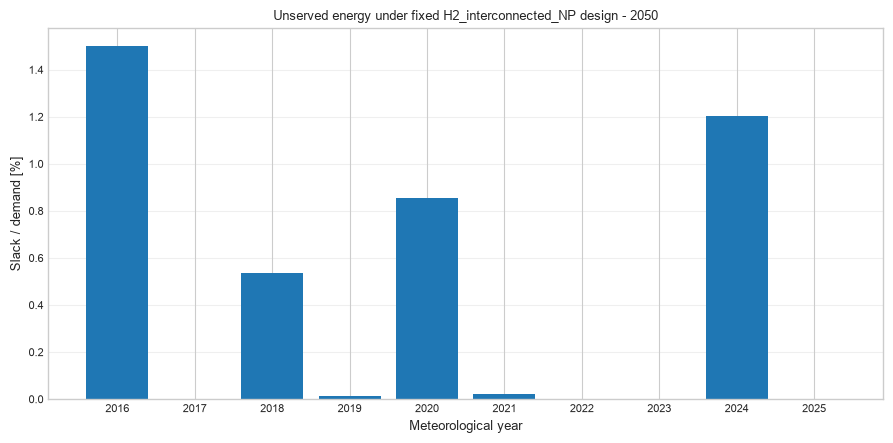

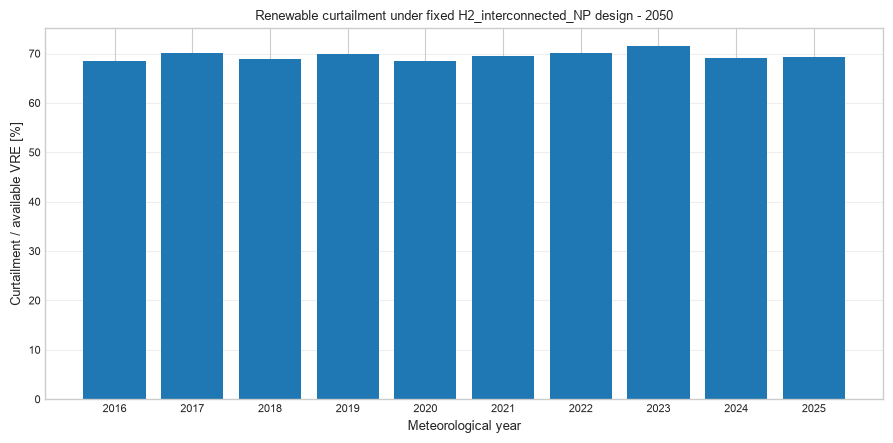

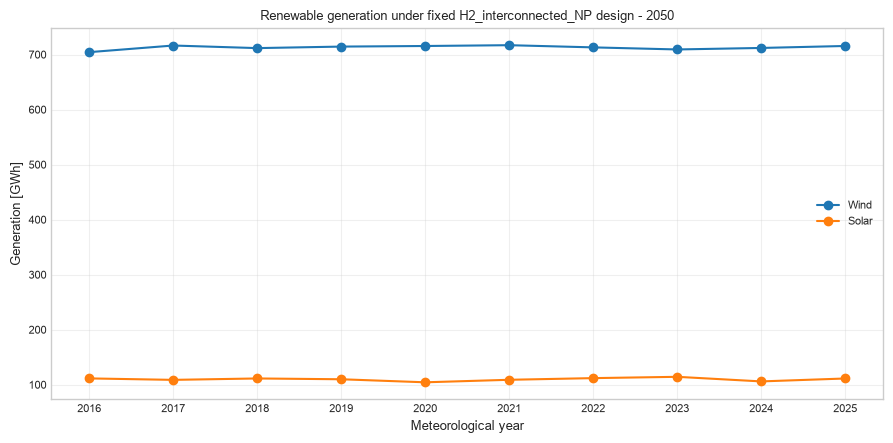

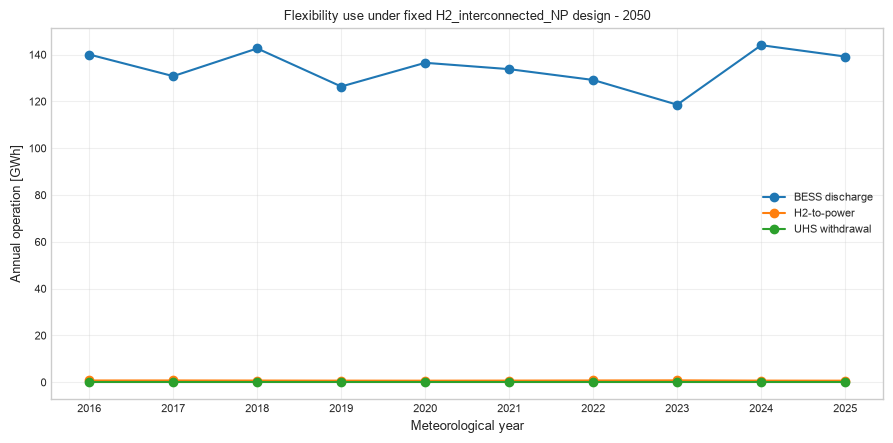

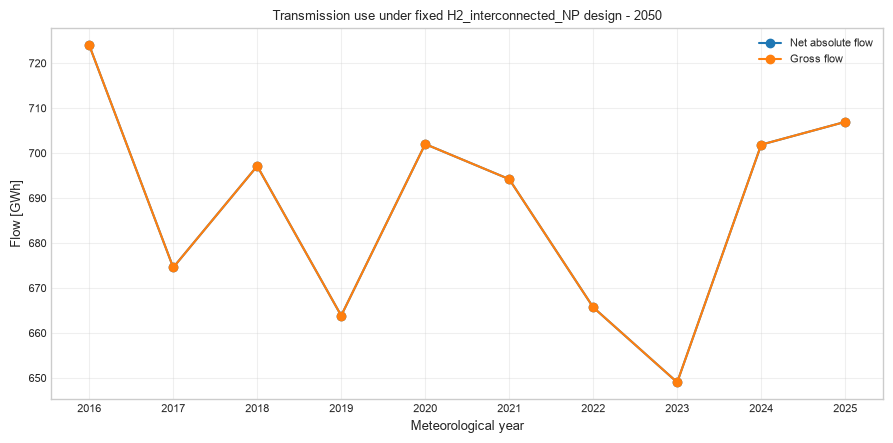

In [26]:
RUN_ROBUSTNESS = True


class RobustnessNotAvailable(RuntimeError):
    """The scenario, its network or a weather cutout is missing."""


def run_weather_year_robustness():
    """Re-operate a fixed optimized design across alternative weather years."""
    robustness_scenario_code = "H2_interconnected_NP"
    robustness_target_year = 2050
    robustness_weather_years = list(range(2016, 2026))

    robustness_cutout_base_dir = Path("data")
    robustness_cutout_prefix = "magallanes"

    solver_name_robustness = solver_name
    time_limit_robustness = time_limit
    mip_gap_robustness = mip_gap
    threads_robustness = threads
    fallback_to_highs_robustness = fallback_to_highs

    missing_cutouts = []

    for wy in robustness_weather_years:
        p = robustness_cutout_base_dir / f"{robustness_cutout_prefix}_{wy}.nc"
        if not p.exists():
            missing_cutouts.append(p)

    if missing_cutouts:
        raise RobustnessNotAvailable(
            "Some robustness cutouts are missing. Check the folder/path before running:\n"
            + "\n".join(str(p.resolve()) for p in missing_cutouts)
        )

    if robustness_scenario_code not in scenario_results:
        raise RobustnessNotAvailable(
            f"{robustness_scenario_code} not found in scenario_results. "
            "Run the selected robustness scenario before running this section."
        )

    base_package = scenario_results[robustness_scenario_code]
    base_result = base_package["results"][robustness_target_year]

    network_netcdf = base_result.get("network_netcdf")
    if network_netcdf is None or not Path(network_netcdf).exists():
        raise RobustnessNotAvailable(
            "The robustness run requires the exported network.nc file. "
            "Set EXPORT_NETWORK_NETCDF=True and rerun the selected base scenario."
        )

    base_net = pypsa.Network(network_netcdf)
    base_nodes = base_result["nodes"].load()

    critical_weather_year_used = base_result.get("weather_year", critical_weather_year)

    print(
        "\nUsing fixed capacities from "
        f"scenario {robustness_scenario_code}, "
        f"model year {robustness_target_year}, "
        f"optimised with weather year {critical_weather_year_used}."
    )

    def _copy_optimized_capacities_to_nominal(net):
        """
        Convert an optimised expansion network into a fixed-capacity operation network.

        This avoids deepcopy errors caused by solver/linopy/Gurobi objects stored
        inside net.model after optimisation.
        """
        with tempfile.TemporaryDirectory() as tmpdir:
            tmp_path = Path(tmpdir) / "fixed_capacity_template.nc"
            exported_path = export_network_netcdf_safe(net, tmp_path, strict=True)
            net_fixed = pypsa.Network(exported_path)

        net = net_fixed

        # Generators
        if len(net.generators) > 0:
            if "p_nom_opt" in net.generators.columns:
                mask = net.generators["p_nom_opt"].notna()
                net.generators.loc[mask, "p_nom"] = net.generators.loc[mask, "p_nom_opt"]

            if "p_nom_extendable" in net.generators.columns:
                net.generators["p_nom_extendable"] = False

        # StorageUnits, e.g. BESS
        if len(net.storage_units) > 0:
            if "p_nom_opt" in net.storage_units.columns:
                mask = net.storage_units["p_nom_opt"].notna()
                net.storage_units.loc[mask, "p_nom"] = net.storage_units.loc[mask, "p_nom_opt"]

            if "p_nom_extendable" in net.storage_units.columns:
                net.storage_units["p_nom_extendable"] = False

        # Links, e.g. transmission, electrolysers, fuel cells, H2 turbines
        if len(net.links) > 0:
            if "p_nom_opt" in net.links.columns:
                mask = net.links["p_nom_opt"].notna()
                net.links.loc[mask, "p_nom"] = net.links.loc[mask, "p_nom_opt"]

            if "p_nom_extendable" in net.links.columns:
                net.links["p_nom_extendable"] = False

        # Stores, e.g. H2 tank / UHS
        if len(net.stores) > 0:
            if "e_nom_opt" in net.stores.columns:
                mask = net.stores["e_nom_opt"].notna()
                net.stores.loc[mask, "e_nom"] = net.stores.loc[mask, "e_nom_opt"]

            if "e_nom_extendable" in net.stores.columns:
                net.stores["e_nom_extendable"] = False

        # Remove any old optimisation model if present
        if hasattr(net, "model"):
            try:
                delattr(net, "model")
            except Exception:
                pass

        return net

    def _replace_vre_profiles_for_weather_year(net, weather_year):
        """
        Replace wind and solar p_max_pu using an existing cutout:
        data/magallanes_{weather_year}.nc

        This bypasses config.get_case_cutout to avoid creating/downloading new cutouts.
        """
        cutout_path = robustness_cutout_base_dir / f"{robustness_cutout_prefix}_{weather_year}.nc"

        if not cutout_path.exists():
            raise FileNotFoundError(
                f"Cutout not found: {cutout_path.resolve()}\n"
                "Check robustness_cutout_base_dir and robustness_cutout_prefix."
            )

        print(f"Using existing cutout: {cutout_path}")

        cutout = atlite.Cutout(str(cutout_path))

        wind_cf_hist, solar_cf_hist = config.get_vre_profiles_from_cutout(
            cutout=cutout,
            nodes_df=base_nodes,
            method=vre_profile_method,
            wind_turbine=wind_turbine,
            solar_panel=solar_panel,
            solar_orientation=solar_orientation,
        )

        wind_cf = config.map_weather_year(wind_cf_hist, target_year=robustness_target_year)
        solar_cf = config.map_weather_year(solar_cf_hist, target_year=robustness_target_year)

        # Ensure all generator columns exist in p_max_pu
        if net.generators_t.p_max_pu.empty:
            net.generators_t.p_max_pu = pd.DataFrame(
                1.0,
                index=net.snapshots,
                columns=net.generators.index,
            )
        else:
            net.generators_t.p_max_pu = net.generators_t.p_max_pu.reindex(
                index=net.snapshots,
                columns=net.generators.index,
                fill_value=1.0,
            )

        # Replace only VRE profiles
        replaced = []

        for gen_id, row in net.generators.iterrows():
            carrier = str(row.get("carrier", "")).lower()
            zone = str(row.get("bus", "")).replace("elec_", "")

            if carrier == "wind" and zone in wind_cf.columns:
                net.generators_t.p_max_pu[gen_id] = (
                    wind_cf[zone].reindex(net.snapshots).fillna(0.0)
                )
                replaced.append(gen_id)

            elif carrier == "solar" and zone in solar_cf.columns:
                net.generators_t.p_max_pu[gen_id] = (
                    solar_cf[zone].reindex(net.snapshots).fillna(0.0)
                )
                replaced.append(gen_id)

        print(f"Updated VRE profiles for {len(replaced)} generators.")

        return net, wind_cf, solar_cf

    def _build_solver_options_for_robustness(target_solver):
        opts = {}

        if target_solver == "gurobi":
            if time_limit_robustness is not None:
                opts["TimeLimit"] = float(time_limit_robustness)
            if mip_gap_robustness is not None:
                opts["MIPGap"] = float(mip_gap_robustness)
            if threads_robustness is not None:
                opts["Threads"] = int(threads_robustness)

            opts["OutputFlag"] = 0
            opts["LogToConsole"] = 0

        elif target_solver == "highs":
            if time_limit_robustness is not None:
                opts["time_limit"] = float(time_limit_robustness)
            if mip_gap_robustness is not None:
                opts["mip_rel_gap"] = float(mip_gap_robustness)
            if threads_robustness is not None:
                opts["threads"] = int(threads_robustness)

        return opts

    def _run_fixed_capacity_operation(net):
        """
        Optimise operation only, with all capacities fixed.
        """
        opts = _build_solver_options_for_robustness(solver_name_robustness)

        optimize_kwargs = {"solver_name": solver_name_robustness}
        if opts:
            optimize_kwargs["solver_options"] = opts

        extra_fun = getattr(config, "add_custom_constraints", None)

        try:
            if extra_fun is not None:
                status, condition = net.optimize(
                    extra_functionality=extra_fun,
                    **optimize_kwargs,
                )
            else:
                status, condition = net.optimize(**optimize_kwargs)

            used_solver = solver_name_robustness

        except Exception as exc:
            if fallback_to_highs_robustness and solver_name_robustness == "gurobi":
                print(f"Gurobi failed during robustness run: {exc}. Trying HiGHS.")

                fallback_kwargs = {"solver_name": "highs"}
                fallback_opts = _build_solver_options_for_robustness("highs")
                if fallback_opts:
                    fallback_kwargs["solver_options"] = fallback_opts

                if extra_fun is not None:
                    status, condition = net.optimize(
                        extra_functionality=extra_fun,
                        **fallback_kwargs,
                    )
                else:
                    status, condition = net.optimize(**fallback_kwargs)

                used_solver = "highs"
            else:
                raise

        return status, condition, used_solver

    def _generation_by_carrier(net):
        if len(net.generators) == 0:
            return pd.Series(dtype=float)

        gen = (
            net.generators_t.p
            .reindex(columns=net.generators.index, fill_value=0.0)
            .clip(lower=0.0)
        )
        carriers = net.generators["carrier"].astype(str)

        return gen.T.groupby(carriers).sum().T.sum().sort_values(ascending=False)

    def _vre_curtailment_mwh(net):
        if len(net.generators) == 0:
            return 0.0

        total_curtailment = 0.0

        for carrier in ["wind", "solar"]:
            gens = net.generators.index[
                net.generators["carrier"].astype(str).str.lower() == carrier
            ]

            for gen_id in gens:
                p_nom = float(net.generators.loc[gen_id, "p_nom"])
                available = (
                    net.generators_t.p_max_pu[gen_id]
                    .fillna(0.0)
                    .clip(lower=0.0)
                    * p_nom
                )
                actual = net.generators_t.p[gen_id].fillna(0.0).clip(lower=0.0)
                total_curtailment += float((available - actual).clip(lower=0.0).sum())

        return total_curtailment

    def _storage_metrics(net):
        bess_charge = 0.0
        bess_discharge = 0.0
        bess_energy_capacity = 0.0

        if len(net.storage_units) > 0:
            p = net.storage_units_t.p.reindex(
                columns=net.storage_units.index,
                fill_value=0.0,
            )
            bess_charge = float((-p.clip(upper=0.0)).sum().sum())
            bess_discharge = float(p.clip(lower=0.0).sum().sum())

            if "max_hours" in net.storage_units.columns:
                bess_energy_capacity = float(
                    (net.storage_units["p_nom"] * net.storage_units["max_hours"]).sum()
                )

        h2_store_energy = 0.0
        uhs_store_energy = 0.0

        if len(net.stores) > 0:
            for _, row in net.stores.iterrows():
                carrier = str(row.get("carrier", "")).lower()
                e_nom = float(row.get("e_nom", 0.0))

                if carrier == "hydrogen_storage":
                    h2_store_energy += e_nom
                elif carrier == "uhs_storage":
                    uhs_store_energy += e_nom

        return {
            "bess_charge_mwh": bess_charge,
            "bess_discharge_mwh": bess_discharge,
            "bess_energy_capacity_mwh": bess_energy_capacity,
            "h2_store_energy_mwh": h2_store_energy,
            "uhs_store_energy_mwh": uhs_store_energy,
        }

    def _h2_link_metrics(net):
        """
        Annual operation of hydrogen-related links.
        Positive p0 is input at bus0. Positive p1 is usually output at bus1
        with sign convention depending on PyPSA. We use p0 for consumption-side
        technologies and -p1 where useful for output-side energy.
        """
        out = {
            "electrolyzer_input_gwh": 0.0,
            "h2_fuel_cell_output_gwh": 0.0,
            "h2_turbine_output_gwh": 0.0,
            "uhs_injection_gwh": 0.0,
            "uhs_withdrawal_gwh": 0.0,
        }

        if len(net.links) == 0:
            return out

        p0 = net.links_t.p0.reindex(columns=net.links.index, fill_value=0.0)
        p1 = net.links_t.p1.reindex(columns=net.links.index, fill_value=0.0)

        for link_id, row in net.links.iterrows():
            carrier = str(row.get("carrier", "")).lower()

            if carrier == "electrolyzer":
                out["electrolyzer_input_gwh"] += float(p0[link_id].clip(lower=0.0).sum() / 1e3)

            elif carrier == "h2_fuel_cell":
                out["h2_fuel_cell_output_gwh"] += float((-p1[link_id]).clip(lower=0.0).sum() / 1e3)

            elif carrier == "h2_turbine":
                out["h2_turbine_output_gwh"] += float((-p1[link_id]).clip(lower=0.0).sum() / 1e3)

            elif carrier == "uhs_injection":
                out["uhs_injection_gwh"] += float(p0[link_id].clip(lower=0.0).sum() / 1e3)

            elif carrier == "uhs_withdrawal":
                out["uhs_withdrawal_gwh"] += float((-p1[link_id]).clip(lower=0.0).sum() / 1e3)

        return out

    def _transmission_metrics(net):
        if len(net.links) == 0:
            return {
                "tx_capacity_mw": 0.0,
                "tx_gross_flow_mwh": 0.0,
                "tx_net_abs_flow_mwh": 0.0,
            }

        tx = net.links[
            (net.links["carrier"].astype(str) == "electricity")
            & net.links["bus0"].astype(str).str.startswith("elec_")
            & net.links["bus1"].astype(str).str.startswith("elec_")
        ]

        if tx.empty:
            return {
                "tx_capacity_mw": 0.0,
                "tx_gross_flow_mwh": 0.0,
                "tx_net_abs_flow_mwh": 0.0,
            }

        p0 = net.links_t.p0.reindex(columns=tx.index, fill_value=0.0)

        # Avoid double-counting fwd/rev pair capacity
        counted_links = []
        for link_id in tx.index:
            name = str(link_id)
            if name.endswith("_rev") and f"{name[:-4]}_fwd" in tx.index:
                continue
            counted_links.append(link_id)

        tx_capacity = float(tx.loc[counted_links, "p_nom"].sum())

        # Gross flow counts all directed flows
        gross_flow = float(p0.clip(lower=0.0).sum().sum())

        # Net absolute flow for fwd/rev pairs where possible
        used = set()
        net_abs_flow = 0.0

        for link_id in tx.index:
            name = str(link_id)

            if name in used:
                continue

            if name.endswith("_fwd") and f"{name[:-4]}_rev" in tx.index:
                rev = f"{name[:-4]}_rev"
                net = p0[link_id].clip(lower=0.0) - p0[rev].clip(lower=0.0)
                net_abs_flow += float(net.abs().sum())
                used.add(link_id)
                used.add(rev)

            elif name.endswith("_rev") and f"{name[:-4]}_fwd" in tx.index:
                continue

            else:
                net_abs_flow += float(p0[link_id].clip(lower=0.0).sum())
                used.add(link_id)

        return {
            "tx_capacity_mw": tx_capacity,
            "tx_gross_flow_mwh": gross_flow,
            "tx_net_abs_flow_mwh": net_abs_flow,
        }

    def _summarise_robustness_result(net, weather_year, status, condition, used_solver):
        load_mwh = float(base_result["load"].sum().sum())

        gen_by_carrier = _generation_by_carrier(net)

        slack_mwh = float(
            gen_by_carrier[
                gen_by_carrier.index.astype(str).str.contains("slack", case=False)
            ].sum()
        )

        thermal_mwh = float(
            gen_by_carrier[
                gen_by_carrier.index.astype(str).str.lower().isin(
                    ["ocgt", "gas", "natural_gas", "diesel", "lpg"]
                )
            ].sum()
        )

        wind_mwh = float(
            gen_by_carrier[
                gen_by_carrier.index.astype(str).str.lower() == "wind"
            ].sum()
        )

        solar_mwh = float(
            gen_by_carrier[
                gen_by_carrier.index.astype(str).str.lower() == "solar"
            ].sum()
        )

        curtailment_mwh = _vre_curtailment_mwh(net)
        vre_available_mwh = wind_mwh + solar_mwh + curtailment_mwh

        storage = _storage_metrics(net)
        h2_links = _h2_link_metrics(net)
        tx = _transmission_metrics(net)

        objective = float(net.objective) if net.objective is not None else np.nan

        return {
            "weather_year": weather_year,
            "model_year": robustness_target_year,
            "status": status,
            "condition": condition,
            "solver": used_solver,
            "objective": objective,
            "demand_gwh": load_mwh / 1e3,
            "wind_generation_gwh": wind_mwh / 1e3,
            "solar_generation_gwh": solar_mwh / 1e3,
            "thermal_generation_gwh": thermal_mwh / 1e3,
            "slack_gwh": slack_mwh / 1e3,
            "slack_share_pct": 100.0 * slack_mwh / load_mwh if load_mwh > 0 else np.nan,
            "curtailment_gwh": curtailment_mwh / 1e3,
            "curtailment_share_vre_available_pct": (
                100.0 * curtailment_mwh / vre_available_mwh
                if vre_available_mwh > 0 else np.nan
            ),
            "bess_charge_gwh": storage["bess_charge_mwh"] / 1e3,
            "bess_discharge_gwh": storage["bess_discharge_mwh"] / 1e3,
            "bess_energy_capacity_gwh": storage["bess_energy_capacity_mwh"] / 1e3,
            "h2_store_energy_gwh": storage["h2_store_energy_mwh"] / 1e3,
            "uhs_store_energy_gwh": storage["uhs_store_energy_mwh"] / 1e3,
            "electrolyzer_input_gwh": h2_links["electrolyzer_input_gwh"],
            "h2_fuel_cell_output_gwh": h2_links["h2_fuel_cell_output_gwh"],
            "h2_turbine_output_gwh": h2_links["h2_turbine_output_gwh"],
            "uhs_injection_gwh": h2_links["uhs_injection_gwh"],
            "uhs_withdrawal_gwh": h2_links["uhs_withdrawal_gwh"],
            "tx_capacity_mw": tx["tx_capacity_mw"],
            "tx_gross_flow_gwh": tx["tx_gross_flow_mwh"] / 1e3,
            "tx_net_abs_flow_gwh": tx["tx_net_abs_flow_mwh"] / 1e3,
        }

    weather_robustness_results = {}
    weather_robustness_summary_rows = []

    for wy in robustness_weather_years:
        print(
            f"\nRobustness run: {robustness_scenario_code}, "
            f"model year {robustness_target_year}, weather year {wy}"
        )

        net_wy = _copy_optimized_capacities_to_nominal(base_net)
        net_wy, wind_cf_wy, solar_cf_wy = _replace_vre_profiles_for_weather_year(net_wy, wy)

        status, condition, used_solver = _run_fixed_capacity_operation(net_wy)

        weather_robustness_results[wy] = {
            "network": net_wy,
            "wind_cf": wind_cf_wy,
            "solar_cf": solar_cf_wy,
            "status": status,
            "condition": condition,
            "solver": used_solver,
        }

        summary_row = _summarise_robustness_result(
            net=net_wy,
            weather_year=wy,
            status=status,
            condition=condition,
            used_solver=used_solver,
        )
        weather_robustness_summary_rows.append(summary_row)

    weather_robustness_summary = (
        pd.DataFrame(weather_robustness_summary_rows)
        .sort_values("weather_year")
        .reset_index(drop=True)
    )

    display(weather_robustness_summary.round(3))

    robustness_output_csv = ROBUSTNESS_EXPORT_DIR / (
        f"weather_robustness_{robustness_scenario_code}_{robustness_target_year}.csv"
    )
    weather_robustness_summary.to_csv(robustness_output_csv, index=False)
    print(f"Saved robustness summary: {robustness_output_csv}")

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["slack_share_pct"],
    )
    ax.set_title(f"Unserved energy under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Slack / demand [%]")
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["curtailment_share_vre_available_pct"],
    )
    ax.set_title(f"Renewable curtailment under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Curtailment / available VRE [%]")
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["wind_generation_gwh"],
        marker="o",
        label="Wind",
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["solar_generation_gwh"],
        marker="o",
        label="Solar",
    )
    ax.set_title(f"Renewable generation under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Generation [GWh]")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["bess_discharge_gwh"],
        marker="o",
        label="BESS discharge",
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["h2_fuel_cell_output_gwh"]
        + weather_robustness_summary["h2_turbine_output_gwh"],
        marker="o",
        label="H2-to-power",
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["uhs_withdrawal_gwh"],
        marker="o",
        label="UHS withdrawal",
    )
    ax.set_title(f"Flexibility use under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Annual operation [GWh]")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["tx_net_abs_flow_gwh"],
        marker="o",
        label="Net absolute flow",
    )
    ax.plot(
        weather_robustness_summary["weather_year"].astype(str),
        weather_robustness_summary["tx_gross_flow_gwh"],
        marker="o",
        label="Gross flow",
    )
    ax.set_title(f"Transmission use under fixed {robustness_scenario_code} design - {robustness_target_year}")
    ax.set_xlabel("Meteorological year")
    ax.set_ylabel("Flow [GWh]")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
    return weather_robustness_results, weather_robustness_summary

if RUN_ROBUSTNESS:
    try:
        weather_robustness_results, weather_robustness_summary = run_weather_year_robustness()
    except RobustnessNotAvailable as exc:
        print(f"Robustness skipped: {exc}")
else:
    print(
        "Weather-year robustness is disabled. Set RUN_ROBUSTNESS = True to run it."
    )


,scenario,paper_label,model_year,model_objective_usd,full_annual_cost_usd,full_cost_local_demand_usd_per_mwh,full_cost_total_final_use_usd_per_mwh,local_demand_mwh,flexible_final_use_mwh,total_final_electricity_use_mwh,slack_energy_mwh,slack_cost_usd,slack_cost_share_pct,asce_local_demand_usd_per_mwh,asce_total_final_use_usd_per_mwh,asce_local_excluding_slack_usd_per_mwh,asce_total_excluding_slack_usd_per_mwh
0,BAU_disconnected,S1 BAU-D,2025,2.190376e+07,2.772933e+07,61.81,61.81,448587.16,0.0,448587.16,0.0,0.0,0.0,48.83,48.83,48.83,48.83
1,H2_disconnected,S10 H2-D,2025,2.190376e+07,2.772933e+07,61.81,61.81,448587.16,0.0,448587.16,0.0,0.0,0.0,48.83,48.83,48.83,48.83
2,H2_interconnected_N,S11 H2-N,2025,2.190376e+07,2.772933e+07,61.81,61.81,448587.16,0.0,448587.16,0.0,0.0,0.0,48.83,48.83,48.83,48.83
3,H2_interconnected_P,S12 H2-P,2025,2.190376e+07,2.772933e+07,61.81,61.81,448587.16,0.0,448587.16,0.0,0.0,0.0,48.83,48.83,48.83,48.83
4,H2_interconnected_NP,S13 H2-NP,2025,2.190376e+07,2.772933e+07,61.81,61.81,448587.16,0.0,448587.16,0.0,0.0,0.0,48.83,48.83,48.83,48.83
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,RE95_interconnected_NP,S5 RE95-NP,2050,5.714000e+07,9.040036e+07,113.73,113.73,794866.78,0.0,794866.78,0.0,0.0,0.0,71.89,71.89,71.89,71.89
61,NZE_disconnected,S6 NZE-D,2050,1.511663e+08,1.888170e+08,237.55,237.55,794866.78,0.0,794866.78,0.0,0.0,0.0,190.18,190.18,190.18,190.18
62,NZE_interconnected_N,S7 NZE-N,2050,1.481062e+08,1.857580e+08,233.70,233.70,794866.78,0.0,794866.78,0.0,0.0,0.0,186.33,186.33,186.33,186.33
63,NZE_interconnected_P,S8 NZE-P,2050,1.304337e+08,1.680762e+08,211.45,211.45,794866.78,0.0,794866.78,0.0,0.0,0.0,164.10,164.10,164.10,164.10


Saved figure: output\output_magallanes\figures\figure_average_system_cost_2050.png


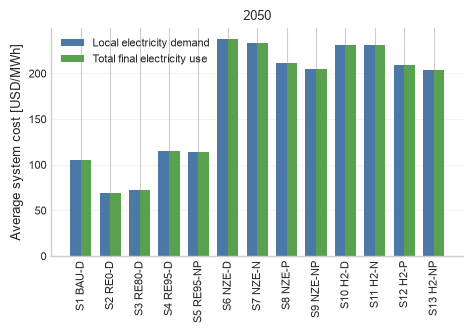

Saved system-cost summary to: output\output_magallanes\tables\average_system_cost_by_scenario.csv


In [27]:
# Average system cost of electricity by scenario and model year
#
# Indicators:
#   1. ASCE – local demand:
#      full annual cost / local electricity demand
#
#   2. ASCE – total final electricity use:
#      full annual cost / (local demand + PtX/flexible final uses)
#
# The full annual cost includes all active capacity and leaves out the penalty of unserved energy. The solver objective,
# kept in the table for reference, leaves out the capacity that already exists when the year starts.
#
# BESS/storage charging is excluded from final electricity use.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import FuncFormatter


# ── Configuration ─────────────────────────────────────────────────────────────
COST_CURRENCY = "USD"

# Flexible electricity uses counted as final consumption.
# Add another carrier here if necessary.
FINAL_USE_PATTERN = (
    r"electroly[sz]er|electrolysis|asu|dac|"
    r"ammonia|methanol|heat_pump|electric_heating"
)

# Storage charging is deliberately excluded from the denominator.
STORAGE_CHARGE_PATTERN = (
    r"bess|battery|storage|store|charge|pumped"
)

cost_plot_year = globals().get(
    "detailed_year",
    2050,
)


# ── Helpers ───────────────────────────────────────────────────────────────────
def _cost_scenario_label(scenario_code):
    if scenario_code in globals().get("SCENARIO_TECH_LABELS", {}):
        return SCENARIO_TECH_LABELS[scenario_code]

    if callable(
        globals().get(
            "_short_scenario_label"
        )
    ):
        return _short_scenario_label(
            scenario_code
        )

    text = (
        str(scenario_code)
        .upper()
        .replace("-", "_")
    )

    if "PTX" in text:
        return "PtX"

    for label in ["BAU", "RE0", "RE80", "RE95", "NZE", "H2"]:
        if label in text.split("_"):
            return label

    return (
        str(scenario_code)
        .replace("_base", "")
        .replace("_BASE", "")
    )


def _annual_snapshot_weights(net, index):
    """Return strictly one-dimensional objective weights."""

    snapshot_weightings = net.snapshot_weightings

    # Extract only the objective column
    try:
        raw_weights = snapshot_weightings["objective"]
    except (KeyError, TypeError, IndexError):
        try:
            raw_weights = snapshot_weightings.objective
        except AttributeError:
            raw_weights = snapshot_weightings

    values = np.asarray(
        raw_weights,
        dtype=float,
    )

    # Extra protection if three columns are still returned
    if values.ndim == 2:
        values = values[:, 0]

    values = values.reshape(-1)

    if len(values) != len(index):
        raise ValueError(
            "Snapshot-weight length mismatch: "
            f"{len(values)} weights for {len(index)} snapshots."
        )

    return pd.Series(
        values,
        index=index,
        dtype=float,
    )


def _local_electricity_load(result):
    """Return total local electricity demand [MW]."""
    load = result.get(
        "load"
    )

    if load is None:
        net = result["network"]

        load = getattr(
            net.loads_t,
            "p_set",
            pd.DataFrame(
                index=net.snapshots
            ),
        )

    if isinstance(
        load,
        pd.Series,
    ):
        output = load.copy()

    else:
        output = (
            load
            .apply(
                pd.to_numeric,
                errors="coerce",
            )
            .fillna(0.0)
            .sum(axis=1)
        )

    return (
        pd.to_numeric(
            output,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(lower=0.0)
    )


def _final_flexible_electricity_use(net):
    """
    Return PtX and other final flexible electricity uses [MW].

    Uses the previously defined electricity-balance helper.
    BESS and other storage charging are excluded.
    """
    if not callable(
        globals().get(
            "_electricity_balance_for_network"
        )
    ):
        return pd.Series(
            0.0,
            index=net.snapshots,
        )

    _, consumption = (
        _electricity_balance_for_network(
            net
        )
    )

    if consumption is None or consumption.empty:
        return pd.Series(
            0.0,
            index=net.snapshots,
        )

    consumption = (
        consumption
        .apply(
            pd.to_numeric,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(lower=0.0)
    )

    # Without PtX the electrolyzer only charges the hydrogen storage, so it is not a final use
    ptx_columns = consumption.columns.astype(str).str.contains(
        r"asu|dac|ammonia|methanol|ptx",
        case=False,
        regex=True,
    )
    has_ptx = bool(consumption.loc[:, ptx_columns].to_numpy().sum() > 0.0)

    final_use_columns = []

    for column in consumption.columns:
        carrier = str(
            column
        )

        is_final_use = bool(
            pd.Series([carrier])
            .str.contains(
                FINAL_USE_PATTERN,
                case=False,
                regex=True,
                na=False,
            )
            .iloc[0]
        )

        is_storage_charging = bool(
            pd.Series([carrier])
            .str.contains(
                STORAGE_CHARGE_PATTERN,
                case=False,
                regex=True,
                na=False,
            )
            .iloc[0]
        )

        if (
            is_final_use
            and not is_storage_charging
            and (has_ptx or "electroly" not in carrier.lower())
        ):
            final_use_columns.append(
                column
            )

    if not final_use_columns:
        return pd.Series(
            0.0,
            index=consumption.index,
        )

    return (
        consumption[
            final_use_columns
        ]
        .sum(axis=1)
    )


def _slack_cost_and_energy(net, weights):
    """Estimate slack generation and its variable cost."""
    if not hasattr(
        net,
        "generators",
    ):
        return 0.0, 0.0

    carriers = (
        net.generators.get(
            "carrier",
            pd.Series(
                "",
                index=net.generators.index,
            ),
        )
        .astype(str)
    )

    slack_generators = (
        net.generators.index[
            carriers.str.contains(
                "slack",
                case=False,
                na=False,
            )
        ]
    )

    generator_dispatch = getattr(
        net.generators_t,
        "p",
        pd.DataFrame(
            index=net.snapshots
        ),
    )

    slack_generators = [
        generator
        for generator in slack_generators
        if generator
        in generator_dispatch.columns
    ]

    if not slack_generators:
        return 0.0, 0.0

    slack_dispatch = (
        generator_dispatch[
            slack_generators
        ]
        .apply(
            pd.to_numeric,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(lower=0.0)
    )

    slack_energy_by_generator = (
        slack_dispatch
        .mul(
            weights,
            axis=0,
        )
        .sum(axis=0)
    )

    marginal_cost = (
        pd.to_numeric(
            net.generators.loc[
                slack_generators,
                "marginal_cost",
            ],
            errors="coerce",
        )
        .fillna(0.0)
    )

    slack_cost = float(
        (
            slack_energy_by_generator
            * marginal_cost
        ).sum()
    )

    slack_energy = float(
        slack_energy_by_generator.sum()
    )

    return (
        slack_cost,
        slack_energy,
    )


# ── Calculate indicators ─────────────────────────────────────────────────────
system_cost_rows = []

for scenario_code, scenario_package in scenario_results.items():

    for model_year, result in (
        scenario_package["results"].items()
    ):
        net = result["network"]

        local_load = (
            _local_electricity_load(
                result
            )
        )

        flexible_final_use = (
            _final_flexible_electricity_use(
                net
            )
        )

        flexible_final_use = (
            flexible_final_use
            .reindex(
                local_load.index
            )
            .fillna(0.0)
        )

        weights = _annual_snapshot_weights(
            net,
            local_load.index,
        )

        local_demand_mwh = float(
            (
                local_load
                * weights
            ).sum()
        )

        flexible_final_use_mwh = float(
            (
                flexible_final_use
                * weights
            ).sum()
        )

        total_final_use_mwh = (
            local_demand_mwh
            + flexible_final_use_mwh
        )

        objective_value = float(
            getattr(
                net,
                "objective",
                np.nan,
            )
        )

        full_annual_cost = full_annual_cost_usd(net)

        slack_cost_usd, slack_energy_mwh = (
            _slack_cost_and_energy(
                net,
                weights,
            )
        )

        system_cost_excluding_slack = (
            objective_value
            - slack_cost_usd
            if np.isfinite(objective_value)
            else np.nan
        )

        system_cost_rows.append(
            {
                "scenario": scenario_code,
                "paper_label": (
                    _cost_scenario_label(
                        scenario_code
                    )
                ),
                "model_year": int(
                    model_year
                ),
                "model_objective_usd": (
                    objective_value
                ),
                "full_annual_cost_usd": (
                    full_annual_cost
                ),
                "full_cost_local_demand_usd_per_mwh": (
                    full_annual_cost
                    / local_demand_mwh
                    if local_demand_mwh > 0.0
                    else np.nan
                ),
                "full_cost_total_final_use_usd_per_mwh": (
                    full_annual_cost
                    / total_final_use_mwh
                    if total_final_use_mwh > 0.0
                    else np.nan
                ),
                "local_demand_mwh": (
                    local_demand_mwh
                ),
                "flexible_final_use_mwh": (
                    flexible_final_use_mwh
                ),
                "total_final_electricity_use_mwh": (
                    total_final_use_mwh
                ),
                "slack_energy_mwh": (
                    slack_energy_mwh
                ),
                "slack_cost_usd": (
                    slack_cost_usd
                ),
                "slack_cost_share_pct": (
                    100.0
                    * slack_cost_usd
                    / objective_value
                    if objective_value > 0.0
                    else np.nan
                ),
                "asce_local_demand_usd_per_mwh": (
                    objective_value
                    / local_demand_mwh
                    if local_demand_mwh > 0.0
                    else np.nan
                ),
                "asce_total_final_use_usd_per_mwh": (
                    objective_value
                    / total_final_use_mwh
                    if total_final_use_mwh > 0.0
                    else np.nan
                ),
                "asce_local_excluding_slack_usd_per_mwh": (
                    system_cost_excluding_slack
                    / local_demand_mwh
                    if local_demand_mwh > 0.0
                    else np.nan
                ),
                "asce_total_excluding_slack_usd_per_mwh": (
                    system_cost_excluding_slack
                    / total_final_use_mwh
                    if total_final_use_mwh > 0.0
                    else np.nan
                ),
            }
        )


system_cost_summary = (
    pd.DataFrame(
        system_cost_rows
    )
    .sort_values(
        [
            "model_year",
            "paper_label",
        ]
    )
    .reset_index(drop=True)
)

display(
    system_cost_summary.round(2)
)


# ── Plot selected year ────────────────────────────────────────────────────────
plot_data = (
    system_cost_summary.loc[
        system_cost_summary[
            "model_year"
        ].eq(cost_plot_year)
    ]
    .copy()
)

scenario_order = {
    scenario_code: position
    for position, scenario_code
    in enumerate(SCENARIO_PLOT_ORDER)
}

plot_data["scenario_order"] = (
    plot_data["scenario"]
    .map(scenario_order)
    .fillna(99)
)

plot_data = (
    plot_data
    .sort_values(
        "scenario_order"
    )
)


fig, ax = plt.subplots(
    figsize=(
        globals().get(
            "WORD_SINGLE_COL_IN",
            4.8,
        ),
        3.4,
    )
)

x_positions = np.arange(
    len(plot_data)
)

bar_width = 0.36

ax.bar(
    x_positions - bar_width / 2,
    plot_data[
        "full_cost_local_demand_usd_per_mwh"
    ],
    width=bar_width,
    color="#4c78a8",
    label="Local electricity demand",
)

ax.bar(
    x_positions + bar_width / 2,
    plot_data[
        "full_cost_total_final_use_usd_per_mwh"
    ],
    width=bar_width,
    color="#59a14f",
    label="Total final electricity use",
)

ax.set_xticks(
    x_positions
)

ax.set_xticklabels(
    plot_data["paper_label"],
    rotation=90,
)

ax.set_ylabel(
    f"Average system cost [{COST_CURRENCY}/MWh]"
)

ax.set_title(
    str(cost_plot_year)
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    fontsize=8,
)

fig.tight_layout()

if callable(
    globals().get(
        "save_paper_figure"
    )
):
    average_cost_figure_path = (
        save_paper_figure(
            fig,
            (
                "figure_average_system_cost_"
                f"{cost_plot_year}.png"
            ),
        )
    )

plt.show()


# ── Export ────────────────────────────────────────────────────────────────────
table_export_dir = Path(
    globals().get(
        "TABLE_EXPORT_DIR",
        ".",
    )
)

table_export_dir.mkdir(
    parents=True,
    exist_ok=True,
)

system_cost_summary_path = (
    table_export_dir
    / "average_system_cost_by_scenario.csv"
)

system_cost_summary.to_csv(
    system_cost_summary_path,
    index=False,
)

print(
    "Saved system-cost summary to: "
    f"{system_cost_summary_path}"
)